# Predicting Next-Best-Product Adoption in Retail Banking from the First 90 Days of Transactions

**ANA540 Machine Learning: final project** | Anushree Das

## Abstract

Banks usually score customers for product offers from static snapshots and treat adoption as a yes/no outcome. This project uses the timestamped transaction stream of each customer's first 90 days with the bank (Berka PKDD'99 data, 4,303 accounts) to predict which product the customer takes within the following 365 days: a loan, a credit card, both, or neither. The problem is a four-class classification task with strong imbalance (about 86% `neither` overall, 1% `both`), right-censored observation and a shift between older and newer account cohorts, so models are trained on accounts opened in 1993-96 and tested on the 1997 cohort. Seven approaches are compared: a prior baseline, ElasticNet logistic regression, LightGBM, cause-specific Cox regression, Random Survival Forest, an RMTPP-style recurrent network on the raw event sequence, and an ensemble. They are optimized with time-aware cross-validation (hyperparameter search, feature engineering and selection, and a decision rule learned on out-of-fold predictions) and compared before and after tuning with accuracy, macro-F1, one-vs-rest AUC, per-class recall, PR-AUC and bootstrap confidence intervals. The quantitative results are summarized in Sections 4 and 6.

## Contents

| Section | Content |
|---|---|
| 1 | Introduction: research purpose, problem type, dataset, setup |
| 2 | Exploratory data analysis and data-quality checks |
| 3 | Problem formulation (fixed-horizon target), splits, preprocessing |
| 4 | Models and initial evaluation (baselines, survival models, GRU) |
| 5 | Model optimization (hyperparameters, feature engineering, decision rule) |
| 6 | Final evaluation on the 1997 test cohort and comparison with the initial models |
| 7 | Conclusions, limitations, references |

**How to run.** Keep `berka.zip` (or the extracted `berka/` folder containing the eight Berka CSV files) next to this notebook and run all cells from the top (if `berka/` is not present, Section 1.4 automatically extracts `berka.zip`). Requirements: `numpy`, `pandas`, `matplotlib`, `seaborn`, `scikit-learn`, `lightgbm`, `lifelines`, `scikit-survival`, `torch` (the GRU runs in a separate process, see Section 4). A complete run takes roughly 30-60 minutes on a laptop; set `FAST_MODE = True` in Section 5 for a few-minute check that every cell executes. Figures are saved to `figures/` and tables to `results/` as the notebook runs.

## 1. Introduction

### 1.1 Research purpose and questions

The purpose of this project is to build a **Next-Best-Product (NBP) model for retail banking** that anticipates which existing checking-account customers will go on to adopt a **loan, a credit card, both, or neither**. Banks typically score customers from static snapshots (monthly or quarterly aggregates) and treat adoption as a yes/no outcome. Here, the customer's raw, timestamped transaction stream from their first 90 days with the bank is used to predict their eventual product portfolio. The longer-term goal is to compare conventional tabular classifiers and survival models against a neural **Marked Temporal Point Process (RMTPP)** that works directly in continuous time, and to retain the *time to first adoption* as a second target so that the models can say *when* to make an offer, not just *to whom*. The study uses the Berka (PKDD'99) retail-banking dataset.

This matters for marketing and sales because offers are costly and customers who ignore them are a nuisance, so the bank wants to concentrate effort on customers who are about to need a product. The problem is hard for three reasons. First, adoption is **uneven**: about 31% of accounts adopt anything, and only about 4% adopt both products, so the four classes are strongly imbalanced. Second, observation ends in December 1998, so "neither" really means "not yet" (**right-censoring**). Third, the data are a real time series, so evaluation must respect time: models are trained on accounts opened in 1993–1996 and tested on the unseen 1997 cohort, which mirrors how a bank would deploy a model on new customers.

**Key questions**

1. Which behaviors in a customer's first 90 days (activity level, cash-flow, balance patterns, payment types, demographics, district context) distinguish customers who end up with *neither*, *loan only*, *card only*, or *both*?
2. How accurately can the four-class portfolio outcome be predicted compared with a majority-class baseline, and which model family (tabular ML, survival-based, neural MTPP) performs best on macro-F1, one-vs-rest AUC-ROC and per-class recall?
3. Does a continuous-time sequence model add value beyond hand-engineered aggregates, and how well can it rank customers by *time to first adoption* (concordance index)?
4. Is the model useful for targeting, for example lift in the top decile of predicted loan or card propensity, and does it hold up when applied to a later cohort of customers?

### 1.2 Type of machine learning problem

| Aspect | Choice |
|---|---|
| **Primary task** | **Multiclass classification** of final product status: `neither`, `loan_only`, `card_only`, `both` |
| **Secondary task** | **Time-to-event (survival) prediction** of the first adoption, with right-censoring (used by the Cox, Random Survival Forest and RMTPP-style models in Section 4) |
| **Unit of analysis** | One bank account (4,500 accounts), observed from a fixed **90-day landmark** after opening |
| **Models** | Prior baseline, ElasticNet multinomial logistic regression and LightGBM (tabular); cause-specific Cox and Random Survival Forest (survival); RMTPP-style GRU in PyTorch (neural point process) |

### 1.3 Dataset description

**Source.** The Berka dataset was released for the PKDD'99 Discovery Challenge by Petr Berka and is a real, anonymized extract from a Czech bank. It is widely mirrored (for example on Kaggle and the CTU Relational Dataset Repository); this project uses the eight CSV files in `berka.zip`. It describes about 5,300 clients, 4,500 accounts, 682 loans, 892 credit cards and over one million transactions between January 1993 and December 1998.

**Relevance.** The dataset has what a continuous-time next-best-product study needs and most public banking datasets lack: exact transaction dates and amounts for every account, together with dated loan and card records. That allows adoption to be defined as an event in time, observed against a customer's behavior history, and censored when the observation window ends. It also supports the project's "adopt one, both, or neither" framing directly (loan and card records are independent tables). The Santander Product Recommendation dataset is larger but only monthly, so it cannot support a continuous-time formulation.

**Context and critical evaluation.** The data cover accounts opened 1993–1997 across 77 Czech districts, with transactions observed until 31 December 1998. Limitations to keep in mind: (i) only 4,500 accounts, which is small for a neural model; (ii) a single bank, country and decade; (iii) a loan or card is the outcome of the *bank's approval* as well as the customer's interest, and there is no marketing-contact data, so we model *adoption*, not *response to an offer*; (iv) observation stops in 1998, so later cohorts have shorter follow-up and "neither" includes customers who might adopt later; and (v) several post-adoption traces sit in the transaction table (loan repayments, card withdrawals), which would leak the answer if the full history were used (shown in Section 2.6).

**Tables and attributes used.** Czech codes are decoded below. Columns I plan to use as predictors are marked ✔; "outcome" columns define the target; "excluded" columns are dropped for the reason stated.

| Table | Column | Type | Meaning / unique characteristics | Use |
|---|---|---|---|---|
| `account` | `account_id`, `district_id` | id | Account key; branch district | key |
| | `frequency` | categorical | Statement issuance: monthly (`POPLATEK MESICNE`), weekly (`POPLATEK TYDNE`), after each transaction (`POPLATEK PO OBRATU`) | ✔ |
| | `date` | date (YYMMDD) | Account opening date (1993–1997); defines the time origin | time origin |
| `client` | `birth_number` | encoded string | `YYMMDD`; month +50 for women, so it yields age at opening and gender | ✔ (age, gender) |
| `disp` | `type` | categorical | `OWNER` or `DISPONENT` (authorized user); links clients, accounts and cards | ✔ (has disponent) |
| `district` | `A2`–`A16` | numeric/categorical | Region, population, urban ratio, average salary, unemployment 1995/96, entrepreneurs per 1,000, crimes 1995/96. District 69 has `?` for two fields | ✔ |
| `trans` | `date` | date | Transaction date (event time) | ✔ |
| | `type` | categorical | `PRIJEM` credit, `VYDAJ` debit, `VYBER` withdrawal (legacy label) | ✔ (mark) |
| | `operation` | categorical | `VKLAD` cash deposit, `VYBER` cash withdrawal, `PREVOD NA UCET` transfer out, `PREVOD Z UCTU` transfer in, `VYBER KARTOU` card withdrawal; blank for interest credits | ✔ (mark) |
| | `k_symbol` | categorical | Purpose: `DUCHOD` pension, `POJISTNE` insurance, `SLUZBY` fees, `SIPO` household payment, `UROK` interest, `SANKC. UROK` penalty interest, `UVER` loan repayment | ✔ (but `UVER` is leakage) |
| | `amount`, `balance` | numeric (CZK) | Transaction size and balance after it; heavy right tail; some negative balances | ✔ |
| | `bank`, `account` | categorical | Counterparty identifiers (about 72–74% missing, filled only for transfers) | excluded (sparse, identifiers) |
| `loan` | `date` | date | Loan granting date | outcome |
| | `amount`, `duration`, `payments`, `status` | numeric / categorical | Loan terms and repayment status (A, B, C, D) | excluded (consequences of the loan) |
| `card` | `issued`, `type` | date / categorical | Card issue date; `junior`, `classic`, `gold` | outcome (`type` excluded) |
| `order` | all | mixed | Standing orders; **no dates**, and includes loan-payment orders | excluded (undated, leaks loan) |

### 1.4 Setup and data loading

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid", context="notebook")

RANDOM_STATE = 42
DATA_DIR = Path("berka")        # folder containing the 8 CSV files from berka.zip
if not DATA_DIR.exists() and Path("berka.zip").exists():
    import zipfile
    with zipfile.ZipFile("berka.zip", "r") as _z:
        _z.extractall(".")

LANDMARK_DAYS = 90                         # prediction time = account opening + 90 days
OBS_END = pd.Timestamp("1998-12-31")       # last day of data (right-censoring date)
CLASS_NAMES = ["neither", "loan_only", "card_only", "both"]

# ---- figures and tables for the report are saved as the notebook runs
FIG_DIR, RES_DIR = Path("figures"), Path("results")
FIG_DIR.mkdir(exist_ok=True); RES_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"savefig.dpi": 300, "savefig.bbox": "tight", "font.size": 10, "axes.titlesize": 11})
def save_fig(name):
    # call after tight_layout() and before plt.show(): writes figures/<name>.pdf and .png
    plt.savefig(FIG_DIR / f"{name}.pdf"); plt.savefig(FIG_DIR / f"{name}.png")
def save_table(df, name):
    df.to_csv(RES_DIR / f"{name}.csv")

In [2]:
def read_table(name):
    return pd.read_csv(DATA_DIR / f"{name}.csv", sep=";", low_memory=False)

account, card, client, disp = (read_table(n) for n in ["account", "card", "client", "disp"])
district, loan, order, trans = (read_table(n) for n in ["district", "loan", "order", "trans"])

# Dates are stored as YYMMDD numbers (card dates carry a trailing "00:00:00")
to_date = lambda s: pd.to_datetime(s.astype(str).str[:6], format="%y%m%d")
account["date"] = to_date(account["date"])
loan["date"] = to_date(loan["date"])
card["issued"] = to_date(card["issued"])
trans["date"] = to_date(trans["date"])

tables = {"account": account, "card": card, "client": client, "disp": disp,
          "district": district, "loan": loan, "order": order, "trans": trans}

## 2. Exploratory data analysis (EDA)

This section explores the raw tables and the first-90-day behavior of every account, and documents the data-quality checks. Status here is the *end-of-data* status (what each account holds on 31 December 1998); Section 3 explains why the modelling target is redefined as a fixed-horizon label.

### 2.1 Sample size and basic information

,rows,columns
account,4500,4
card,892,4
client,5369,3
disp,5369,4
district,77,16
loan,682,7
order,6471,6
trans,1056320,10


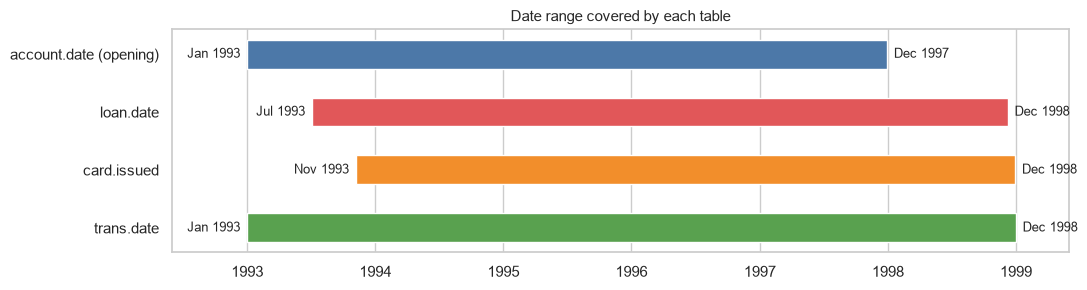

Derived stats:


,count
accounts,4500
accounts with transactions,4500
clients,5369
owners,4500
disponents (authorized users),869
max loans per account,1
max cards per account,1


In [3]:
import matplotlib.dates as mdates

overview = pd.DataFrame({"rows": {k: len(v) for k, v in tables.items()},
                         "columns": {k: v.shape[1] for k, v in tables.items()}})
display(overview)

date_cols = {"account.date (opening)": account["date"], "loan.date": loan["date"],
             "card.issued": card["issued"], "trans.date": trans["date"]}
ranges = pd.DataFrame({k: {"start": v.min(), "end": v.max()} for k, v in date_cols.items()}).T

fig, ax = plt.subplots(figsize=(11, 3))
colors = ["#4C78A8", "#E15759", "#F28E2B", "#59A14F"]
for i, ((name, r), col) in enumerate(zip(ranges.iterrows(), colors)):
    start, end = mdates.date2num(r["start"]), mdates.date2num(r["end"])
    ax.barh(i, end - start, left=start, height=0.5, color=col)
    ax.text(start - 20, i, f"{r['start']:%b %Y}", ha="right", va="center", fontsize=9)
    ax.text(end + 20, i, f"{r['end']:%b %Y}", ha="left", va="center", fontsize=9)
ax.set_yticks(range(len(ranges))); ax.set_yticklabels(ranges.index); ax.invert_yaxis()
ax.xaxis_date(); ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_xlim(mdates.date2num(pd.Timestamp("1992-06-01")), mdates.date2num(pd.Timestamp("1999-06-01")))
ax.set(title="Date range covered by each table"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

print("Derived stats:")
summary = pd.Series({
    "accounts": account["account_id"].nunique(),
    "accounts with transactions": trans["account_id"].nunique(),
    "clients": client["client_id"].nunique(),
    "owners": (disp["type"] == "OWNER").sum(),
    "disponents (authorized users)": (disp["type"] == "DISPONENT").sum(),
    "max loans per account": loan.groupby("account_id").size().max(),
    "max cards per account": card.merge(disp, on="disp_id").groupby("account_id").size().max(),
})
summary.to_frame("count")

**Observations.** All 4,500 accounts have a transaction history and exactly one owner. 869 additional clients are authorized users (disponents). No account has more than one loan or one card, so adoption can be treated as a yes/no event per product.

### 2.2 Descriptive statistics

,count,mean,std,min,25%,50%,75%,max
amount,"1,056,320.00","5,924.15","9,522.74",0.00,135.90,"2,100.00","6,800.00","87,400.00"
balance,"1,056,320.00","38,518.33","22,117.87","-41,125.70","22,402.50","33,143.40","49,603.62","209,637.00"


,count,mean,std,min,25%,50%,75%,max
type,,,,,,,,
PRIJEM,"405,083.00","7,967.43","11,835.61",0.00,143.50,"1,600.00","12,087.50","74,812.00"
VYBER,"16,666.00","12,516.73","6,593.29","2,001.00","6,738.50","12,103.00","18,081.00","24,997.00"
VYDAJ,"634,571.00","4,446.65","7,375.55",0.00,43.00,"2,042.00","5,200.00","87,400.00"


,transactions
operation,
VYBER,434918
PREVOD NA UCET,208283
(blank = interest credit),183114
VKLAD,156743
PREVOD Z UCTU,65226
VYBER KARTOU,8036


Loans:


,count,mean,std,min,25%,50%,75%,max
amount,682.00,"151,410.18","113,372.41","4,980.00","66,732.00","116,928.00","210,654.00","590,820.00"
duration,682.00,36.49,17.08,12.00,24.00,36.00,48.00,60.00
payments,682.00,"4,190.66","2,215.83",304.00,"2,477.00","3,934.00","5,813.50","9,910.00"


count
loan status         C                     403
                    A                     203
                    D                      45
                    B                      31
card type           classic               659
                    junior                145
                    gold                   88
statement frequency POPLATEK MESICNE     4167
                    POPLATEK TYDNE        240
                    POPLATEK PO OBRATU     93

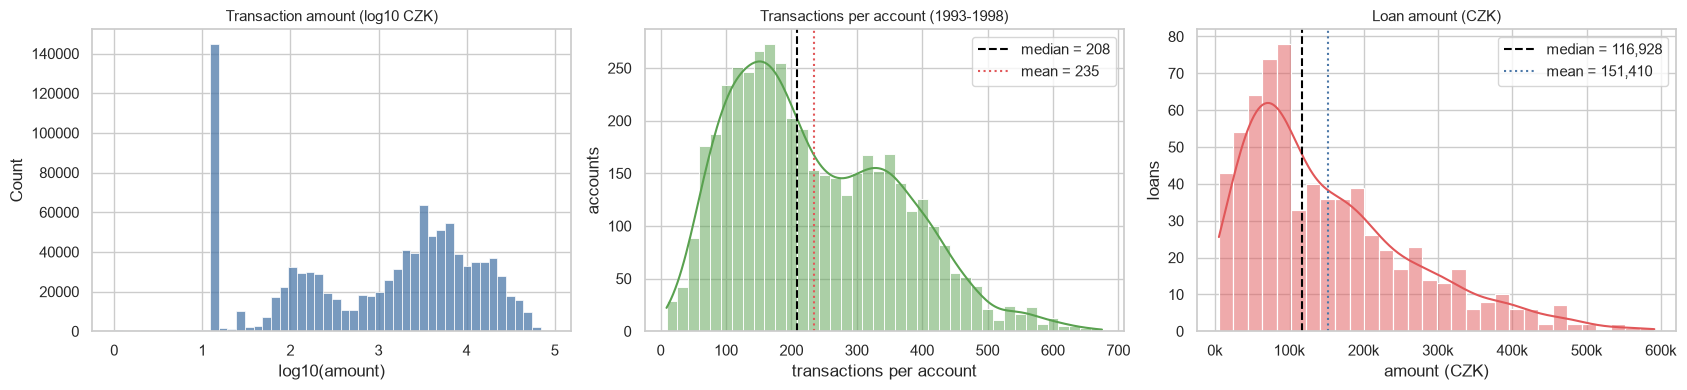

In [4]:
display(trans[["amount", "balance"]].describe().T)
display(trans.groupby("type")["amount"].describe())
display(trans["operation"].fillna("(blank = interest credit)").value_counts().to_frame("transactions"))

per_acct = trans.groupby("account_id").size()
print("Loans:"); display(loan[["amount", "duration", "payments"]].describe().T)
display(pd.concat({"loan status": loan["status"].value_counts(), "card type": card["type"].value_counts(),
                   "statement frequency": account["frequency"].value_counts()}).to_frame("count"))

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(np.log10(trans["amount"].clip(lower=1)), bins=50, ax=ax[0], color="#4C78A8")
ax[0].set(title="Transaction amount (log10 CZK)", xlabel="log10(amount)")
sns.histplot(per_acct, bins=40, kde=True, ax=ax[1], color="#59A14F")
ax[1].axvline(per_acct.median(), color="black", ls="--", label=f"median = {per_acct.median():.0f}")
ax[1].axvline(per_acct.mean(), color="#E15759", ls=":", label=f"mean = {per_acct.mean():.0f}")
ax[1].set(title="Transactions per account (1993-1998)", xlabel="transactions per account", ylabel="accounts")
ax[1].legend()
sns.histplot(loan["amount"], bins=30, kde=True, ax=ax[2], color="#E15759")
ax[2].axvline(loan["amount"].median(), color="black", ls="--", label=f"median = {loan['amount'].median():,.0f}")
ax[2].axvline(loan["amount"].mean(), color="#4C78A8", ls=":", label=f"mean = {loan['amount'].mean():,.0f}")
ax[2].set(title="Loan amount (CZK)", xlabel="amount (CZK)", ylabel="loans")
ax[2].xaxis.set_major_formatter(lambda x, _: f"{x/1000:,.0f}k")
ax[2].legend()
plt.tight_layout(); save_fig("fig_eda_distributions"); plt.show()

**Observations.** The typical account has 208 transactions over its life (mean 235). Cash withdrawals (`VYBER`, 434,918) are the most frequent operation, followed by transfers out (208,283) and interest credits, which have a blank operation (183,114). Of 682 loans, 403 are running without problems (C), 203 are finished (A) and 76 are unpaid or in debt (B: 31, D: 45). Loan outcomes are consequences of the loan and are not used as predictors. Cards are mostly classic (659), with 145 junior and 88 gold. 92.6% of accounts (4,167) receive monthly statements. Weekly (240) and per-transaction (93) statements are small groups.

### 2.3 Missing values and outliers

In [5]:
# Standardize missing values: turn "?" and blank / space-only text into real nulls (NaN), then count them
for name, df in tables.items():
    for col in df.columns:
        if pd.api.types.is_string_dtype(df[col]):
            df[col] = df[col].str.strip().replace({"": np.nan, "?": np.nan})

null_counts = {name: df.isna().sum() for name, df in tables.items()}
null_report = pd.concat(null_counts, names=["table", "column"]).rename("nulls").reset_index()
null_report = null_report[null_report["nulls"] > 0]
null_report["% null"] = 100 * null_report["nulls"] / null_report["table"].map({n: len(d) for n, d in tables.items()})
display(null_report.set_index(["table", "column"]).round(2))
print("Total null cells across all tables:", f"{sum(int(s.sum()) for s in null_counts.values()):,}")

nulls  % null
table    column                   
district A12             1    1.30
         A15             1    1.30
order    k_symbol     1379   21.31
trans    operation  183114   17.34
         k_symbol   481881   45.62
         bank       782812   74.11
         account    760931   72.04

Total null cells across all tables: 2,210,119


**Observations.** Placeholder text (`?` in the district table, blank spaces in `k_symbol`) was converted to true nulls so that every kind of missing value is counted the same way. In total there are **2,210,119 null cells**, almost all of them in the transaction table (`operation` 17.3%, `k_symbol` 45.6%, `bank` 74.1%, `account` 72.0%) and in `order.k_symbol` (21.3%). These are structural rather than errors: `operation` is blank exactly for interest credits, `k_symbol` is empty when a transaction has no stated purpose, and `bank`/`account` are filled only for transfers. They are handled by an explicit `none` category (or by dropping the two counterparty columns). The only genuine data gaps are two district fields (unemployment 1995 and crimes 1995) for district 69, Jesenik: 1 of 77 districts, affecting 48 accounts. All other tables are complete.

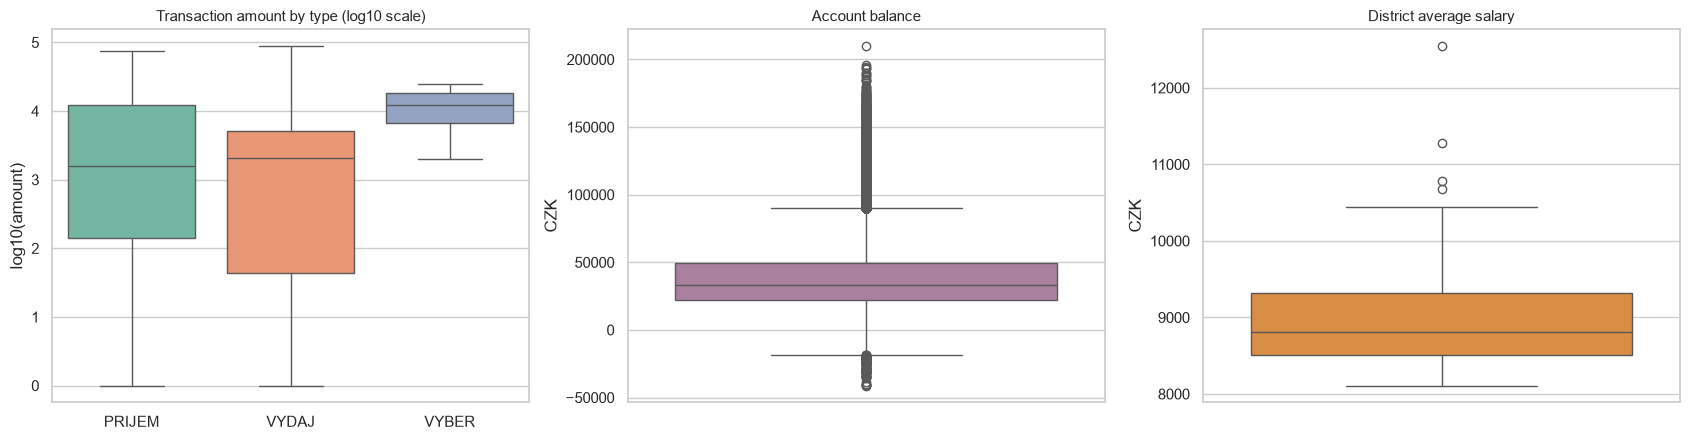

,min,median,max
type,,,
PRIJEM,0.00,"1,600.00","74,812.00"
VYBER,"2,001.00","12,103.00","24,997.00"
VYDAJ,0.00,"2,042.00","87,400.00"


,value
balance median,"33,143.40"
balance upper whisker limit,"90,405.31"
balance min,"-41,125.70"
balance max,"209,637.00"
negative-balance transactions,"2,999.00"
accounts with a negative balance,288.00
zero-amount transactions,14.00


,district,avg salary
0,Hl.m. Praha,12541
7,Mlada Boleslav,11277
25,Plzen - mesto,10787
73,Ostrava - mesto,10673


In [6]:
# Outliers detected using boxplots
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.boxplot(data=trans.assign(log_amount=np.log10(trans["amount"].clip(lower=1))), x="type", y="log_amount", ax=ax[0], palette="Set2")
ax[0].set(title="Transaction amount by type (log10 scale)", xlabel="", ylabel="log10(amount)")
sns.boxplot(y=trans["balance"], ax=ax[1], color="#B07AA1"); ax[1].set(title="Account balance", ylabel="CZK")
sns.boxplot(y=district["A11"], ax=ax[2], color="#F28E2B"); ax[2].set(title="District average salary", ylabel="CZK")
plt.tight_layout(); plt.show()

amount_summary = trans.groupby("type")["amount"].agg(["min", "median", "max"])
display(amount_summary)

q1, q3 = trans["balance"].quantile([0.25, 0.75])
display(pd.Series({
    "balance median": trans["balance"].median(),
    "balance upper whisker limit": q3 + 1.5 * (q3 - q1),
    "balance min": trans["balance"].min(),
    "balance max": trans["balance"].max(),
    "negative-balance transactions": (trans["balance"] < 0).sum(),
    "accounts with a negative balance": trans.loc[trans["balance"] < 0, "account_id"].nunique(),
    "zero-amount transactions": (trans["amount"] == 0).sum(),
}).to_frame("value"))

display(district.loc[district["A11"].nlargest(4).index, ["A2", "A11"]].rename(columns={"A2": "district", "A11": "avg salary"}))

**Observations** Transaction amounts are heavily right-skewed: typical values are small (median 1,600 CZK for credits PRIJEM and 2,042 CZK for debits VYDAJ) but the maxima are far larger (74,812 and 87,400 CZK), which is why the left boxplot uses a log10 scale. On that scale the whiskers cover the whole range and no outlier dots appear, so the skew is a long right tail in raw CZK. Legacy VYBER withdrawals are bounded between 2,001 and 24,997 CZK. Account balances center near 33,143 CZK. A dense band of high balances lies above the upper whisker (90,405 CZK), up to a maximum of 209,637 CZK, and a small set of negative balances falls below the lower whisker, down to -41,126 CZK. In total, 2,999 transactions on 288 accounts have a negative balance (overdrafts), and 14 transactions have a zero amount. District average salary is concentrated between about 8,500 and 9,300 CZK, with four districts above the whisker. The highest is Hl.m. Praha (Prague) with 12,541 CZK, as listed in the table above. All of these values are genuine banking behavior, so no rows are removed. The heavy tails are compressed with a signed log in Section 3.2.

### 2.4 Defining the target: product status and time to adoption

A customer's status is built from the dated `loan` and `card` records (a card counts whether held by the owner or a disponent):

| Class | Code | Meaning |
|---|---|---|
| `neither` | 0 | No loan and no card by 31 Dec 1998 |
| `loan_only` | 1 | Loan only |
| `card_only` | 2 | Card only |
| `both` | 3 | Both products |

For the survival and MTPP models (Section 4) I also keep the **first adoption** (`loan` / `card` / none), the time to it, and a censoring flag.

accounts
first adoption                 none            3096
                               card             758
                               loan             646
order of adoption among 'both' loan first       134
                               card first        36

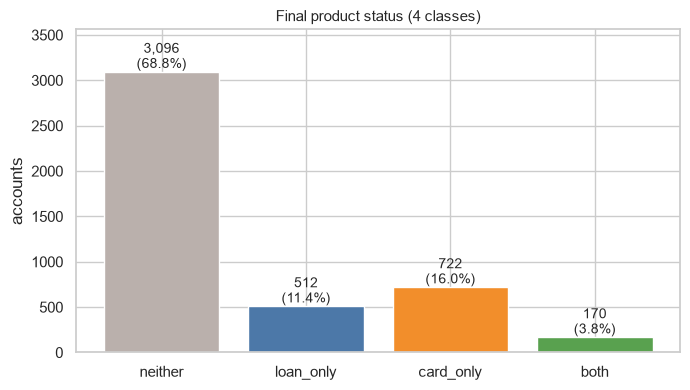

In [7]:
acct = account.rename(columns={"date": "open_date"}).set_index("account_id")

loan_first = loan.groupby("account_id")["date"].min().rename("loan_date")
card_first = (card.merge(disp[["disp_id", "account_id"]], on="disp_id")
                  .groupby("account_id")["issued"].min().rename("card_date"))
acct = acct.join([loan_first, card_first])

acct["has_loan"] = acct["loan_date"].notna()
acct["has_card"] = acct["card_date"].notna()
acct["y"] = acct["has_loan"].astype(int) + 2 * acct["has_card"].astype(int)       # 0 neither, 1 loan, 2 card, 3 both
acct["status4"] = pd.Categorical(acct["y"].map(dict(enumerate(CLASS_NAMES))), categories=CLASS_NAMES)

# first adoption + time to it (days since opening); non-adopters are censored at OBS_END
acct["first_event_date"] = acct[["loan_date", "card_date"]].min(axis=1)
acct["first_event"] = np.select(
    [acct["has_loan"] & (~acct["has_card"] | (acct["loan_date"] <= acct["card_date"])), acct["has_card"]],
    ["loan", "card"], default="none")
acct["event_observed"] = (acct["first_event"] != "none").astype(int)
acct["t_open_days"] = (acct["first_event_date"].fillna(OBS_END) - acct["open_date"]).dt.days
acct["t_from_landmark"] = acct["t_open_days"] - LANDMARK_DAYS
acct["open_year"] = acct["open_date"].dt.year

counts = acct["status4"].value_counts().reindex(CLASS_NAMES)
display(pd.concat({"first adoption": acct["first_event"].value_counts(),
                   "order of adoption among 'both'": acct.loc[acct["y"] == 3].eval("loan_date < card_date").map({True: "loan first", False: "card first"}).value_counts()}).to_frame("accounts"))

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(CLASS_NAMES, counts.values, color=["#BAB0AC", "#4C78A8", "#F28E2B", "#59A14F"])
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 40, f"{v:,}\n({100*v/len(acct):.1f}%)", ha="center")
ax.set(title="Final product status (4 classes)", ylabel="accounts", ylim=(0, counts.max() * 1.15)); plt.tight_layout(); plt.show()

**Observations.** The four classes are strongly imbalanced: `neither` 3,096 (68.8%), `card_only` 722 (16.0%), `loan_only` 512 (11.4%) and `both` 170 (3.8%). In terms of the first product adopted, 646 customers take a loan first and 758 a card first (1,404 accounts, 31.2%). Among the 170 customers with both products, 134 got the loan first and 36 the card first.

### 2.5 When do customers adopt? Cumulative incidence and time to adoption

Because observation stops in 1998, a Kaplan-Meier style estimate (1 − survival) is used so that non-adopters are treated as *censored* rather than "never". Loan and card curves are estimated separately, since a customer can adopt both.

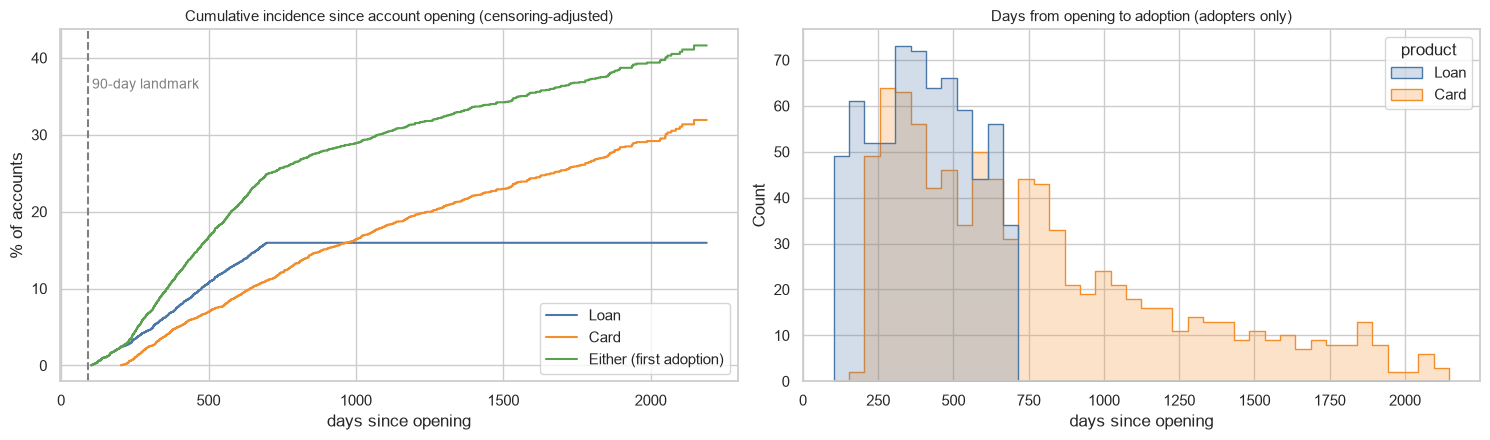

,Loan,Card,Either (first adoption)
cumulative incidence (%),,,
180 days,1.80,0.00,1.80
365 days,6.70,4.20,10.30
730 days,15.90,11.60,25.30
1095 days,15.90,18.10,30.20
1825 days,15.90,26.90,37.40


,min,median,max
days from opening to adoption,,,
Loan,102.00,395.50,697.00
Card,203.00,658.50,"2,147.00"


In [8]:
def cumulative_incidence(duration, observed):
    d = pd.DataFrame({"t": np.asarray(duration), "e": np.asarray(observed).astype(int)})
    g = d.groupby("t")["e"].agg(events="sum", n="size").sort_index()
    g["at_risk"] = g["n"][::-1].cumsum()[::-1]
    g["cif"] = 1 - (1 - g["events"] / g["at_risk"]).cumprod()
    return g["cif"]

curves = {
    "Loan": cumulative_incidence((acct["loan_date"].fillna(OBS_END) - acct["open_date"]).dt.days, acct["has_loan"]),
    "Card": cumulative_incidence((acct["card_date"].fillna(OBS_END) - acct["open_date"]).dt.days, acct["has_card"]),
    "Either (first adoption)": cumulative_incidence(acct["t_open_days"], acct["event_observed"]),
}
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for (name, c), col in zip(curves.items(), ["#4C78A8", "#F28E2B", "#59A14F"]):
    ax[0].step(c.index, 100 * c.values, where="post", label=name, color=col)
ax[0].axvline(LANDMARK_DAYS, color="grey", ls="--"); ax[0].text(LANDMARK_DAYS + 15, 36, "90-day landmark", color="grey")
ax[0].set(title="Cumulative incidence since account opening (censoring-adjusted)", xlabel="days since opening", ylabel="% of accounts"); ax[0].legend()

adopt = pd.concat([((acct["loan_date"] - acct["open_date"]).dt.days.dropna().rename("days")).to_frame().assign(product="Loan"),
                   ((acct["card_date"] - acct["open_date"]).dt.days.dropna().rename("days")).to_frame().assign(product="Card")])
sns.histplot(data=adopt, x="days", hue="product", bins=40, element="step", palette=["#4C78A8", "#F28E2B"], ax=ax[1])
ax[1].set(title="Days from opening to adoption (adopters only)", xlabel="days since opening"); plt.tight_layout(); save_fig("fig_cumulative_incidence"); plt.show()

horizon = [180, 365, 730, 1095, 1825]
tbl = pd.DataFrame({n: [100 * c[c.index <= h].iloc[-1] if (c.index <= h).any() else 0 for h in horizon] for n, c in curves.items()}, index=[f"{h} days" for h in horizon])
display(tbl.round(1).rename_axis("cumulative incidence (%)"))
days_to_adopt = pd.DataFrame({"Loan": (acct["loan_date"] - acct["open_date"]).dt.days, "Card": (acct["card_date"] - acct["open_date"]).dt.days})
days_to_adopt.agg(["min", "median", "max"]).T.rename_axis("days from opening to adoption")

**Observations.** Loans are granted between day 102 and day 697 after opening (median 395.5), whereas cards appear between day 203 and day 2,147 (median 658.5). The loan window closes at about two years, so loan incidence plateaus near 16%, while cards keep accumulating (about 27% after five years).

Since, the earliest adoption of any product happens 102 days after opening, so a **90-day landmark** keeps every account in the study (no one has already adopted at prediction time) while giving a short, leakage-free behavior window.

,1993,1994,1995,1996,1997,1998
granted per calendar year,,,,,,
Loans,20,101,90,117,196,158
Cards,1,21,63,116,242,449


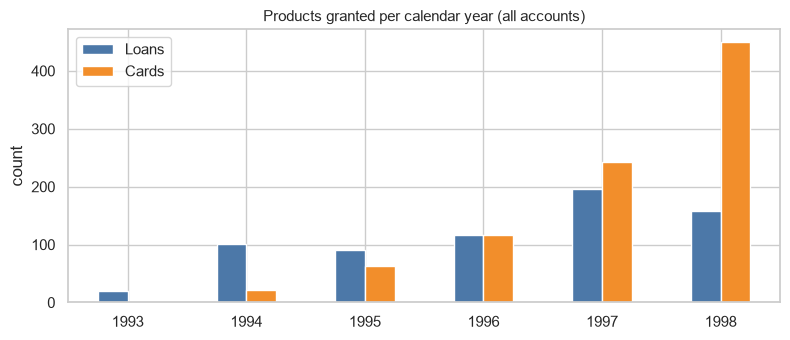

In [9]:
cal = pd.concat([loan["date"].dt.year.value_counts().rename("Loans"), card["issued"].dt.year.value_counts().rename("Cards")], axis=1).sort_index().fillna(0).astype(int)
display(cal.T.rename_axis("granted per calendar year"))
cal.plot(kind="bar", figsize=(8, 3.5), color=["#4C78A8", "#F28E2B"], rot=0)
plt.title("Products granted per calendar year (all accounts)"); plt.ylabel("count"); plt.tight_layout(); plt.show()

Card issuance grows steeply over calendar time (a handful in 1994 to several hundred in 1998), so card adoption reflects the bank's roll-out as well as how long an account has existed; this matters for a time-based split and is revisited in the conclusions.

### 2.6 Leakage check: post-adoption traces in the transaction table

In [10]:
mk = trans.merge(acct[["loan_date", "card_date"]], left_on="account_id", right_index=True, how="left")
checks = [("k_symbol = UVER (loan repayment)", mk["k_symbol"] == "UVER", "loan_date"),
          ("operation = VYBER KARTOU (card withdrawal)", mk["operation"] == "VYBER KARTOU", "card_date")]
rows = []
for label, mask, col in checks:
    sub = mk[mask]
    rows.append({"marker": label, "transactions": len(sub),
                 "on accounts without product": int(sub[col].isna().sum()),
                 "before adoption date": int((sub["date"] < sub[col]).sum()),
                 "on/after adoption date": int((sub["date"] >= sub[col]).sum()),
                 "earliest (days after adoption)": int((sub["date"] - sub[col]).dt.days.min())})
display(pd.DataFrame(rows).set_index("marker"))

uver_orders = order[order["k_symbol"] == "UVER"]
pd.Series({"accounts with a loan-payment standing order": uver_orders["account_id"].nunique(),
           "accounts with a loan record": loan["account_id"].nunique(),
           "loan-payment orders on accounts with no loan": int((~uver_orders["account_id"].isin(loan["account_id"])).sum())}).to_frame("count")

,transactions,on accounts without product,before adoption date,on/after adoption date,earliest (days after adoption)
marker,,,,,
k_symbol = UVER (loan repayment),13580,0,0,13580,0
operation = VYBER KARTOU (card withdrawal),8036,0,0,8036,1


,count
accounts with a loan-payment standing order,717
accounts with a loan record,682
loan-payment orders on accounts with no loan,35


Loan repayments and card withdrawals **never** appear before the product exists, so using a customer's complete history would let a model "predict" adoption from its consequences. All predictors are therefore built only from transactions up to the 90-day landmark, and loan `status`, `amount`, `duration`, card `type` and the `order` table are excluded. The `order` table lists loan-payment standing orders for 717 accounts although only 682 accounts have a loan (35 such orders sit on accounts with no loan record); because it has no dates it cannot be cut at the landmark.

### 2.7 Adoption by opening cohort (informs the time-based split)

,neither,loan_only,card_only,both,total,follow-up min (months),median,max
open_year,,,,,,,,
1993,809,114,180,36,1139,57.10,62.90,69.00
1994,293,52,81,13,439,45.20,51.10,57.00
1995,434,83,116,28,661,33.10,38.70,45.00
1996,929,170,200,64,1363,21.10,26.80,33.00
1997,631,93,145,29,898,9.10,15.10,21.00


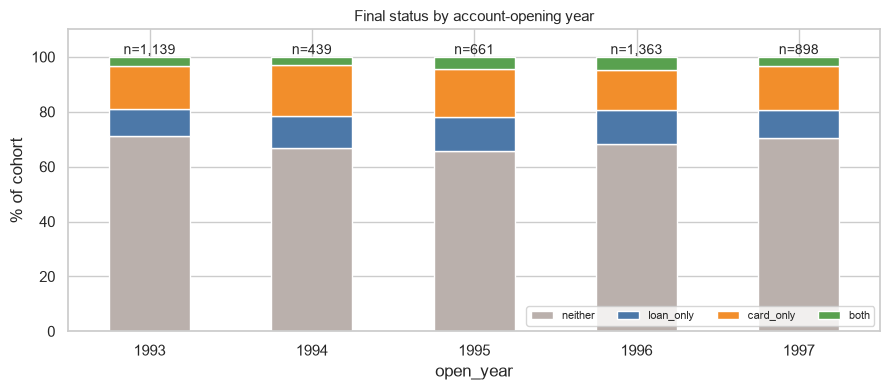

In [11]:
cohort = pd.crosstab(acct["open_year"], acct["status4"])[CLASS_NAMES]
cohort_pct = cohort.div(cohort.sum(axis=1), axis=0) * 100
follow = (((OBS_END - acct["open_date"]).dt.days - LANDMARK_DAYS) / 30.44).groupby(acct["open_year"]).agg(["min", "median", "max"]).round(1)
follow.columns = ["follow-up min (months)", "median", "max"]
display(cohort.assign(total=cohort.sum(axis=1)).join(follow))

ax = cohort_pct.plot(kind="bar", stacked=True, figsize=(9, 4), color=["#BAB0AC", "#4C78A8", "#F28E2B", "#59A14F"], rot=0)
for i, tot in enumerate(cohort.sum(axis=1)): ax.text(i, 101, f"n={tot:,}", ha="center")
ax.set(title="Final status by account-opening year", ylabel="% of cohort", ylim=(0, 110)); ax.legend(loc="lower right", ncol=4, fontsize=8)
plt.tight_layout(); save_fig("fig_cohort_status_end"); plt.show()

### 2.8 Adoption by customer attributes

,count,mean,std,min,25%,50%,75%,max
age_at_open,"4,500.00",41.22,17.14,10.26,26.51,40.49,53.96,79.44


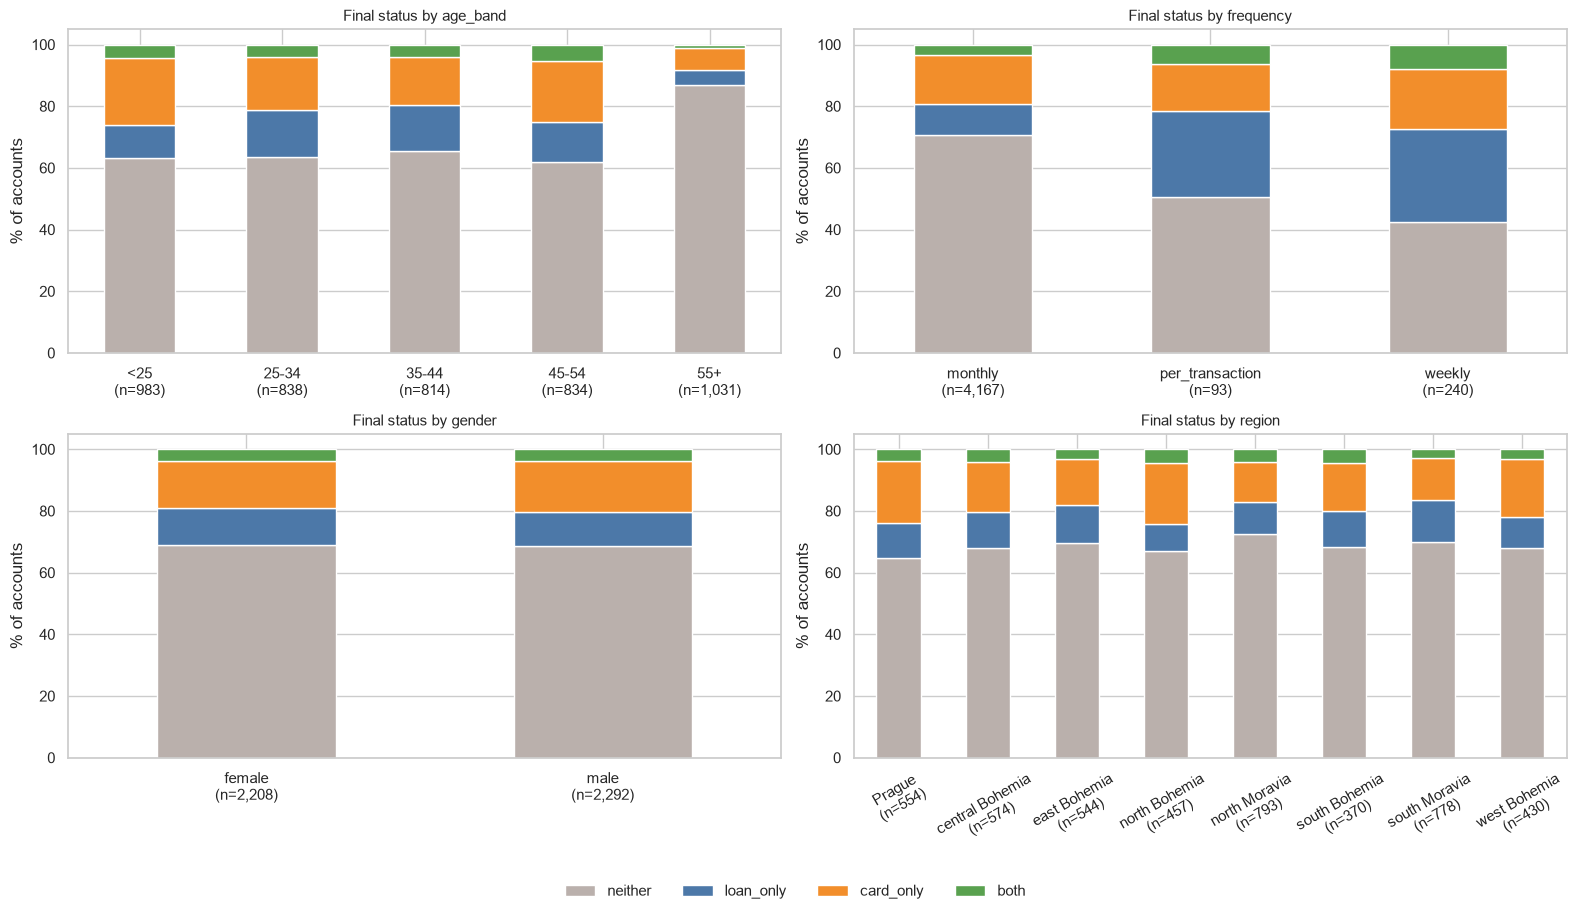

status4                    neither  loan_only  card_only  both     n
variable  group                                                     
age_band  <25                63.20      10.70      21.70  4.50   983
          25-34              63.40      15.30      17.20  4.20   838
          35-44              65.60      14.70      15.60  4.10   814
          45-54              61.90      12.90      19.80  5.40   834
          55+                86.70       4.90       7.10  1.30  1031
frequency monthly            70.70       9.90      15.90  3.50  4167
          per_transaction    50.50      28.00      15.10  6.50    93
          weekly             42.50      30.00      19.60  7.90   240
gender    female             68.90      11.90      15.30  3.80  2208
          male               68.70      10.90      16.80  3.70  2292
region    Prague             64.80      11.40      20.00  3.80   554
          central Bohemia    67.90      11.70      16.40  4.00   574
          east Bohemia       69.50      12.30      15.10  3.10   544
          north Bohemia      67.00       8.80      19.70  4.60   457
          north Moravia      72.40      10.50      12.90  4.30   793
          south Bohemia      68.40      11.60      15.40  4.60   370
          south Moravia      69.90      13.60      13.50  3.00   778
          west Bohemia       67.90      10.00      18.80  3.30   430

In [12]:
# Owner age and gender come from the encoded birth number (YYMMDD, month + 50 for women)
owner = disp[disp["type"] == "OWNER"].merge(client, on="client_id").set_index("account_id")
b = owner["birth_number"].astype(int)
month = (b // 100) % 100
owner["is_female"] = (month > 50).astype(int)
owner["birth_date"] = pd.to_datetime({"year": 1900 + b // 10000, "month": np.where(month > 50, month - 50, month), "day": b % 100})
acct = acct.join(owner[["is_female", "birth_date"]])
acct["age_at_open"] = (acct["open_date"] - acct["birth_date"]).dt.days / 365.25
acct["has_disponent"] = (disp.groupby("account_id").size() > 1).astype(int).reindex(acct.index)
acct["frequency"] = acct["frequency"].map({"POPLATEK MESICNE": "monthly", "POPLATEK TYDNE": "weekly", "POPLATEK PO OBRATU": "per_transaction"})
acct["gender"] = acct["is_female"].map({0: "male", 1: "female"})
acct["age_band"] = pd.cut(acct["age_at_open"], [0, 25, 35, 45, 55, 100], right=False, labels=["<25", "25-34", "35-44", "45-54", "55+"])
acct = acct.join(district.set_index("A1")[["A3"]].rename(columns={"A3": "region"}), on="district_id")
display(acct["age_at_open"].describe().to_frame().T)

colors = ["#BAB0AC", "#4C78A8", "#F28E2B", "#59A14F"]
fig, axes = plt.subplots(2, 2, figsize=(16, 9))
for ax, col in zip(axes.ravel(), ["age_band", "frequency", "gender", "region"]):
    ct = pd.crosstab(acct[col], acct["status4"])[CLASS_NAMES]
    pct = ct.div(ct.sum(axis=1), axis=0) * 100
    pct.index = [f"{i}\n(n={n:,})" for i, n in zip(pct.index, ct.sum(axis=1))]
    pct.plot(kind="bar", stacked=True, ax=ax, color=colors, rot=0 if col != "region" else 30, legend=False)
    ax.set(title=f"Final status by {col}", ylabel="% of accounts", xlabel="")
h, l = axes[0, 0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.02))
plt.tight_layout(rect=(0, 0.03, 1, 1)); save_fig("fig_adoption_by_attributes"); plt.show()

def pct_by(col):
    ct = pd.crosstab(acct[col], acct["status4"])[CLASS_NAMES]
    out = ct.div(ct.sum(axis=1), axis=0) * 100
    out["n"] = ct.sum(axis=1)
    return out

pd.concat({c: pct_by(c) for c in ["age_band", "frequency", "gender", "region"]},
          names=["variable", "group"]).round(1)

**Observations.** Age and statement frequency separate the classes, whereas gender and region do not. 86.7% of customers aged 55+ end with neither product, versus 61.9–65.6% in each younger age band (under-25s are the most likely to hold a card, 21.7%). Weekly (n = 240) and per-transaction (n = 93) statement accounts end with neither product far less often (42.5% and 50.5%) than monthly accounts (70.7%, n = 4,167) and are much more likely to hold a loan (30.0% and 28.0% vs 9.9%), although the first two groups are small. Gender is virtually identical (68.9% vs 68.7% "neither"), and "neither" ranges only from 64.8% to 72.4% across the eight regions.

### 2.9 Early-behavior features (first 90 days) and adoption

Here I build the per-account predictors from each account's own first 90 days (district cleaning, windowed transaction features) and explore how they relate to the four classes.

In [13]:
# ---- clean the district table and derive district-level predictors
dist = district.rename(columns={
    "A1": "district_id", "A3": "region", "A4": "population", "A10": "urban_ratio", "A11": "avg_salary",
    "A12": "unemp95", "A13": "unemp96", "A14": "entrepreneurs_per1000", "A15": "crimes95", "A16": "crimes96"})
for c in ["unemp95", "crimes95"]:
    dist[c] = pd.to_numeric(dist[c])
dist["unemp_change"] = dist["unemp96"] - dist["unemp95"]
dist["crime_rate96"] = dist["crimes96"] / dist["population"] * 1000
dist["crime_growth"] = dist["crimes96"] / dist["crimes95"] - 1
dist_cols = ["population", "urban_ratio", "avg_salary", "unemp95", "unemp96", "unemp_change",
             "entrepreneurs_per1000", "crime_rate96", "crime_growth"]
acct = acct.drop(columns=["region"]).join(dist.set_index("district_id")[["region"] + dist_cols], on="district_id")

In [14]:
def build_window_features(trans, acct, landmark_days=LANDMARK_DAYS):
    # Keep only transactions on or before the landmark (account opening + 90 days)
    t = trans.merge(acct[["open_date"]], left_on="account_id", right_index=True)
    t["day"] = (t["date"] - t["open_date"]).dt.days
    w = t[t["day"] <= landmark_days].sort_values(["account_id", "date", "trans_id"]).copy()
    w["is_credit"] = w["type"].eq("PRIJEM")
    w["ksym"] = w["k_symbol"].fillna("").str.strip().replace("", "none")
    w["op"] = w["operation"].fillna("none")
    g = w.groupby("account_id")

    f = pd.DataFrame(index=acct.index)
    f["n_txn"] = g.size()
    f["active_days"] = g["date"].nunique()
    cred, deb = w[w["is_credit"]].groupby("account_id")["amount"], w[~w["is_credit"]].groupby("account_id")["amount"]
    f["n_credit"], f["n_debit"] = cred.size(), deb.size()
    f["credit_sum"], f["debit_sum"] = cred.sum(), deb.sum()
    f[["n_credit", "n_debit", "credit_sum", "debit_sum"]] = f[["n_credit", "n_debit", "credit_sum", "debit_sum"]].fillna(0)
    f["net_flow"] = f["credit_sum"] - f["debit_sum"]
    f["spend_to_income"] = f["debit_sum"] / f["credit_sum"].replace(0, np.nan)
    f["amt_mean"], f["amt_median"], f["amt_max"], f["amt_std"] = (g["amount"].mean(), g["amount"].median(), g["amount"].max(), g["amount"].std())
    for name, op in {"share_cash_wd": "VYBER", "share_xfer_out": "PREVOD NA UCET",
                     "share_xfer_in": "PREVOD Z UCTU", "share_cash_dep": "VKLAD"}.items():
        f[name] = w["op"].eq(op).groupby(w["account_id"]).mean()
    f["bal_open"], f["bal_last"] = g["balance"].first(), g["balance"].last()
    f["bal_mean"], f["bal_min"], f["bal_max"], f["bal_std"] = g["balance"].mean(), g["balance"].min(), g["balance"].max(), g["balance"].std()

    d = w.drop_duplicates(["account_id", "date"]).copy()            # inter-arrival gaps between active days
    d["gap"] = d.groupby("account_id")["date"].diff().dt.days
    gg = d.groupby("account_id")["gap"]
    f["gap_mean"], f["gap_std"], f["gap_max"] = gg.mean(), gg.std(), gg.max()
    f["gap_cv"] = f["gap_std"] / f["gap_mean"].replace(0, np.nan)
    f["days_since_last_txn"] = landmark_days - d.groupby("account_id")["day"].max()

    for name, k in {"has_pension": "DUCHOD", "has_insurance": "POJISTNE", "has_household": "SIPO", "has_fees": "SLUZBY"}.items():
        f[name] = w["ksym"].eq(k).groupby(w["account_id"]).any().astype(int)
        f[name] = f[name].fillna(0).astype(int)
    f["interest_sum"] = w[w["ksym"] == "UROK"].groupby("account_id")["amount"].sum()
    f["interest_sum"] = f["interest_sum"].fillna(0)
    return f, w

win_features, win = build_window_features(trans, acct)

# ---- leakage guards
assert (win["ksym"] == "UVER").sum() == 0 and (win["op"] == "VYBER KARTOU").sum() == 0, "post-adoption traces in window"
assert (acct["first_event_date"] - acct["open_date"]).dt.days.min() > LANDMARK_DAYS, "someone adopted before the landmark"
pd.Series({"transactions in 90-day window": len(win), "transactions overall": len(trans),
           "accounts covered": win["account_id"].nunique(), "landmark (day)": LANDMARK_DAYS,
           "earliest adoption (day)": int((acct["first_event_date"] - acct["open_date"]).dt.days.min())}).to_frame("value")

,value
transactions in 90-day window,38935
transactions overall,1056320
accounts covered,4500
landmark (day),90
earliest adoption (day),102


**Observations.** The 90-day window keeps 38,935 of the 1,056,320 transactions and covers all 4,500 accounts. The earliest adoption occurs on day 102, after the landmark, and the assertions confirm that no loan-repayment or card-withdrawal transactions fall inside the window.

In [15]:
static_cols = ["age_at_open", "is_female", "has_disponent", "frequency", "region"] + dist_cols
target_cols = ["y", "status4", "first_event", "event_observed", "t_from_landmark", "open_date", "open_year"]
model_df = acct[static_cols + target_cols].join(win_features)
feature_cols = static_cols + list(win_features.columns)

print("Modeling table:", model_df.shape, "| predictors:", len(feature_cols))
miss = model_df[feature_cols].isna().sum()
display(miss[miss > 0].to_frame("missing").assign(pct=lambda d: 100 * d["missing"] / len(model_df)))
display(model_df[feature_cols].describe().T.round(2))

Modeling table: (4500, 53) | predictors: 46


,missing,pct
unemp95,48,1.07
unemp_change,48,1.07
crime_growth,48,1.07
amt_std,1,0.02
bal_std,1,0.02
gap_mean,1,0.02
gap_std,5,0.11
gap_max,1,0.02
gap_cv,5,0.11


,count,mean,std,min,25%,50%,75%,max
age_at_open,"4,500.00",41.22,17.14,10.26,26.51,40.49,53.96,79.44
is_female,"4,500.00",0.49,0.50,0.00,0.00,0.00,1.00,1.00
has_disponent,"4,500.00",0.19,0.39,0.00,0.00,0.00,0.00,1.00
population,"4,500.00","269,243.20","358,316.52","42,821.00","88,884.00","121,947.00","226,122.00","1,204,953.00"
urban_ratio,"4,500.00",69.24,19.77,33.90,52.70,63.10,85.60,100.00
avg_salary,"4,500.00","9,515.20","1,326.41","8,110.00","8,547.00","8,991.00","9,897.00","12,541.00"
unemp95,"4,452.00",2.87,1.85,0.29,1.60,2.77,3.85,7.34
unemp96,"4,500.00",3.50,2.13,0.43,1.96,3.47,4.79,9.40
unemp_change,"4,452.00",0.58,0.40,-0.36,0.28,0.57,0.78,2.06
entrepreneurs_per1000,"4,500.00",121.12,23.16,81.00,105.00,116.00,131.00,167.00


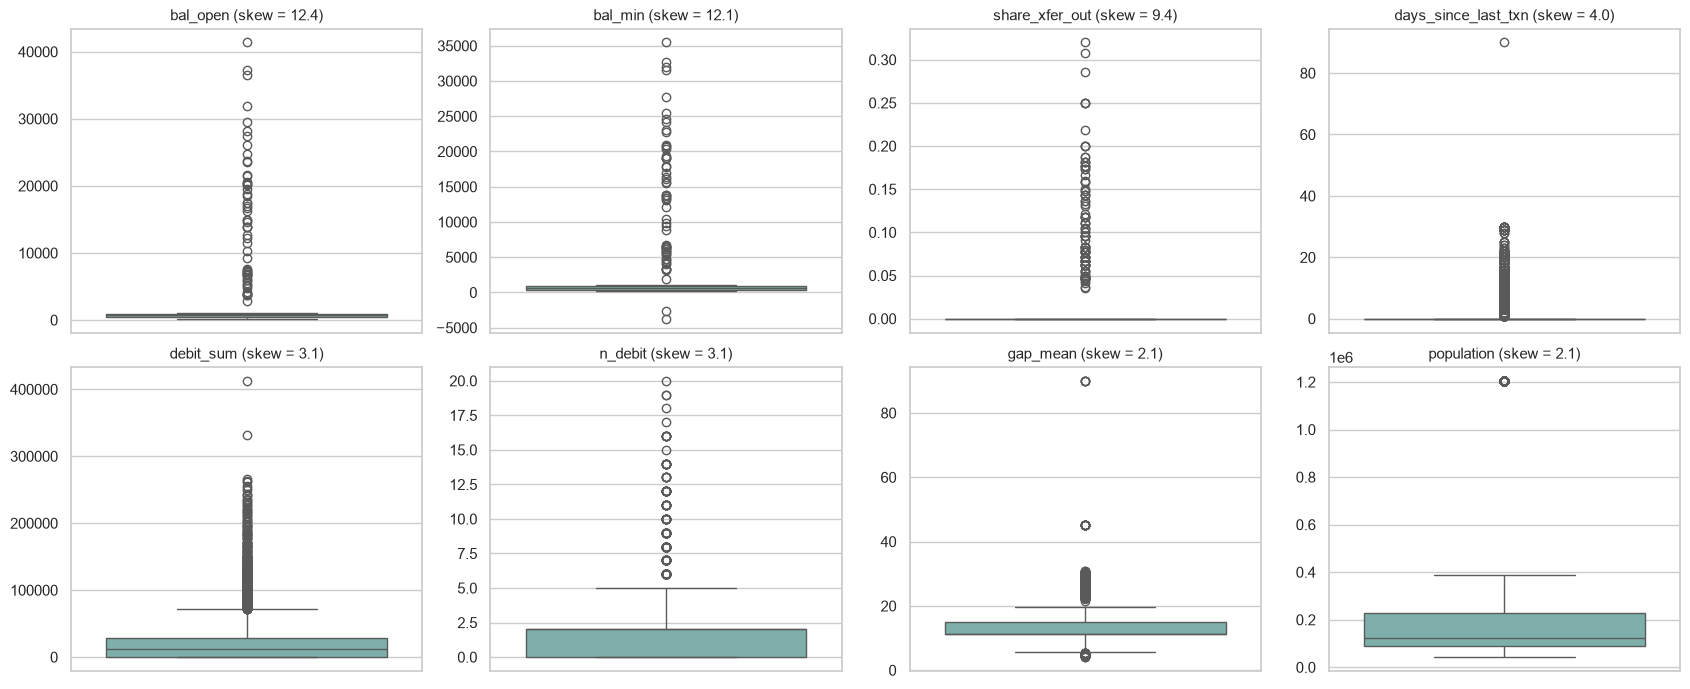

In [16]:
# Column groups used from here on
bin_cols = ["is_female", "has_disponent", "has_pension", "has_insurance", "has_household", "has_fees"]
cat_cols = ["frequency", "region"]
num_cols = [c for c in feature_cols if c not in bin_cols + cat_cols]

# Outliers
skewed = model_df[num_cols].skew().sort_values(key=abs, ascending=False).head(8)
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, (c, sk) in zip(axes.ravel(), skewed.items()):
    sns.boxplot(y=model_df[c], ax=ax, color="#76B7B2")
    ax.set(title=f"{c} (skew = {sk:.1f})", ylabel="")
plt.tight_layout(); save_fig("fig_skew_boxplots"); plt.show()

**Observations.** The eight most right-skewed predictors (skewness between about 2 and 12) are balance levels (`bal_open`, `bal_min`), the share of transfers out, the number of days since the last transaction, debit totals and counts, the mean gap between transactions, and district population. Their boxplots show a compact box with a long tail of points beyond the upper whisker. These values are genuine banking behavior (large balances, overdrafts, very quiet accounts, Prague as a large district), so no rows are deleted and heavy-tailed predictors are instead compressed with a signed log transform in Section 3.2, which also handles negative balances.

**Feature behavior by class (all accounts)**

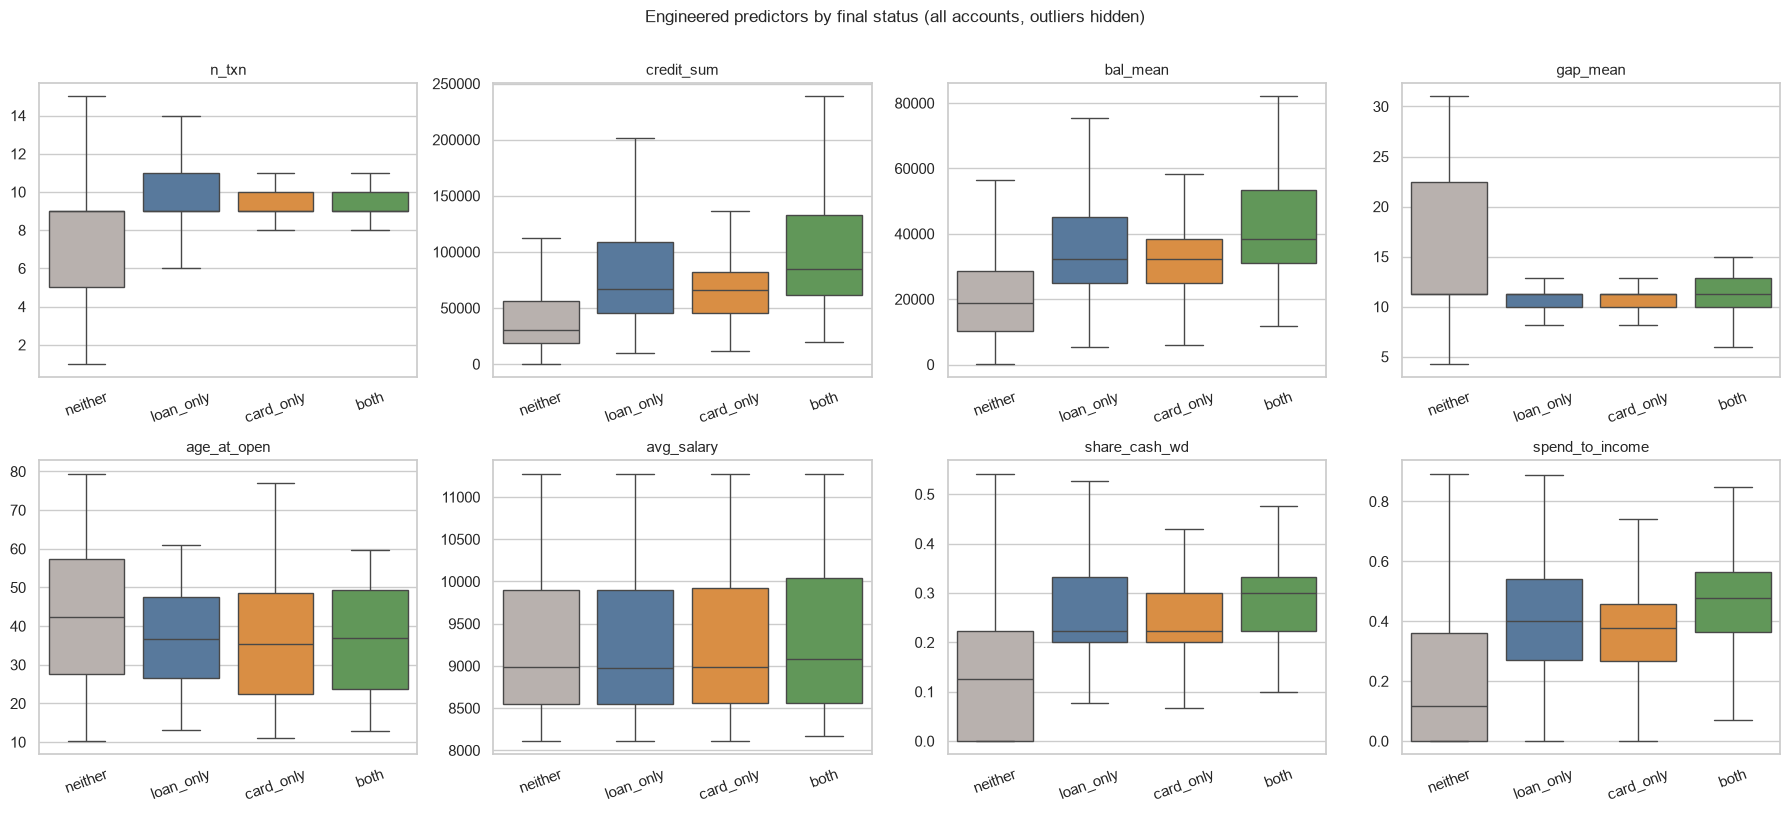

status4,neither,loan_only,card_only,both
n_txn,9.00,9.00,9.00,9.00
credit_sum,"30,799.25","67,081.55","66,018.90","84,687.90"
bal_mean,"18,738.40","32,203.86","32,281.19","38,562.04"
gap_mean,11.25,11.25,11.25,11.25
age_at_open,42.37,36.68,35.30,36.89
avg_salary,"8,991.00","8,980.00","8,991.00","9,084.50"
share_cash_wd,0.12,0.22,0.22,0.30
spend_to_income,0.12,0.40,0.38,0.48


status4,neither,loan_only,card_only,both
% of class with flag,,,,
has_pension,23.30,0.00,2.50,0.00
has_insurance,0.30,2.10,0.30,1.20
has_household,1.60,6.10,2.80,4.70
has_fees,4.00,10.50,6.80,10.00
has_disponent,19.70,21.30,15.90,21.20
is_female,49.20,51.40,46.80,50.00


In [17]:
show = ["n_txn", "credit_sum", "bal_mean", "gap_mean", "age_at_open", "avg_salary", "share_cash_wd", "spend_to_income"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.ravel(), show):
    sns.boxplot(data=model_df, x="status4", y=c, order=CLASS_NAMES, showfliers=False, ax=ax,
                palette=["#BAB0AC", "#4C78A8", "#F28E2B", "#59A14F"])
    ax.set(title=c, xlabel="", ylabel=""); ax.tick_params(axis="x", rotation=20)
plt.suptitle("Engineered predictors by final status (all accounts, outliers hidden)", y=1.01); plt.tight_layout(); save_fig("fig_features_by_class"); plt.show()

display(model_df.groupby("status4")[show].median().round(2).T)
flags = ["has_pension", "has_insurance", "has_household", "has_fees", "has_disponent", "is_female"]
(100 * model_df.groupby("status4")[flags].mean()).round(1).T.rename_axis("% of class with flag")

In [18]:
print("Does district context relate to adoption? % of accounts adopting any product, by quartile of each district variable")
adopted = model_df["status4"].ne("neither")
pd.concat({col: (adopted.groupby(pd.qcut(model_df[col], 4)).mean() * 100).round(1)
           for col in ["avg_salary", "unemp95", "urban_ratio"]},
          names=["variable", "quartile range"]).to_frame("% adopting any product")

Does district context relate to adoption? % of accounts adopting any product, by quartile of each district variable


% adopting any product
variable    quartile range                            
avg_salary  (8109.999, 8547.0]                   31.50
            (8547.0, 8991.0]                     30.90
            (8991.0, 9897.0]                     31.40
            (9897.0, 12541.0]                    31.00
unemp95     (0.289, 1.6]                         32.70
            (1.6, 2.77]                          29.10
            (2.77, 3.85]                         32.30
            (3.85, 7.34]                         30.20
urban_ratio (33.899, 52.7]                       32.10
            (52.7, 63.1]                         31.50
            (63.1, 85.6]                         29.60
            (85.6, 100.0]                        31.60

**Observations.** Eventual adopters look different from `neither` accounts in their first 90 days. Their median deposits are more than twice as large (credit_sum 66–85k vs 31k CZK), their typical average balance is higher (median of each account's mean balance: 32–39k vs 19k), they spend a larger share of what comes in (median spend-to-income 0.38–0.48 vs 0.12) and withdraw more cash (22–30% of transactions vs 12%). They are also younger (median age 35–37 vs 42). The median number of transactions (9) and the median gap between active days (11.25) are the same in every class; the difference is the spread. In the flag table, 23.3% of `neither` accounts receive a pension against none of the loan-only and both groups and 2.5% of card-only accounts, while insurance, household payments and fees are more common among adopters (for example fees: 6.8–10.5% vs 4.0%); gender and having a disponent differ little. District context, in the table above, shows little relation to adoption: 29–33% of accounts adopt something in every quartile of average salary, unemployment and urban ratio, and median district salary is nearly identical across classes (about 9,000 CZK).

**Feature correlation (all accounts)**

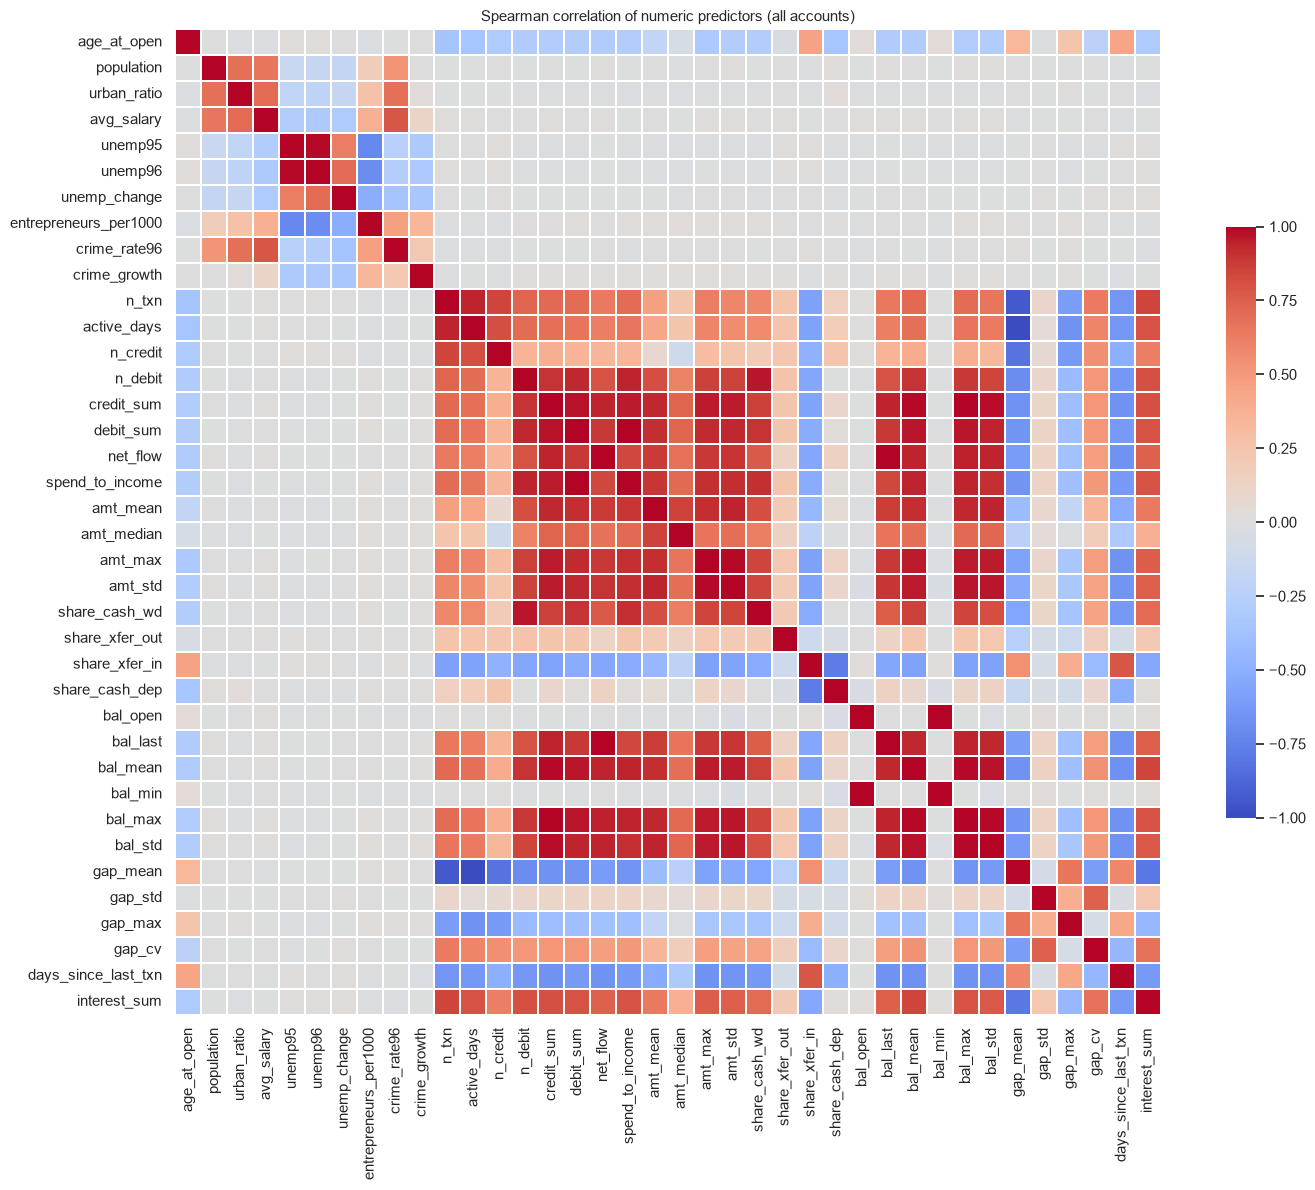

,count
predictor pairs,703
pairs with |rho| > 0.90,56


In [19]:
corr_all = model_df[num_cols].corr(method="spearman")
plt.figure(figsize=(15, 12))
sns.heatmap(corr_all, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True, cbar_kws={"shrink": .6}, linewidths=.2)
plt.title("Spearman correlation of numeric predictors (all accounts)"); plt.tight_layout(); save_fig("fig_corr_heatmap"); plt.show()

upper = corr_all.where(np.triu(np.ones(corr_all.shape, dtype=bool), k=1))
pairs_all = upper.stack().dropna()
n_num = len(num_cols)
pd.Series({"predictor pairs": n_num * (n_num - 1) // 2,
           "pairs with |rho| > 0.90": int((pairs_all.abs() > 0.90).sum())}).to_frame("count")

**Observations.** 56 of 703 numeric predictor pairs have |rho| above 0.90, mainly among cash-flow and balance measures (which all reflect customer income level) and among activity counts. This redundancy is handled in Section 3.2, where the correlations are recomputed on the training set only and used to drop duplicate predictors.

### 2.10 Key findings from the EDA

The data are clean and structurally rich: 4,500 accounts, 1,056,320 transactions (1993–1998), each account holding at most one loan and one card. The target is **imbalanced**: 68.8% of accounts end with neither product, 16.0% with a card only, 11.4% with a loan only and just **3.8% (170 accounts) with both**, so accuracy alone will be misleading (always predicting "neither" scores about 70%) and macro-F1, per-class recall and one-vs-rest AUC will be needed. Timing is highly structured: no one adopts before day 102; loans arrive a median of 395 days after opening and **never later than day 697**, so loan incidence plateaus at about 16%, while cards start after day 203, arrive later (median 658 days) and keep accumulating (about 27% by five years). Card issuance also rises steeply with *calendar* time (1 card in 1993, 449 in 1998), so card adoption mixes account age with the bank's roll-out, and the 1997 test cohort sits in a period of rapid card growth. Observation ends in 1998, so "neither" means "not yet". Data-quality issues are minor: after recoding placeholders as true nulls there are 2,210,119 null cells, almost all of them structural and in the transaction and order tables (`operation` is blank exactly for interest credits, `bank` and `account` are filled only for transfers); the only genuine gaps are two district fields for district 69 (48 accounts). Amounts and balances are heavily right-skewed, and 2,999 negative-balance transactions on 288 accounts and 14 zero-amount transactions are genuine behavior. Most importantly, loan repayments (13,580 transactions) and card withdrawals (8,036) appear only *after* adoption, which proves that the full history leaks the answer and motivates the 90-day landmark.

Who adopts? Gender and region barely matter (65–72% "neither" in every region and 69% for both genders), whereas **age** (87% of customers aged 55+ end with neither product, versus 62–66% in every younger age band), **statement frequency** (50.5% of per-transaction and 42.5% of weekly-statement accounts end with neither product, versus 70.7% for monthly, though these groups are small at 93 and 240 accounts), and **early financial behavior** are informative. Over their first 90 days, eventual adopters have more than double the median deposits (66–85k vs 31k CZK) and a much higher typical average balance (median of 32–39k vs 19k CZK), spend a much larger share of what comes in (median spend-to-income 0.38–0.48 vs 0.12, cash-withdrawal share 22–30% vs 12%), and almost never receive a pension (0% of loan-only and both customers and 2.5% of card-only, versus 23.3% of "neither" accounts). District context shows little relation to adoption (29–33% adopt in every salary, unemployment and urban-ratio quartile). The adoption mix is stable across opening cohorts (66–71% neither), which supports a time-based split. These findings suggest that (i) macro-averaged metrics, class weights and per-class evaluation are needed; (ii) income/balance level, activity regularity, age and transaction mix should be the core predictors; (iii) many predictors will be redundant because they all reflect income level; and (iv) a model may partly learn "active, well-funded account" rather than "about to need credit", which the MTPP's timing information is meant to improve on.

## 3. Problem formulation, preprocessing and data splits

### 3.1 Fixed-horizon target, time-based split and re-run of the preprocessing

**Target.** The EDA above labels an account by whether it *ever* adopted a product before the end of the data (31 Dec 1998). This end-of-data label is not comparable across cohorts: a 1993 account was watched for about five years, a 1997 account for one to two. The primary target is now a **fixed-horizon label**: whether the account adopted a loan and/or a card **within 365 days of its 90-day landmark** (about 15 months after opening), the same window for every account. Accounts watched for fewer than 365 days after the landmark (opened after 2 Oct 1997, 197 accounts) cannot be labelled and are excluded, which leaves **4,303 accounts**. The end-of-data label is kept as a sensitivity analysis at the end of Section 4.

**Primary split: time-based.** Accounts opened **before 1997 are the training set (3,602 accounts, 19 with `both`)** and **1997 accounts are the test set (701 accounts, 14 with `both`)**, which mimics scoring new customers with a model built on the past. All *fitted* preprocessing steps (median imputation, signed-log selection, standardization, one-hot encoding and the correlation-based pruning) are **re-fitted on the training accounts only**; the test rows are only transformed. For tuning in the next stage there are two expanding-window folds inside the training set (train on 1993-94 and validate on 1995, train on 1993-95 and validate on 1996).

**Secondary split: random stratified 80/20** of the same 4,303 accounts (stratified on the four-class label, `random_state=42`; 3,442 train and 861 test accounts). The same models are re-fitted on it at the end of Section 4 to show how much a random split would flatter the results.

**Two clocks per account.** Loans and cards are *not* competing risks: a customer who takes a loan can still take a card later (170 accounts hold both by the end of the data). Each product therefore gets its own time-to-event target, measured from the landmark and censored at the end of observation (31 Dec 1998) if the product is never adopted: `t_loan`, `e_loan`, `t_card`, `e_card`. The survival models use these full time-to-event targets, and their prediction is converted to the same fixed-horizon classes.

**Caveats.** (1) The 1997 cohort adopts faster than earlier ones (figure below): 23.5% of the test accounts adopt a product within 365 days against 12.5% of the training accounts, so the class priors shift between train and test. (2) Training labels and survival targets of late-1996 accounts are resolved after some 1997 landmarks, a mild look-ahead; test labels are never used in training. (3) `both` is rare at this horizon (19 training and 14 test accounts), so macro-F1 is noisy.

In [20]:
# ---- Settings for the modelling stage (data tables and base constants come from Section 1.4)
import json, pickle, time, gc
OUT_DIR = Path("processed_h365"); OUT_DIR.mkdir(exist_ok=True)       # outputs of the modelling stage
TEMPORAL_SPLIT_DATE = pd.Timestamp("1997-01-01")                     # accounts opened before = training, from this date = test
HORIZON_DAYS = 365                                                   # fixed prediction horizon: adoption within N days after the 90-day landmark
pd.set_option("display.float_format", "{:,.3f}".format)

Accounts observed for the full 365-day horizon: 4,303 of 4,500 (excluded: opened after 1997-10-02)
Modelling table: 4,303 accounts x 46 predictors | sequences: 4,500


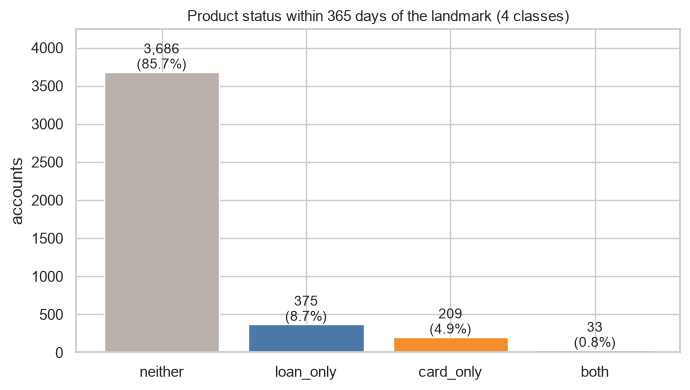

In [21]:
# ---- 1. load raw tables (same cleaning rules as in Section 2)
def read_table(name):
    return pd.read_csv(DATA_DIR / f"{name}.csv", sep=";", low_memory=False)

account, card, client, disp, district, loan, trans = (read_table(n) for n in
    ["account", "card", "client", "disp", "district", "loan", "trans"])
to_date = lambda s: pd.to_datetime(s.astype(str).str[:6], format="%y%m%d")
account["date"], loan["date"] = to_date(account["date"]), to_date(loan["date"])
card["issued"], trans["date"] = to_date(card["issued"]), to_date(trans["date"])
for df in [account, card, client, disp, district, loan, trans]:          # "?" and blanks -> real nulls
    for col in df.columns:
        if pd.api.types.is_string_dtype(df[col]):
            df[col] = df[col].str.strip().replace({"": np.nan, "?": np.nan})

# ---- 2. targets: four-class status + one survival clock per product
acct = account.rename(columns={"date": "open_date"}).set_index("account_id")
loan_first = loan.groupby("account_id")["date"].min().rename("loan_date")
card_first = (card.merge(disp[["disp_id", "account_id"]], on="disp_id")
                  .groupby("account_id")["issued"].min().rename("card_date"))
acct = acct.join([loan_first, card_first])
acct["has_loan"], acct["has_card"] = acct["loan_date"].notna(), acct["card_date"].notna()
acct["y_end"] = acct["has_loan"].astype(int) + 2 * acct["has_card"].astype(int)   # sensitivity label: adopted at any time before the end of the data
acct["status_end"] = pd.Categorical(acct["y_end"].map(dict(enumerate(CLASS_NAMES))), categories=CLASS_NAMES)
acct["open_year"] = acct["open_date"].dt.year
acct["follow_up"] = (OBS_END - acct["open_date"]).dt.days - LANDMARK_DAYS         # landmark -> end of observation
for p in ["loan", "card"]:
    t = (acct[f"{p}_date"] - acct["open_date"]).dt.days - LANDMARK_DAYS
    acct[f"t_{p}"] = t.where(acct[f"has_{p}"], acct["follow_up"])                 # censored at end of observation
    acct[f"e_{p}"] = acct[f"has_{p}"].astype(int)
    assert acct.loc[acct[f"has_{p}"], f"t_{p}"].min() > 0, "adoption before landmark"

# fixed-horizon label (primary target): adopted within HORIZON_DAYS of the landmark, the same window for every account
for p in ["loan", "card"]:
    acct[f"{p}_H"] = ((acct[f"e_{p}"] == 1) & (acct[f"t_{p}"] <= HORIZON_DAYS)).astype(int)
acct["y"] = acct["loan_H"] + 2 * acct["card_H"]                                   # 0 neither, 1 loan, 2 card, 3 both
acct["status4"] = pd.Categorical(acct["y"].map(dict(enumerate(CLASS_NAMES))), categories=CLASS_NAMES)
acct["full_window"] = acct["follow_up"] >= HORIZON_DAYS                           # the label is only defined if the whole horizon was observable

# ---- 3. static predictors (owner age/gender, statement frequency, district context)
owner = disp[disp["type"] == "OWNER"].merge(client, on="client_id").set_index("account_id")
b = owner["birth_number"].astype(int); month = (b // 100) % 100
owner["is_female"] = (month > 50).astype(int)
owner["birth_date"] = pd.to_datetime({"year": 1900 + b // 10000, "month": np.where(month > 50, month - 50, month), "day": b % 100})
acct = acct.join(owner[["is_female", "birth_date"]])
acct["age_at_open"] = (acct["open_date"] - acct["birth_date"]).dt.days / 365.25
acct["has_disponent"] = (disp.groupby("account_id").size() > 1).astype(int).reindex(acct.index)
acct["frequency"] = acct["frequency"].map({"POPLATEK MESICNE": "monthly", "POPLATEK TYDNE": "weekly", "POPLATEK PO OBRATU": "per_transaction"})
dist = district.rename(columns={"A1": "district_id", "A3": "region", "A4": "population", "A10": "urban_ratio", "A11": "avg_salary",
    "A12": "unemp95", "A13": "unemp96", "A14": "entrepreneurs_per1000", "A15": "crimes95", "A16": "crimes96"})
for c in ["unemp95", "crimes95"]:
    dist[c] = pd.to_numeric(dist[c])
dist["unemp_change"] = dist["unemp96"] - dist["unemp95"]
dist["crime_rate96"] = dist["crimes96"] / dist["population"] * 1000
dist["crime_growth"] = dist["crimes96"] / dist["crimes95"] - 1
dist_cols = ["population", "urban_ratio", "avg_salary", "unemp95", "unemp96", "unemp_change", "entrepreneurs_per1000", "crime_rate96", "crime_growth"]
acct = acct.join(dist.set_index("district_id")[["region"] + dist_cols], on="district_id")

# ---- 4. behavioural predictors from the first 90 days only (same function as in Section 2.9)
# build_window_features() is defined in Section 2.9 and reused here unchanged

win_features, win = build_window_features(trans, acct)
assert (win["ksym"] == "UVER").sum() == 0 and (win["op"] == "VYBER KARTOU").sum() == 0, "post-adoption traces in window"

# ---- 5. event sequences for the GRU
VOCAB = {"type": {"PRIJEM": 0, "VYDAJ": 1, "VYBER": 2},
         "operation": {"none": 0, "VKLAD": 1, "VYBER": 2, "PREVOD NA UCET": 3, "PREVOD Z UCTU": 4, "VYBER KARTOU": 5},
         "ksymbol": {"none": 0, "UROK": 1, "SLUZBY": 2, "SIPO": 3, "DUCHOD": 4, "POJISTNE": 5, "SANKC. UROK": 6, "UVER": 7}}
SEQ_COLS = ["t_day", "dt_days", "log1p_amount", "type_id", "operation_id", "ksymbol_id"]
w = win.copy(); w["dt_days"] = w.groupby("account_id")["day"].diff().fillna(0)
seq_arr = np.column_stack([w["day"], w["dt_days"], np.log1p(w["amount"]), w["type"].map(VOCAB["type"]),
                           w["op"].map(VOCAB["operation"]), w["ksym"].map(VOCAB["ksymbol"])]).astype("float32")
assert not np.isnan(seq_arr).any()
ids_ = w["account_id"].to_numpy(); bounds = np.flatnonzero(np.r_[True, ids_[1:] != ids_[:-1], True])
sequences = {int(ids_[s]): seq_arr[s:e] for s, e in zip(bounds[:-1], bounds[1:])}

# free the raw transaction table and intermediates (about 1 million rows), which are no longer needed once features and sequences exist
import gc
del trans, win, w, seq_arr, ids_, bounds; gc.collect()

# ---- 6. one modelling table
STATIC_BASE = ["age_at_open", "is_female", "has_disponent", "frequency", "region"] + dist_cols
target_cols = ["y", "status4", "y_end", "loan_H", "card_H", "t_loan", "e_loan", "t_card", "e_card", "follow_up", "open_date", "open_year", "full_window"]
model_df = acct[STATIC_BASE + target_cols].join(win_features)
n_all = len(model_df)
model_df = model_df[model_df["full_window"]].drop(columns="full_window")        # study cohort: accounts observed for the full horizon
print(f"Accounts observed for the full {HORIZON_DAYS}-day horizon: {len(model_df):,} of {n_all:,} "
      f"(excluded: opened after {(OBS_END - pd.Timedelta(days=LANDMARK_DAYS + HORIZON_DAYS)).date()})")
feature_cols = STATIC_BASE + list(win_features.columns)
bin_cols = ["is_female", "has_disponent", "has_pension", "has_insurance", "has_household", "has_fees"]
cat_cols = ["frequency", "region"]
num_cols = [c for c in feature_cols if c not in bin_cols + cat_cols]

print(f"Modelling table: {model_df.shape[0]:,} accounts x {len(feature_cols)} predictors | sequences: {len(sequences):,}")
# class balance as a plot
counts = model_df["status4"].value_counts().reindex(CLASS_NAMES)
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(CLASS_NAMES, counts.values, color=["#BAB0AC", "#4C78A8", "#F28E2B", "#59A14F"])
for b_, v in zip(bars, counts.values):
    ax.text(b_.get_x() + b_.get_width() / 2, v + 40, f"{v:,}\n({100 * v / len(model_df):.1f}%)", ha="center")
ax.set(title=f"Product status within {HORIZON_DAYS} days of the landmark (4 classes)", ylabel="accounts", ylim=(0, counts.max() * 1.15)); plt.tight_layout(); save_fig("fig_class_balance"); plt.show()

#### Censoring, `follow_up` and the fixed prediction horizon

`follow_up` is the number of days we can watch an account **after the 90-day landmark** until the data ends on 31 Dec 1998: `follow_up = (31 Dec 1998 - opening date) - 90 days`. It is known when the account is opened, so it carries no information about the outcome. It differs a lot between accounts: an account opened on 15 Jan 1993 is watched for **2,086 days**, one opened on 15 Nov 1997 for **321 days**.

**1. Censoring (survival models).** An account without a loan may still take one after the data ends. Survival models are told this as "observed for `follow_up` days, no event yet": for non-adopters `t_loan` and `t_card` equal `follow_up` and the event flags `e_loan`/`e_card` are 0.

**2. Why the classification label uses a fixed horizon.** Labelling an account by whether it *ever* adopted before the end of the data compares accounts with very different windows (about 1,900 days for 1993 accounts, about 460 for 1997 accounts) and, as the left panel below shows, cohorts that also adopted at different speeds. Over the same window, adoption rises steeply with the opening year, but the longer windows of old accounts hide this in the end-of-data rates (dashed line). The primary target is therefore **adoption within N = 365 days of the landmark** (about 15 months after opening), the same window for every account. Accounts with less than 365 days of follow-up (opened after 2 Oct 1997, 197 accounts) cannot be labelled and are excluded.

**Trade-offs of N = 365.** It keeps 96% of the accounts, but it captures only about 61% of the eventual loans and 28% of the eventual cards (cards are late: 69% of card adopters take one after day 365), and `both` becomes rare (33 accounts, 0.8%). Macro-F1 on `both` will therefore be noisy. The end-of-data label is kept as a sensitivity analysis at the end of Section 4.

`follow_up` is not a predictor: the classifiers never see it.

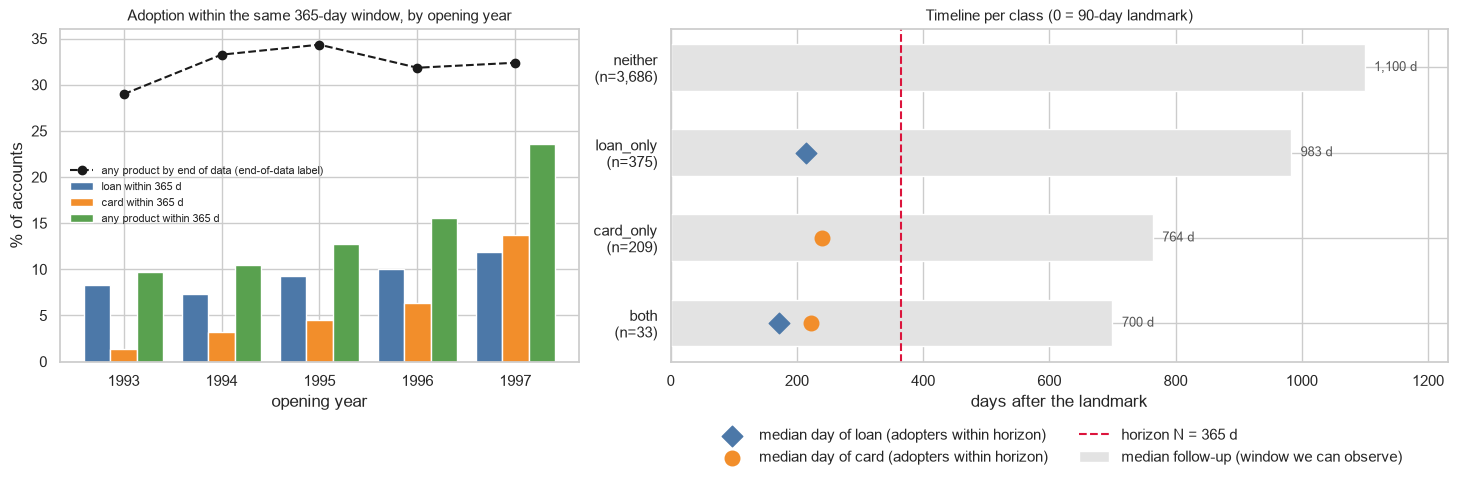

,n,loan %,card %,any %,any by end of data %
open_year,,,,,
1993,1139,8.300,1.400,9.700,29.000
1994,439,7.300,3.200,10.500,33.300
1995,661,9.200,4.500,12.700,34.300
1996,1363,10.100,6.300,15.600,31.800
1997,701,11.800,13.700,23.500,32.400


In [22]:
# left: adoption within the SAME horizon by opening year (the cohort effect); right: timeline per class
H = HORIZON_DAYS
by_year = model_df.groupby("open_year").agg(n=("y", "size"), loan=("loan_H", "mean"), card=("card_H", "mean"),
                                           any_H=("y", lambda s: (s > 0).mean()), any_end=("y_end", lambda s: (s > 0).mean()))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 1.5]})
x, w_ = np.arange(len(by_year)), 0.27
ax1.bar(x - w_, 100 * by_year["loan"], w_, color="#4C78A8", label=f"loan within {H} d")
ax1.bar(x, 100 * by_year["card"], w_, color="#F28E2B", label=f"card within {H} d")
ax1.bar(x + w_, 100 * by_year["any_H"], w_, color="#59A14F", label=f"any product within {H} d")
ax1.plot(x, 100 * by_year["any_end"], "k--o", label="any product by end of data (end-of-data label)")
ax1.set_xticks(x); ax1.set_xticklabels(by_year.index)
ax1.set(title=f"Adoption within the same {H}-day window, by opening year", xlabel="opening year", ylabel="% of accounts"); ax1.legend(fontsize=8, frameon=False)

tm = model_df.assign(days_to_loan=model_df["t_loan"].where(model_df["loan_H"] == 1), days_to_card=model_df["t_card"].where(model_df["card_H"] == 1))
g = tm.groupby("status4", observed=True).agg(n=("y", "size"), follow=("follow_up", "median"), loan=("days_to_loan", "median"),
                                             card=("days_to_card", "median")).reindex(CLASS_NAMES)
ypos = np.arange(len(g))[::-1]
ax2.barh(ypos, g["follow"], height=0.55, color="#E3E3E3", label="median follow-up (window we can observe)")
ax2.scatter(g["loan"], ypos, marker="D", s=110, color="#4C78A8", zorder=3, label="median day of loan (adopters within horizon)")
ax2.scatter(g["card"], ypos, marker="o", s=110, color="#F28E2B", zorder=3, label="median day of card (adopters within horizon)")
ax2.axvline(H, color="crimson", ls="--", lw=1.5, label=f"horizon N = {H} d")
for y_, f_ in zip(ypos, g["follow"]):
    ax2.text(f_ + 15, y_, f"{f_:,.0f} d", va="center", fontsize=9, color="#555")
ax2.set_yticks(ypos); ax2.set_yticklabels([f"{c}\n(n={n:,})" for c, n in zip(g.index, g["n"])])
ax2.set(title="Timeline per class (0 = 90-day landmark)", xlabel="days after the landmark", xlim=(0, g["follow"].max() * 1.12))
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, frameon=False)
plt.tight_layout(); save_fig("fig_horizon_cohort_effect"); plt.show()
display(by_year.assign(**{"loan %": 100 * by_year["loan"], "card %": 100 * by_year["card"], "any %": 100 * by_year["any_H"], "any by end of data %": 100 * by_year["any_end"]})
        [["n", "loan %", "card %", "any %", "any by end of data %"]].round(1))
save_table(by_year, "tab_cohort_effect")

**How to read the figures.** *Left:* over the **same** 365-day window, adoption rises steeply with the opening year (any product: 9.7% for 1993 accounts to 23.5% for 1997 accounts; cards alone: 1.4% to 13.7%), whereas the dashed end-of-data rate stays flat at about 29-34% because older accounts simply had more time. An end-of-data label would therefore mix window length with cohort speed. *Right:* the grey bar is the window we can observe for a typical account of each class, the red line is the 365-day horizon, and the markers show when adopters adopted inside the horizon (typically between day 170 and day 240). `neither` accounts have no marker. The class sizes in the cohort are 3,686 `neither`, 375 `loan_only`, 209 `card_only` and only 33 `both`.

### 3.2 Splits and preprocessing (fitted on the training set only)

In [23]:
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.feature_selection import mutual_info_classif

signed_log = FunctionTransformer(lambda x: np.sign(x) * np.log1p(np.abs(x)), feature_names_out="one-to-one")

def preprocess(train_ids, other_ids):
    # Fit imputation, signed-log choice, scaling, one-hot and correlation pruning on train_ids ONLY; transform the rest.
    tr = model_df.loc[train_ids]
    skew = tr[num_cols].skew()
    log_cols = skew[skew.abs() > 1].index.tolist(); lin_cols = [c for c in num_cols if c not in log_cols]
    ohe = lambda: OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    tree_pre = ColumnTransformer([("num", SimpleImputer(strategy="median"), num_cols), ("bin", "passthrough", bin_cols),
                                  ("cat", ohe(), cat_cols)], verbose_feature_names_out=False).set_output(transform="pandas")
    scaled_pre = ColumnTransformer([
        ("log", Pipeline([("imp", SimpleImputer(strategy="median")), ("log", signed_log), ("sc", StandardScaler())]), log_cols),
        ("lin", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), lin_cols),
        ("bin", "passthrough", bin_cols), ("cat", ohe(), cat_cols)], verbose_feature_names_out=False).set_output(transform="pandas")
    tree_pre.fit(tr[feature_cols]); scaled_pre.fit(tr[feature_cols])
    Xt_tr, Xs_tr = tree_pre.transform(tr[feature_cols]), scaled_pre.transform(tr[feature_cols])
    # redundancy pruning: for every pair with |Spearman| > 0.90 drop the predictor with lower mutual information
    corr = Xs_tr[num_cols].corr(method="spearman").abs()
    mi = pd.Series(mutual_info_classif(Xt_tr[num_cols], tr["y"], random_state=RANDOM_STATE), index=num_cols)
    pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().dropna()
    drop = []
    for (a, b_), rho in pairs[pairs > 0.90].sort_values(ascending=False).items():
        if a in drop or b_ in drop: continue
        drop.append(a if mi[a] < mi[b_] else b_)
    keep_t, keep_s = [c for c in Xt_tr.columns if c not in drop], [c for c in Xs_tr.columns if c not in drop]
    out = {"train": {"tree": Xt_tr[keep_t], "scaled": Xs_tr[keep_s]}}
    for name, ids in other_ids.items():
        part = model_df.loc[ids, feature_cols]
        out[name] = {"tree": tree_pre.transform(part)[keep_t], "scaled": scaled_pre.transform(part)[keep_s]}
    return out, {"log_transformed": log_cols, "dropped_redundant": sorted(drop)}

# ---- primary split: time-based (train = accounts opened before 1997, test = 1997 accounts with a full horizon)
train_ids = model_df.index[model_df["open_date"] < TEMPORAL_SPLIT_DATE]
test_ids = model_df.index[model_df["open_date"] >= TEMPORAL_SPLIT_DATE]
# ---- secondary split: random, stratified on the four-class label (same accounts), used for the robustness comparison
rand_train_ids, rand_test_ids = train_test_split(model_df.index, test_size=0.20, stratify=model_df["y"], random_state=RANDOM_STATE)
rand_train_ids, rand_test_ids = pd.Index(sorted(rand_train_ids)), pd.Index(sorted(rand_test_ids))
P, prep_info = preprocess(train_ids, {"test": test_ids})
X_train_tree, X_test_tree = P["train"]["tree"], P["test"]["tree"]
X_train_scaled, X_test_scaled = P["train"]["scaled"], P["test"]["scaled"]
lab_cols = ["y", "status4", "y_end", "t_loan", "e_loan", "t_card", "e_card", "follow_up", "open_date", "open_year"]
lab_train, lab_test = model_df.loc[train_ids, lab_cols], model_df.loc[test_ids, lab_cols]
y_train, y_test = lab_train["y"].values, lab_test["y"].values

# two expanding-window folds inside the training set (train on earlier years, validate on the next year; used for tuning in the next stage)
yr = model_df.loc[train_ids, "open_year"].values
cv_folds = [(list(map(int, train_ids[yr <= v - 1])), list(map(int, train_ids[yr == v]))) for v in (1995, 1996)]

mix = pd.DataFrame({"accounts": [len(train_ids), len(test_ids)], "share": [len(train_ids) / len(model_df), len(test_ids) / len(model_df)]}, index=["train", "test"])
for k, c in enumerate(CLASS_NAMES):
    mix[c + " %"] = [100 * (y_train == k).mean(), 100 * (y_test == k).mean()]
mix["both (n)"] = [(y_train == 3).sum(), (y_test == 3).sum()]
display(mix.round(1))
print("Opening years in each split:")
display(pd.DataFrame({"train": model_df.loc[train_ids, "open_year"].value_counts(), "test": model_df.loc[test_ids, "open_year"].value_counts()}).fillna(0).astype(int).sort_index().T)
print(f"Majority-class accuracy on test: {100 * (y_test == 0).mean():.1f}%")
print(f"Matrices: {X_train_tree.shape} train / {X_test_tree.shape} test | NaNs: {int(X_train_tree.isna().sum().sum() + X_test_scaled.isna().sum().sum())}"
      f" | log-transformed: {len(prep_info['log_transformed'])} | dropped as redundant: {len(prep_info['dropped_redundant'])}")
print("Dropped:", prep_info["dropped_redundant"])

# ---- save everything for the next stage
X_train_tree.to_csv(OUT_DIR / "X_train_tree.csv"); X_test_tree.to_csv(OUT_DIR / "X_test_tree.csv")
X_train_scaled.to_csv(OUT_DIR / "X_train_scaled.csv"); X_test_scaled.to_csv(OUT_DIR / "X_test_scaled.csv")
lab_train.to_csv(OUT_DIR / "labels_train.csv"); lab_test.to_csv(OUT_DIR / "labels_test.csv")
json.dump({"split": "time-based: opened before 1997 (train) / 1997 (test)", "random_state": RANDOM_STATE, "class_names": CLASS_NAMES, "landmark_days": LANDMARK_DAYS, "horizon_days": HORIZON_DAYS,
           "cv_folds_expanding_window": cv_folds, "random_split": {"train": list(map(int, rand_train_ids)), "test": list(map(int, rand_test_ids))}, **prep_info}, open(OUT_DIR / "preprocessing_info.json", "w"))
pickle.dump({"train": {int(i): sequences[int(i)] for i in train_ids}, "test": {int(i): sequences[int(i)] for i in test_ids},
             "columns": SEQ_COLS, "vocab": VOCAB, "landmark_days": LANDMARK_DAYS}, open(OUT_DIR / "sequences.pkl", "wb"))
save_table(mix, "tab_split_mix")

,accounts,share,neither %,loan_only %,card_only %,both %,both (n)
train,3602,0.800,87.500,8.500,3.500,0.500,19
test,701,0.200,76.500,9.800,11.700,2.000,14


Opening years in each split:


open_year,1993,1994,1995,1996,1997
train,1139,439,661,1363,0
test,0,0,0,0,701


Majority-class accuracy on test: 76.5%
Matrices: (3602, 41) train / (701, 41) test | NaNs: 0 | log-transformed: 21 | dropped as redundant: 14
Dropped: ['active_days', 'amt_mean', 'amt_std', 'bal_max', 'bal_mean', 'bal_min', 'bal_std', 'credit_sum', 'debit_sum', 'n_debit', 'n_txn', 'net_flow', 'spend_to_income', 'unemp96']


### 3.3 Preprocessing diagnostics

Checks on the training accounts: how the signed log changes the most skewed predictors, how far the 1997 cohort drifts from the training statistics, and which predictors carry signal before any model is fitted.

,training-set skew
signed-log transformed (kept after pruning),
bal_open,12.790
share_xfer_out,9.460
days_since_last_txn,4.060
population,2.140
interest_sum,1.800
amt_median,1.770
gap_mean,1.610
avg_salary,1.300
crime_rate96,1.300


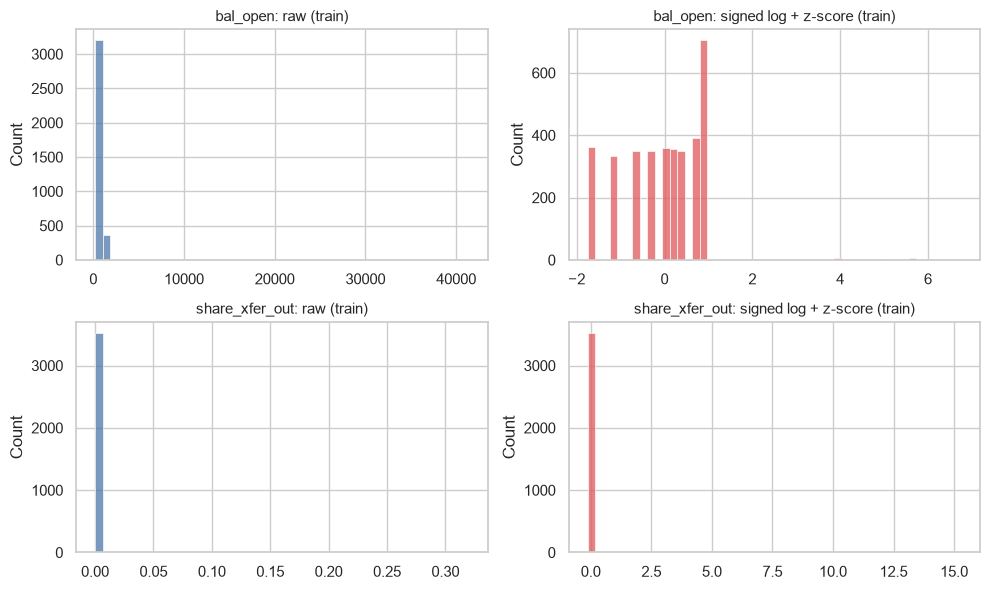

,|mean| of test z-scores (cohort drift)
age_at_open,0.117
bal_open,0.082
days_since_last_txn,0.075
unemp95,0.068
unemp_change,0.066
population,0.061


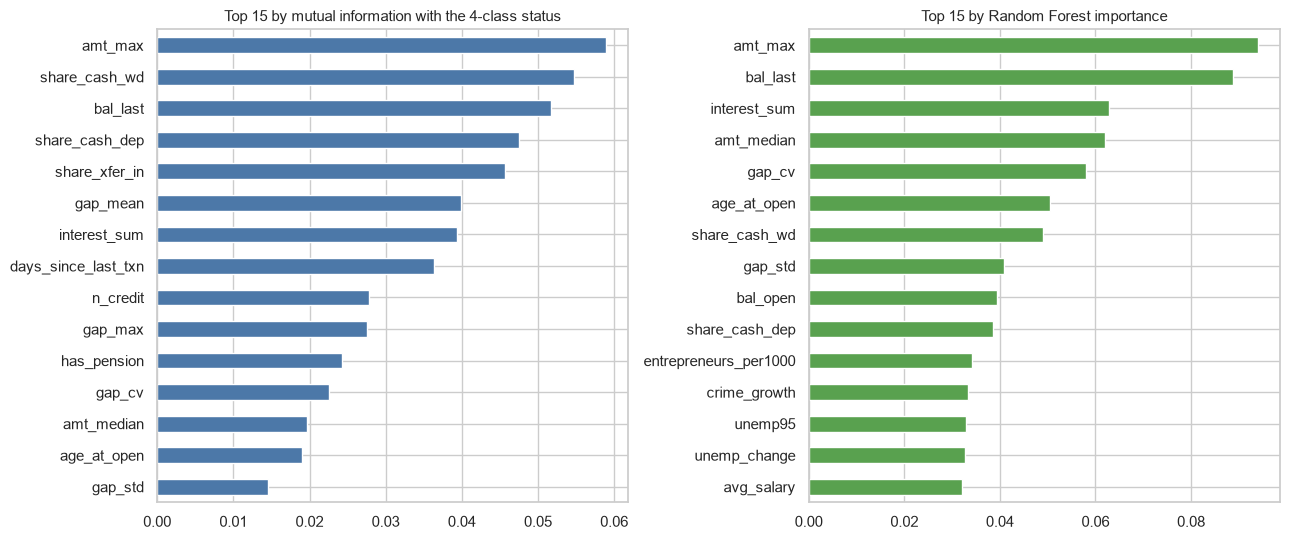

,in both top-10 rankings
0,amt_max
1,bal_last
2,interest_sum
3,share_cash_dep
4,share_cash_wd


In [24]:
# ---- 3.3 Preprocessing diagnostics (training accounts only): skew before/after the signed log, cohort drift, and which predictors carry signal
from sklearn.ensemble import RandomForestClassifier
tr_raw = model_df.loc[train_ids]
shown = [c for c in prep_info["log_transformed"] if c in X_train_scaled.columns]
skew_tr = tr_raw[shown].skew().sort_values(key=abs, ascending=False)
display(skew_tr.round(2).head(10).to_frame("training-set skew").rename_axis("signed-log transformed (kept after pruning)"))
fig, ax = plt.subplots(2, 2, figsize=(10, 6))
for r, c in enumerate(skew_tr.index[:2]):
    sns.histplot(tr_raw[c], bins=50, ax=ax[r, 0], color="#4C78A8"); ax[r, 0].set(title=f"{c}: raw (train)", xlabel="")
    sns.histplot(X_train_scaled[c], bins=50, ax=ax[r, 1], color="#E15759"); ax[r, 1].set(title=f"{c}: signed log + z-score (train)", xlabel="")
plt.tight_layout(); save_fig("fig_scaling_effect"); plt.show()

# the test set is scaled with TRAINING statistics, so any gap measures how far the 1997 cohort sits from the earlier cohorts
drift = X_test_scaled[[c for c in num_cols if c in X_test_scaled.columns]].mean().abs().sort_values(ascending=False)
display(drift.head(6).round(3).to_frame("|mean| of test z-scores (cohort drift)"))

# which predictors carry signal: mutual information and Random Forest impurity importance on the training set
discrete = np.array([c in bin_cols or c.startswith(("frequency_", "region_")) for c in X_train_tree.columns])
mi_ = pd.Series(mutual_info_classif(X_train_tree, y_train, discrete_features=discrete, random_state=RANDOM_STATE), index=X_train_tree.columns)
rf_ = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=-1).fit(X_train_tree, y_train)
imp_ = pd.Series(rf_.feature_importances_, index=X_train_tree.columns)
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
mi_.sort_values().tail(15).plot.barh(ax=ax[0], color="#4C78A8"); ax[0].set_title("Top 15 by mutual information with the 4-class status")
imp_.sort_values().tail(15).plot.barh(ax=ax[1], color="#59A14F"); ax[1].set_title("Top 15 by Random Forest importance")
plt.tight_layout(); save_fig("fig_feature_signal"); plt.show()
display(pd.Series(sorted(set(mi_.nlargest(10).index) & set(imp_.nlargest(10).index)), name="in both top-10 rankings").to_frame())
save_table(pd.DataFrame({"mutual_information": mi_, "rf_importance": imp_}).sort_values("rf_importance", ascending=False), "tab_feature_signal")

## 4. Models and initial evaluation

### 4.1 Model selection and training

#### Models selected and why

The task is a **four-class classification** of product adoption within a fixed 365-day horizon (`neither`, `loan_only`, `card_only`, `both`) with strong imbalance (about 86/9/5/1% overall, but only 77% `neither` in the 1997 test cohort) on 4,303 accounts and about 40 mixed numeric/binary/one-hot predictors, plus a **time-to-adoption** target with right-censoring and a raw **event stream** per account. That motivates one model family per question, from the simplest reference up to a continuous-time neural model. Random seed 42 everywhere; all models are trained on the training split only.

| Model | How it works | Why it suits this project |
|---|---|---|
| **Prior baseline** (`DummyClassifier`) | Always predicts the most frequent class; probabilities are the training class frequencies. | Defines the floor under imbalance: about 77% accuracy on the 1997 test cohort and an AUC of 0.5 with no skill. Every other model must beat it on macro-F1 and AUC, not accuracy. |
| **ElasticNet multinomial logistic regression** (`saga`) | Linear softmax model with a mix of L1 (feature selection) and L2 (shrinkage) penalties, on the scaled matrix. | Interpretable, fast, robust to the many correlated cash-flow predictors, and the reference for how much a linear model already explains. |
| **LightGBM** (flat 90-day features) | Gradient-boosted decision trees grown leaf-wise on the unscaled matrix. | Handles skew, interactions and mixed types without scaling, and tree ensembles are strong on medium-sized tabular data. Used as the strong hand-engineered-feature benchmark. |
| **Cause-specific Cox** (one per product) | Proportional-hazards regression of time to loan and time to card from the landmark, each product with its own censoring (end of 1998). | Uses *when* adoption happens and handles censoring explicitly, which a classifier ignores. Loans and cards are not competing events (a customer can take both), so each product keeps its own clock. |
| **Random Survival Forest** (one per product) | Forest of survival trees that split on log-rank statistics and average cumulative hazards. | Tests whether non-linear effects and interactions improve time-to-adoption ranking over the linear Cox model, with no proportional-hazards assumption. |
| **RMTPP-style GRU** | A GRU reads the 90-day transaction stream (log gap since the previous event, log amount, time in window, embedded type/operation/purpose marks) and is combined with the static predictors. Two heads: a 4-class softmax and RMTPP exponential intensities `log λ(t) = a(h) + w·t` for loan and card, trained with the censored point-process likelihood. | Tests the central hypothesis: does modelling the *continuous arrival of events* beat hand-aggregated 90-day features? The Du et al. (2016) RMTPP predicts the next event inside a stream. Here the same intensity-plus-marks idea is adapted to predict adoption *after* the landmark, so it is called "RMTPP-style". |

**From survival output to four classes.** For each account the survival models give the probability of adopting a loan, `p_loan`, and a card, `p_card`, within 365 days of the landmark (the same window that defines the label). Treating the two adoptions as independent, the class probabilities are `neither = (1-p_loan)(1-p_card)`, `loan_only = p_loan(1-p_card)`, `card_only = (1-p_loan)p_card` and `both = p_loan·p_card`. This independence assumption is an approximation and probably understates `both`. The C-index (ranking of adopters by predicted risk) is reported separately for each product.

**Initial versions.** All models are trained here with near-default settings and no class weighting; hyperparameter tuning, feature selection and a recalibrated decision rule follow in Section 5.

#### Shared evaluation helpers

In [25]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score, confusion_matrix
from sksurv.metrics import concordance_index_censored

SHORT = ["neither", "loan", "card", "both"]
PROBA, CINDEX, METRICS = {}, {}, {}       # test-set probabilities, survival C-indices, metric rows (filled as models are trained)

def metrics_row(y_true, proba, w=None):
    # argmax decision; macro-F1, one-vs-rest AUC and per-class recall as required for the imbalanced 4-class target
    pred = (proba if w is None else proba * np.asarray(w)).argmax(1)       # optional class weights (Section 5.3)
    rec = recall_score(y_true, pred, average=None, labels=[0, 1, 2, 3], zero_division=0)
    row = {"accuracy": accuracy_score(y_true, pred),
           "macro_precision": precision_score(y_true, pred, average="macro", zero_division=0),
           "macro_recall": recall_score(y_true, pred, average="macro", zero_division=0),
           "macro_f1": f1_score(y_true, pred, average="macro", zero_division=0),
           "ovr_auc_macro": roc_auc_score(y_true, proba, multi_class="ovr", average="macro", labels=[0, 1, 2, 3])}
    row.update({f"recall_{c}": r for c, r in zip(CLASS_NAMES, rec)})
    row.update({f"auc_{c}": roc_auc_score((y_true == k).astype(int), proba[:, k]) for k, c in enumerate(CLASS_NAMES)})
    return row

def evaluate(name, y_true, proba):
    # metrics_row + store the result for the comparison tables
    row = metrics_row(y_true, proba); METRICS[name] = row; PROBA[name] = proba
    return row

def four_class(p_loan, p_card):
    # independent product adoptions -> [neither, loan_only, card_only, both]; rows sum to 1
    return np.column_stack([(1 - p_loan) * (1 - p_card), p_loan * (1 - p_card), (1 - p_loan) * p_card, p_loan * p_card])

def cindex(lab, prod, risk):
    return concordance_index_censored(lab[f"e_{prod}"].astype(bool).values, lab[f"t_{prod}"].astype(float).values, np.asarray(risk))[0]

#### Baselines: prior, ElasticNet logistic regression, LightGBM

In [26]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from lightgbm import LGBMClassifier

t0 = time.time()
# 1) prior baseline: always predicts the most frequent class, probabilities = training class frequencies
dummy = DummyClassifier(strategy="prior").fit(X_train_tree, y_train)
evaluate("Prior baseline", y_test, dummy.predict_proba(X_test_tree))

# 2) multinomial logistic regression with ElasticNet penalty (needs scaled inputs)
enet = LogisticRegression(C=1.0, l1_ratio=0.5, solver="saga", max_iter=5000, random_state=RANDOM_STATE).fit(X_train_scaled, y_train)
evaluate("ElasticNet LR", y_test, enet.predict_proba(X_test_scaled))

# 3) LightGBM on the original-unit (tree) matrix, near-default settings: the untuned reference point
lgbm = LGBMClassifier(objective="multiclass", n_estimators=200, learning_rate=0.05, random_state=RANDOM_STATE, verbose=-1, n_jobs=-1)
lgbm.fit(X_train_tree, y_train)
evaluate("LightGBM", y_test, lgbm.predict_proba(X_test_tree))
print(f"trained 3 baselines in {time.time() - t0:.1f}s | ElasticNet non-zero coefficients: {int((np.abs(enet.coef_) > 1e-8).sum())} of {enet.coef_.size}")
display(pd.DataFrame(METRICS).T[["accuracy", "macro_f1", "ovr_auc_macro"]].round(3))

trained 3 baselines in 41.2s | ElasticNet non-zero coefficients: 106 of 164


,accuracy,macro_f1,ovr_auc_macro
Prior baseline,0.765,0.217,0.500
ElasticNet LR,0.763,0.216,0.780
LightGBM,0.763,0.254,0.763


#### Time-aware models: cause-specific Cox and Random Survival Forest

In [27]:
from lifelines import CoxPHFitter
from sksurv.ensemble import RandomSurvivalForest
from sksurv.util import Surv

horizon_te = np.full(len(lab_test), float(HORIZON_DAYS))     # every account is scored at the same horizon
t0 = time.time()

def cox_cif(cph, X, t_eval):
    # P(adopt by t_eval) = 1 - exp(-H0(t_eval) * exp(x'b)), using lifelines' baseline cumulative hazard
    bch = cph.baseline_cumulative_hazard_.iloc[:, 0]
    idx = np.searchsorted(bch.index.values, t_eval, side="right") - 1
    H0 = np.where(idx >= 0, bch.values[np.clip(idx, 0, None)], 0.0)
    return 1 - np.exp(-H0 * cph.predict_partial_hazard(X).values)

def rsf_cif(rsf, X, t_eval):
    S = rsf.predict_survival_function(X, return_array=True)
    idx = np.searchsorted(rsf.unique_times_, t_eval, side="right") - 1
    return 1 - np.where(idx >= 0, S[np.arange(len(X)), np.clip(idx, 0, None)], 1.0)

cox, rsf, p_cox, p_rsf = {}, {}, {}, {}
for prod in ["loan", "card"]:
    # cause-specific Cox (ridge-penalised for the collinear one-hot and economic columns), scaled matrix
    d = X_train_scaled.copy(); d["T"], d["E"] = lab_train[f"t_{prod}"].values.astype(float), lab_train[f"e_{prod}"].values
    cox[prod] = CoxPHFitter(penalizer=0.1, l1_ratio=0.0).fit(d, "T", "E")
    p_cox[prod] = cox[prod].predict_partial_hazard(X_test_scaled).values
    # cause-specific Random Survival Forest, tree matrix
    ysurv = Surv.from_arrays(event=lab_train[f"e_{prod}"].astype(bool).values, time=lab_train[f"t_{prod}"].astype(float).values)
    rsf[prod] = RandomSurvivalForest(n_estimators=200, min_samples_leaf=15, max_features="sqrt", n_jobs=-1, random_state=RANDOM_STATE).fit(X_train_tree, ysurv)
    p_rsf[prod] = rsf[prod].predict(X_test_tree)

CINDEX["Cox (cause-specific)"] = {p: cindex(lab_test, p, p_cox[p]) for p in ["loan", "card"]}
CINDEX["RSF (cause-specific)"] = {p: cindex(lab_test, p, p_rsf[p]) for p in ["loan", "card"]}

# four-class probabilities: P(loan within the horizon) and P(card within the horizon), combined as independent events
cif_cox = {p: cox_cif(cox[p], X_test_scaled, horizon_te) for p in ["loan", "card"]}
cif_rsf = {p: rsf_cif(rsf[p], X_test_tree, horizon_te) for p in ["loan", "card"]}
evaluate("Cox (cause-specific)", y_test, four_class(cif_cox["loan"], cif_cox["card"]))
evaluate("RSF (cause-specific)", y_test, four_class(cif_rsf["loan"], cif_rsf["card"]))
print(f"survival models fitted in {time.time() - t0:.1f}s")
display(pd.DataFrame(CINDEX).T.rename(columns={"loan": "C-index loan", "card": "C-index card"}).round(3))
display(pd.DataFrame({"Cox hazard ratio (loan)": np.exp(cox["loan"].params_), "Cox hazard ratio (card)": np.exp(cox["card"].params_)})
        .assign(m=lambda d: (np.log(d.iloc[:, 0]).abs() + np.log(d.iloc[:, 1]).abs())).sort_values("m", ascending=False).drop(columns="m").head(8).round(2))

del rsf; gc.collect()   # the forests are large (a survival curve is stored per leaf): free them once the predictions exist

survival models fitted in 22.2s


,C-index loan,C-index card
Cox (cause-specific),0.747,0.746
RSF (cause-specific),0.791,0.766


,Cox hazard ratio (loan),Cox hazard ratio (card)
covariate,,
has_insurance,1.730,0.820
has_pension,0.650,0.800
amt_max,1.280,1.250
frequency_weekly,1.320,0.890
frequency_monthly,0.760,1.110
bal_last,1.150,1.240
has_fees,0.860,0.850
frequency_per_transaction,1.250,0.920


198

#### RMTPP-style GRU on the 90-day event sequences

**Why the GRU trains in a separate process.** On macOS, PyTorch bundles its own OpenMP runtime (`libiomp5`), which can crash or hang when it shares a Python process with LightGBM or scikit-learn (each loads `libomp`). To keep the notebook robust on every machine, the GRU code below is written to `rmtpp_worker.py` and run as a **subprocess**. The notebook prepares the NumPy inputs, the worker trains the network and returns the predictions, and the evaluation continues as before. Training progress is streamed to the cell output.

In [28]:
%%writefile rmtpp_worker.py
# RMTPP-style GRU trainer, run as its own Python process (see the note above).
import os, sys, time, pickle
os.environ.setdefault("OMP_NUM_THREADS", "1"); os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
torch.set_num_threads(1)

class RMTPPStyle(nn.Module):
    # GRU over the 90-day event stream (gap, amount, time + embedded marks) -> shared body -> 4-class head and
    # RMTPP-style exponential intensities log lambda_p(t) = a_p(h) + w_p * t for loan and card, t = years since landmark.
    def __init__(self, n_static, hid=32, emb=4, body=64, drop=0.2):
        super().__init__()
        self.e_type, self.e_op, self.e_ks = nn.Embedding(3, emb), nn.Embedding(6, emb), nn.Embedding(8, emb)
        self.gru = nn.GRU(3 + 3 * emb, hid, batch_first=True)
        self.body = nn.Sequential(nn.Linear(hid + n_static, body), nn.ReLU(), nn.Dropout(drop))
        self.cls, self.a, self.w = nn.Linear(body, 4), nn.Linear(body, 2), nn.Parameter(torch.zeros(2))
    def forward(self, cont, cat, lens, static):
        x = torch.cat([cont, self.e_type(cat[..., 0]), self.e_op(cat[..., 1]), self.e_ks(cat[..., 2])], -1)
        _, h = self.gru(nn.utils.rnn.pack_padded_sequence(x, lens.cpu(), batch_first=True, enforce_sorted=False))
        z = self.body(torch.cat([h[-1], static], 1))
        return self.cls(z), self.a(z).clamp(-10, 3), self.w.clamp(-2, 2)

def cum_haz(a, w, t):       # Lambda(t) = exp(a) * (exp(w t) - 1) / w  (closed form of the integrated intensity)
    small = w.abs() < 1e-4
    return torch.exp(a) * torch.where(small, t, torch.expm1(w * t) / torch.where(small, torch.ones_like(w), w))

def tens(d, idx=None):
    return {k: torch.as_tensor(v if idx is None else v[idx]) for k, v in d.items()}

def batch_losses(model, b, class_w=None):
    logits, a, w = model(b["cont"], b["cat"], b["lens"], b["static"])
    ll = (b["e"] * (a + w * b["t"]) - cum_haz(a, w, b["t"])).sum(1)     # event: log lambda(t) - Lambda(t); censored: -Lambda(t)
    return F.cross_entropy(logits, b["y"], weight=class_w), -ll.mean()

def four_class(p_loan, p_card):
    return np.column_stack([(1 - p_loan) * (1 - p_card), p_loan * (1 - p_card), (1 - p_loan) * p_card, p_loan * p_card])

def train_rmtpp(tr, va, class_w=None, seed=42, epochs=80, patience=10, lr=3e-3, wd=1e-4, lam=1.0, bs=128, verbose=True, **kw):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    model = RMTPPStyle(tr["static"].shape[1], **kw); opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    cw = None if class_w is None else torch.as_tensor(class_w, dtype=torch.float32)
    best, best_state, bad, vb, t0 = np.inf, None, 0, tens(va), time.time()
    for ep in range(epochs):
        model.train(); perm = rng.permutation(len(tr["y"]))
        for s in range(0, len(perm), bs):
            ce, nll = batch_losses(model, tens(tr, perm[s:s + bs]), cw); opt.zero_grad(); (ce + lam * nll).backward(); opt.step()
        model.eval()
        with torch.no_grad(): vce, vnll = batch_losses(model, vb, cw)
        val = float(vce + lam * vnll)
        if verbose and (ep % 5 == 0 or bad >= patience - 1):
            print(f"  epoch {ep + 1:3d} | val loss {val:.4f} | best {best:.4f} | no-improve {bad} | {time.time() - t0:.0f}s", flush=True)
        if val < best - 1e-4:
            best, bad, best_state = val, 0, {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(best_state); model.eval(); model.epochs_run = ep + 1
    return model

def predict_rmtpp(model, d):
    b = tens(d)
    with torch.no_grad():
        logits, a, w = model(b["cont"], b["cat"], b["lens"], b["static"])
        p_cls = F.softmax(logits, 1).numpy()
        cif = 1 - torch.exp(-cum_haz(a, w, b["horizon"][:, None].expand(-1, 2))).numpy()     # P(adopt within the horizon)
        risk = cum_haz(a, w, torch.ones_like(a)).numpy()                                      # 1-year cumulative hazard as ranking score
    return p_cls, four_class(cif[:, 0], cif[:, 1]), risk

if __name__ == "__main__":
    payload, out = pickle.load(open(sys.argv[1], "rb")), {}
    for run in payload["runs"]:
        kwargs = {k: v for k, v in run.items() if k != "name"}; t0 = time.time()
        print(f"training run '{run['name']}' ({torch.__version__}, {torch.get_num_threads()} thread(s))", flush=True)
        model = train_rmtpp(payload["train"], payload["val"], **kwargs)
        out[run["name"]] = {"predict": {k: predict_rmtpp(model, d) for k, d in payload["predict"].items()},
                            "epochs": model.epochs_run, "n_params": sum(p.numel() for p in model.parameters()),
                            "w": [round(float(x), 2) for x in model.w.detach().numpy()], "seconds": time.time() - t0}
    pickle.dump(out, open(sys.argv[2], "wb")); print("worker finished", flush=True)

Overwriting rmtpp_worker.py


In [29]:
import subprocess, sys
MAXLEN = max(len(s) for s in sequences.values())

def pack(ids, lab, Xs, static_cols):
    # NumPy arrays for the worker: padded event sequences, static predictors, labels and per-product survival targets
    n = len(ids); cont = np.zeros((n, MAXLEN, 3), np.float32); cat = np.zeros((n, MAXLEN, 3), np.int64); lens = np.zeros(n, np.int64)
    for k, i in enumerate(ids):
        s = sequences[int(i)]; m = len(s); lens[k] = m
        cont[k, :m, 0], cont[k, :m, 1], cont[k, :m, 2] = np.log1p(s[:, 1]), s[:, 2], s[:, 0] / LANDMARK_DAYS   # log gap, log amount, time in window
        cat[k, :m] = s[:, 3:6].astype(np.int64)                                                                  # type, operation, k-symbol ids
    L = lab.loc[ids]
    return {"cont": cont, "cat": cat, "lens": lens, "static": Xs.loc[ids, static_cols].values.astype(np.float32), "y": L["y"].values.astype(np.int64),
            "t": np.stack([L["t_loan"], L["t_card"]], 1).astype(np.float32) / 365.0, "e": np.stack([L["e_loan"], L["e_card"]], 1).astype(np.float32),
            "horizon": np.full(n, HORIZON_DAYS / 365.0, np.float32)}

def run_gru(tr_ids_all, te_ids, lab_tr, lab_te, Xs_tr, Xs_te, tag, verbose=True, runs=None):
    # inner validation split for early stopping, inputs standardised with TRAIN statistics, training in the worker process
    static_cols = [c for c in Xs_tr.columns if c in STATIC_BASE or c.startswith(("frequency_", "region_"))]
    y_in = lab_tr.loc[tr_ids_all, "y"]
    strat = y_in.where(y_in.map(y_in.value_counts()) >= 2, 0)   # a class with one member cannot be stratified: treated as class 0 for this split only
    tr_ids, va_ids = train_test_split(tr_ids_all, test_size=0.15, stratify=strat, random_state=RANDOM_STATE)
    pk_tr, pk_va, pk_te = (pack(tr_ids, lab_tr, Xs_tr, static_cols), pack(va_ids, lab_tr, Xs_tr, static_cols), pack(te_ids, lab_te, Xs_te, static_cols))
    mask = np.arange(MAXLEN)[None, :] < pk_tr["lens"][:, None]
    mu, sd = pk_tr["cont"][mask].mean(0), pk_tr["cont"][mask].std(0) + 1e-6
    for d in (pk_tr, pk_va, pk_te):
        d["cont"] = ((d["cont"] - mu) / sd) * (np.arange(MAXLEN)[None, :, None] < d["lens"][:, None, None])
    payload_path, result_path = OUT_DIR / f"rmtpp_payload_{tag}.pkl", OUT_DIR / f"rmtpp_results_{tag}.pkl"
    default_run = runs is None                                                       # runs=None: the single untuned run of Section 4
    runs = runs or [{"name": "initial", "seed": RANDOM_STATE}]
    pickle.dump({"train": pk_tr, "val": pk_va, "predict": {"test": pk_te}, "runs": runs}, open(payload_path, "wb"))
    proc = subprocess.Popen([sys.executable, "-u", "rmtpp_worker.py", str(payload_path), str(result_path)],
                            stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in proc.stdout:
        if verbose: print(line, end="")                                              # live training log
    if proc.wait() != 0: raise RuntimeError(f"rmtpp_worker.py exited with code {proc.returncode}")
    out = pickle.load(open(result_path, "rb"))
    return (out["initial"] if default_run else out), len(static_cols)

t0 = time.time()
res, n_static = run_gru(train_ids, test_ids, lab_train, lab_test, X_train_scaled, X_test_scaled, tag="primary")
p_cls, p_haz, risk = res["predict"]["test"]
evaluate("RMTPP-style (class head)", y_test, p_cls)
evaluate("RMTPP-style (intensity head)", y_test, p_haz)
CINDEX["RMTPP-style GRU"] = {p: cindex(lab_test, p, risk[:, k]) for k, p in enumerate(["loan", "card"])}
print(f"GRU: {res['n_params']:,} parameters, stopped after {res['epochs']} epochs, {res['seconds']:.0f}s in the worker, {time.time() - t0:.0f}s in total | "
      f"static inputs: {n_static} | learned time-drift w (loan, card) = {res['w']} per year")

training run 'initial' (2.2.2, 1 thread(s))
  epoch   1 | val loss 2.1156 | best inf | no-improve 0 | 1s
  epoch   6 | val loss 1.6576 | best 1.6639 | no-improve 0 | 2s
  epoch  11 | val loss 1.6263 | best 1.6369 | no-improve 1 | 4s
  epoch  16 | val loss 1.6189 | best 1.6204 | no-improve 2 | 8s
  epoch  21 | val loss 1.6137 | best 1.6161 | no-improve 3 | 10s
  epoch  26 | val loss 1.6254 | best 1.6137 | no-improve 4 | 16s
  epoch  31 | val loss 1.6285 | best 1.6137 | no-improve 9 | 23s
worker finished
GRU: 8,684 parameters, stopped after 31 epochs, 25s in the worker, 32s in total | static inputs: 22 | learned time-drift w (loan, card) = [-0.26, 0.04] per year


### 4.2 Initial evaluation on the test set

,accuracy,macro_precision,macro_recall,macro_f1,ovr_auc_macro,recall_neither,recall_loan_only,recall_card_only,recall_both
Prior baseline,0.765,0.191,0.250,0.217,0.500,1.000,0.000,0.000,0.000
ElasticNet LR,0.763,0.191,0.250,0.216,0.780,0.998,0.000,0.000,0.000
LightGBM,0.763,0.401,0.268,0.254,0.763,0.987,0.072,0.012,0.000
Cox (cause-specific),0.765,0.191,0.250,0.217,0.777,1.000,0.000,0.000,0.000
RSF (cause-specific),0.765,0.191,0.250,0.217,0.809,1.000,0.000,0.000,0.000
RMTPP-style (class head),0.765,0.191,0.250,0.217,0.762,1.000,0.000,0.000,0.000
RMTPP-style (intensity head),0.765,0.191,0.250,0.217,0.774,1.000,0.000,0.000,0.000


One-vs-rest AUC per class:


,auc_neither,auc_loan_only,auc_card_only,auc_both
Prior baseline,0.500,0.500,0.500,0.500
ElasticNet LR,0.773,0.794,0.717,0.837
LightGBM,0.743,0.734,0.735,0.839
Cox (cause-specific),0.759,0.744,0.734,0.870
RSF (cause-specific),0.785,0.799,0.763,0.889
RMTPP-style (class head),0.768,0.798,0.675,0.808
RMTPP-style (intensity head),0.767,0.794,0.700,0.834


Survival C-index on the test set (time-aware ranking of adopters):


,loan,card
Cox (cause-specific),0.747,0.746
RSF (cause-specific),0.791,0.766
RMTPP-style GRU,0.794,0.706


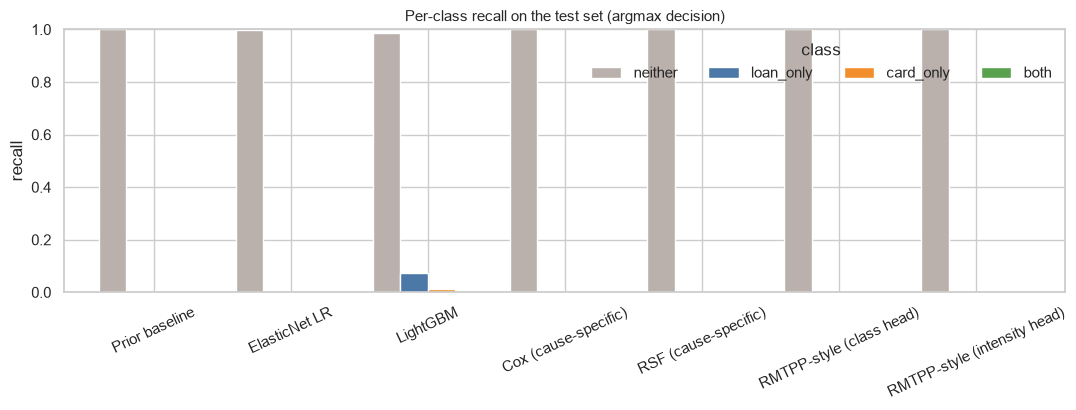

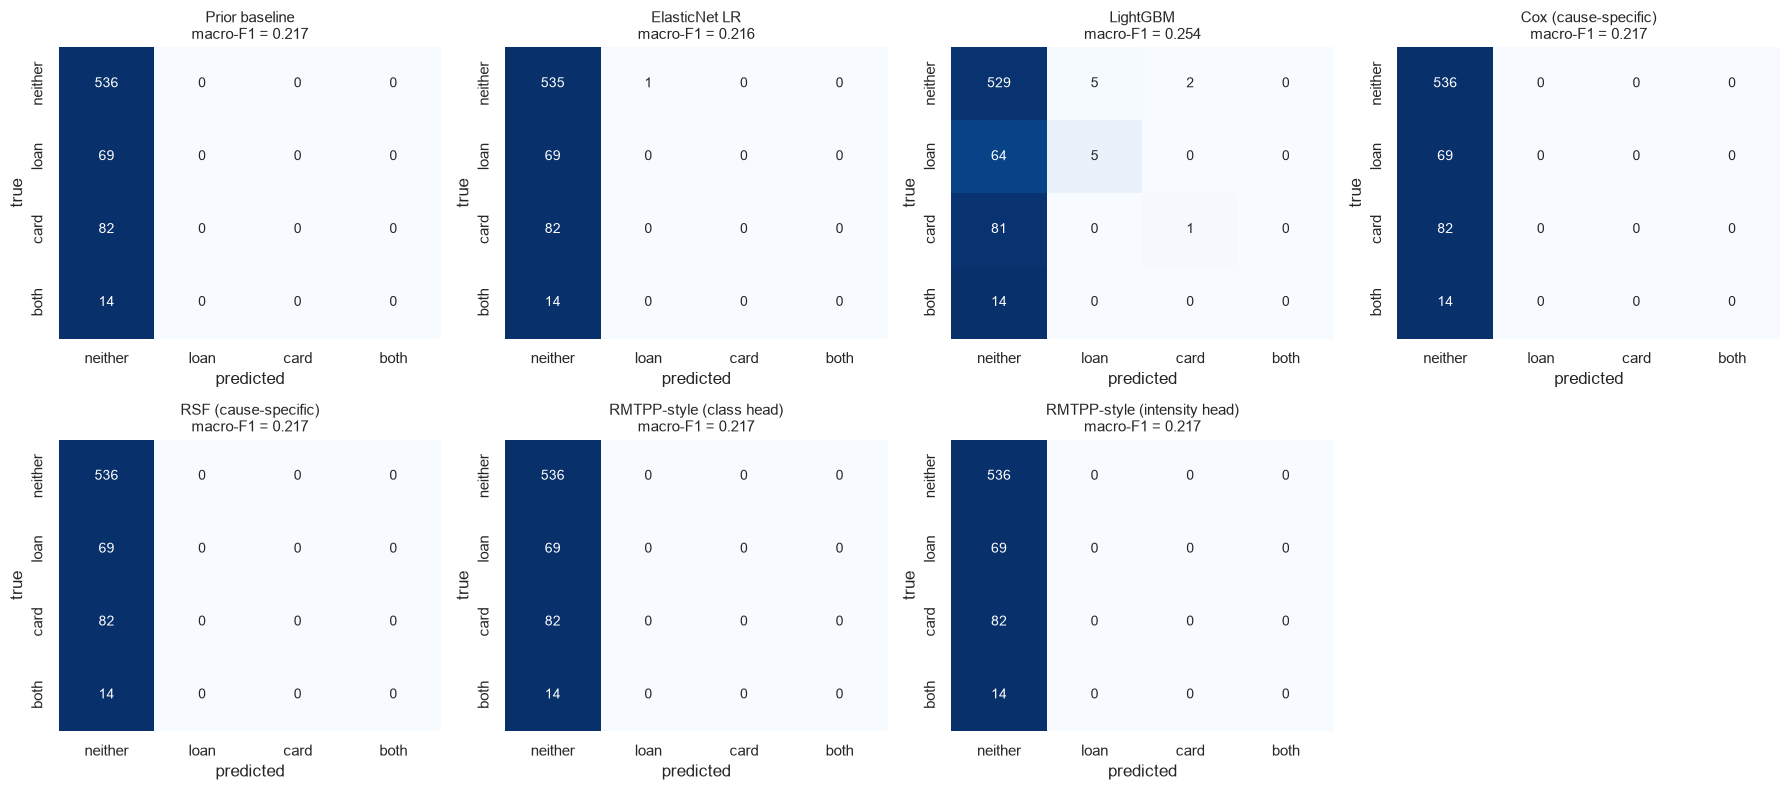

In [30]:
# ---- main results table (1 row per model, test set, argmax decision)
res = pd.DataFrame(METRICS).T
order = ["Prior baseline", "ElasticNet LR", "LightGBM", "Cox (cause-specific)", "RSF (cause-specific)", "RMTPP-style (class head)", "RMTPP-style (intensity head)"]
res = res.loc[order]
display(res[["accuracy", "macro_precision", "macro_recall", "macro_f1", "ovr_auc_macro"] + [f"recall_{c}" for c in CLASS_NAMES]].round(3))
print("One-vs-rest AUC per class:"); display(res[[f"auc_{c}" for c in CLASS_NAMES]].round(3))
print("Survival C-index on the test set (time-aware ranking of adopters):")
display(pd.DataFrame(CINDEX).T.rename(columns={"loan": "loan", "card": "card"}).round(3))

# ---- per-class recall
fig, ax = plt.subplots(figsize=(11, 4.2))
res[[f"recall_{c}" for c in CLASS_NAMES]].rename(columns=lambda c: c.replace("recall_", "")).plot(kind="bar", ax=ax, width=0.8, color=["#BAB0AC", "#4C78A8", "#F28E2B", "#59A14F"])
ax.set(title="Per-class recall on the test set (argmax decision)", ylabel="recall", ylim=(0, 1)); ax.tick_params(axis="x", rotation=25)
ax.legend(title="class", ncol=4, frameon=False); plt.tight_layout(); save_fig("fig_initial_recall"); plt.show()

# ---- confusion matrices (colour = row-normalised, numbers = counts)
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, name in zip(axes.ravel(), order):
    cm = confusion_matrix(y_test, PROBA[name].argmax(1), labels=[0, 1, 2, 3])
    sns.heatmap(cm / cm.sum(1, keepdims=True), annot=cm, fmt="d", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax, xticklabels=SHORT, yticklabels=SHORT)
    ax.set(title=f"{name}\nmacro-F1 = {METRICS[name]['macro_f1']:.3f}", xlabel="predicted", ylabel="true")
axes.ravel()[-1].axis("off"); plt.tight_layout(); save_fig("fig_initial_confusion"); plt.show()
save_table(res, "tab_initial_metrics"); save_table(pd.DataFrame(CINDEX).T, "tab_initial_cindex")

In [31]:
# per-class precision, recall and F1 (argmax decision) for every model
from sklearn.metrics import precision_recall_fscore_support
rows = {}
for name in order:
    p, r, f, _ = precision_recall_fscore_support(y_test, PROBA[name].argmax(1), labels=[0, 1, 2, 3], zero_division=0)
    rows[name] = {(c, m): v for c, pv, rv, fv in zip(CLASS_NAMES, p, r, f) for m, v in [("precision", pv), ("recall", rv), ("F1", fv)]}
per_class = pd.DataFrame(rows).T
per_class.columns = pd.MultiIndex.from_tuples(per_class.columns)
print("Per-class precision / recall / F1 on the test set:")
display(per_class.round(3))
save_table(per_class, "tab_initial_per_class")

Per-class precision / recall / F1 on the test set:


neither              loan_only              card_only                   both             
                             precision recall    F1 precision recall    F1 precision recall    F1 precision recall    F1
Prior baseline                   0.765  1.000 0.867     0.000  0.000 0.000     0.000  0.000 0.000     0.000  0.000 0.000
ElasticNet LR                    0.764  0.998 0.866     0.000  0.000 0.000     0.000  0.000 0.000     0.000  0.000 0.000
LightGBM                         0.769  0.987 0.864     0.500  0.072 0.127     0.333  0.012 0.024     0.000  0.000 0.000
Cox (cause-specific)             0.765  1.000 0.867     0.000  0.000 0.000     0.000  0.000 0.000     0.000  0.000 0.000
RSF (cause-specific)             0.765  1.000 0.867     0.000  0.000 0.000     0.000  0.000 0.000     0.000  0.000 0.000
RMTPP-style (class head)         0.765  1.000 0.867     0.000  0.000 0.000     0.000  0.000 0.000     0.000  0.000 0.000
RMTPP-style (intensity head)     0.765  1.000 0.867     0.000  0.000 0.000     0.000  0.000 0.000     0.000  0.000 0.000

#### Binary view: loan within 365 days and card within 365 days (more stable than the rare `both` class)

In [32]:
# binary view of the same predictions: P(loan within horizon) = P(loan_only) + P(both), P(card within horizon) = P(card_only) + P(both)
from sklearn.metrics import average_precision_score
yl, yc = np.isin(y_test, [1, 3]).astype(int), np.isin(y_test, [2, 3]).astype(int)
rows = {}
for name in order:
    p = PROBA[name]; pl, pc = p[:, 1] + p[:, 3], p[:, 2] + p[:, 3]
    rows[name] = {"loan AUC": roc_auc_score(yl, pl), "loan PR-AUC": average_precision_score(yl, pl),
                  "card AUC": roc_auc_score(yc, pc), "card PR-AUC": average_precision_score(yc, pc)}
print(f"Test accounts with a loan within {HORIZON_DAYS} days: {yl.sum()} ({100 * yl.mean():.1f}%), with a card: {yc.sum()} ({100 * yc.mean():.1f}%)"
      f" | PR-AUC of a random ranking equals these shares")
display(pd.DataFrame(rows).T.round(3))
save_table(pd.DataFrame(rows).T, "tab_initial_binary")

Test accounts with a loan within 365 days: 83 (11.8%), with a card: 96 (13.7%) | PR-AUC of a random ranking equals these shares


,loan AUC,loan PR-AUC,card AUC,card PR-AUC
Prior baseline,0.500,0.118,0.500,0.137
ElasticNet LR,0.807,0.353,0.749,0.278
LightGBM,0.748,0.300,0.753,0.275
Cox (cause-specific),0.768,0.282,0.761,0.281
RSF (cause-specific),0.815,0.393,0.782,0.300
RMTPP-style (class head),0.812,0.346,0.696,0.236
RMTPP-style (intensity head),0.809,0.342,0.717,0.250


#### Sensitivity: end-of-data label vs fixed 365-day horizon

In [33]:
# sensitivity: the end-of-data label (adopted at any time before the end of the data) on the same accounts and the same split
y_end_tr, y_end_te = lab_train["y_end"].values, lab_test["y_end"].values
enet_e = LogisticRegression(C=1.0, l1_ratio=0.5, solver="saga", max_iter=5000, random_state=RANDOM_STATE).fit(X_train_scaled, y_end_tr)
lgbm_e = LGBMClassifier(objective="multiclass", n_estimators=200, learning_rate=0.05, random_state=RANDOM_STATE, verbose=-1, n_jobs=-1).fit(X_train_tree, y_end_tr)
rows = {}
for name, proba in [("ElasticNet LR", enet_e.predict_proba(X_test_scaled)), ("LightGBM", lgbm_e.predict_proba(X_test_tree))]:
    rows[(name, "end-of-data label")] = evaluate(f"{name} [end-of-data label]", y_end_te, proba)
    rows[(name, f"{HORIZON_DAYS}-day horizon label (primary)")] = METRICS[name]
sens = pd.DataFrame(rows).T[["accuracy", "macro_f1", "ovr_auc_macro", "recall_neither", "recall_loan_only", "recall_card_only", "recall_both"]]
print("Class shares in the test set, end-of-data label:", dict(zip(CLASS_NAMES, np.round(np.bincount(y_end_te, minlength=4) / len(y_end_te), 3))))
display(sens.round(3))
save_table(sens, "tab_sensitivity_label")

Class shares in the test set, end-of-data label: {'neither': 0.676, 'loan_only': 0.121, 'card_only': 0.167, 'both': 0.036}


accuracy  macro_f1  ovr_auc_macro  recall_neither  recall_loan_only  recall_card_only  recall_both
ElasticNet LR end-of-data label                   0.673     0.308          0.783           0.954             0.141             0.051        0.080
              365-day horizon label (primary)     0.763     0.216          0.780           0.998             0.000             0.000        0.000
LightGBM      end-of-data label                   0.666     0.351          0.756           0.911             0.200             0.137        0.080
              365-day horizon label (primary)     0.763     0.254          0.763           0.987             0.072             0.012        0.000

#### Secondary comparison: random stratified split vs time-based split

Primary test set (time-based): 701 accounts, 23.5% adopt within 365 days, 14 with both | secondary test set (random): 861 accounts, 14.4% adopt, 7 with both  (85s)


time-based split (primary)                                 random stratified split (secondary)                                
                                               macro_f1 ovr_auc_macro loan_auc card_auc                            macro_f1 ovr_auc_macro loan_auc card_auc
Prior baseline                                    0.217         0.500    0.500    0.500                               0.231         0.500    0.500    0.500
ElasticNet LR                                     0.216         0.780    0.807    0.749                               0.243         0.777    0.805    0.719
LightGBM                                          0.254         0.763    0.748    0.753                               0.264         0.774    0.788    0.744
Cox (cause-specific)                              0.217         0.777    0.768    0.761                               0.244         0.786    0.786    0.765
RSF (cause-specific)                              0.217         0.809    0.815    0.782                               0.231         0.812    0.821    0.786
RMTPP-style (class head)                          0.217         0.762    0.812    0.696                               0.270         0.799    0.823    0.747
RMTPP-style (intensity head)                      0.217         0.774    0.809    0.717                               0.243         0.807    0.834    0.749

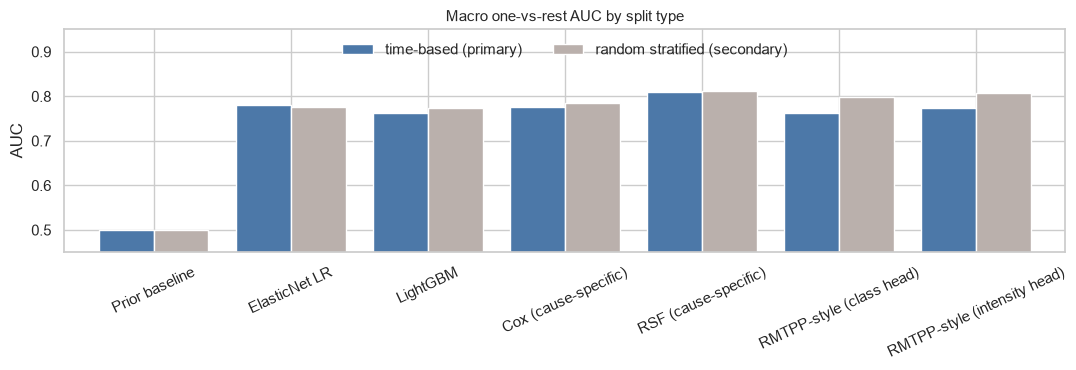

In [34]:
# secondary comparison: random stratified 80/20 split of the same accounts, same models and settings
def summary_row(y_true, proba):
    r = metrics_row(y_true, proba)
    yl, yc = np.isin(y_true, [1, 3]).astype(int), np.isin(y_true, [2, 3]).astype(int)
    return {"accuracy": r["accuracy"], "macro_f1": r["macro_f1"], "ovr_auc_macro": r["ovr_auc_macro"],
            "loan_auc": roc_auc_score(yl, proba[:, 1] + proba[:, 3]), "card_auc": roc_auc_score(yc, proba[:, 2] + proba[:, 3])}

def fit_all(tr_ids, te_ids, tag):
    P2, _ = preprocess(tr_ids, {"test": te_ids})            # preprocessing re-fitted on this split's training accounts only
    Xt_tr, Xt_te, Xs_tr, Xs_te = P2["train"]["tree"], P2["test"]["tree"], P2["train"]["scaled"], P2["test"]["scaled"]
    L_tr, L_te = model_df.loc[tr_ids, lab_cols], model_df.loc[te_ids, lab_cols]
    y_tr, y_te = L_tr["y"].values, L_te["y"].values
    horizon, out = np.full(len(te_ids), float(HORIZON_DAYS)), {}
    out["Prior baseline"] = DummyClassifier(strategy="prior").fit(Xt_tr, y_tr).predict_proba(Xt_te)
    out["ElasticNet LR"] = LogisticRegression(C=1.0, l1_ratio=0.5, solver="saga", max_iter=5000, random_state=RANDOM_STATE).fit(Xs_tr, y_tr).predict_proba(Xs_te)
    out["LightGBM"] = LGBMClassifier(objective="multiclass", n_estimators=200, learning_rate=0.05, random_state=RANDOM_STATE, verbose=-1, n_jobs=-1).fit(Xt_tr, y_tr).predict_proba(Xt_te)
    cif_c, cif_r = {}, {}
    for prod in ["loan", "card"]:
        d = Xs_tr.copy(); d["T"], d["E"] = L_tr[f"t_{prod}"].values.astype(float), L_tr[f"e_{prod}"].values
        cif_c[prod] = cox_cif(CoxPHFitter(penalizer=0.1, l1_ratio=0.0).fit(d, "T", "E"), Xs_te, horizon)
        ysv = Surv.from_arrays(event=L_tr[f"e_{prod}"].astype(bool).values, time=L_tr[f"t_{prod}"].astype(float).values)
        forest = RandomSurvivalForest(n_estimators=200, min_samples_leaf=15, max_features="sqrt", n_jobs=-1, random_state=RANDOM_STATE).fit(Xt_tr, ysv)
        cif_r[prod] = rsf_cif(forest, Xt_te, horizon)
    out["Cox (cause-specific)"], out["RSF (cause-specific)"] = four_class(cif_c["loan"], cif_c["card"]), four_class(cif_r["loan"], cif_r["card"])
    res_g, _ = run_gru(tr_ids, te_ids, L_tr, L_te, Xs_tr, Xs_te, tag=tag, verbose=False)
    out["RMTPP-style (class head)"], out["RMTPP-style (intensity head)"] = res_g["predict"]["test"][0], res_g["predict"]["test"][1]
    return {k: summary_row(y_te, v) for k, v in out.items()}, y_te

gc.collect()
t0 = time.time()
sec_rows, y_sec = fit_all(rand_train_ids, rand_test_ids, tag="random")
prim_rows = {k: summary_row(y_test, PROBA[k]) for k in order}
print(f"Primary test set (time-based): {len(y_test)} accounts, {100 * (y_test > 0).mean():.1f}% adopt within {HORIZON_DAYS} days, {int((y_test == 3).sum())} with both | "
      f"secondary test set (random): {len(y_sec)} accounts, {100 * (y_sec > 0).mean():.1f}% adopt, {int((y_sec == 3).sum())} with both  ({time.time() - t0:.0f}s)")
cmp_ = pd.concat({"time-based split (primary)": pd.DataFrame(prim_rows).T, "random stratified split (secondary)": pd.DataFrame(sec_rows).T}, axis=1)
display(cmp_.loc[:, [(s, m) for s in ["time-based split (primary)", "random stratified split (secondary)"] for m in ["macro_f1", "ovr_auc_macro", "loan_auc", "card_auc"]]].round(3))

fig, ax = plt.subplots(figsize=(11, 3.8))
pd.DataFrame({"time-based (primary)": [prim_rows[k]["ovr_auc_macro"] for k in order],
              "random stratified (secondary)": [sec_rows[k]["ovr_auc_macro"] for k in order]}, index=order).plot(kind="bar", ax=ax, width=0.8, color=["#4C78A8", "#BAB0AC"])
ax.set(title="Macro one-vs-rest AUC by split type", ylabel="AUC", ylim=(0.45, 0.95)); ax.tick_params(axis="x", rotation=25); ax.legend(frameon=False, ncol=2, loc="upper center")
plt.tight_layout(); save_fig("fig_split_comparison"); plt.show()
save_table(cmp_, "tab_split_comparison")

#### Initial performance and first impressions

**Metrics.** The 701 test accounts (opened in 1997) are 76.5% `neither`, so accuracy is almost uninformative (prior baseline 0.765, best model 0.765), and with the default argmax rule most models simply predict `neither`: five of the six models have the same macro-F1 as the baseline (0.216 to 0.217). LightGBM is the only one that predicts other classes (macro-F1 0.254); it recovers 5 of 69 `loan_only` and 1 of 82 `card_only` accounts, and no model recovers any of the 14 `both` accounts. This is an imbalance and decision-rule problem more than a lack of signal. The rank-based metrics are clearly above chance: macro one-vs-rest AUC is 0.762 to 0.809 against 0.500 for the baseline, and RSF is the most consistent ranker (macro AUC 0.809; loan AUC 0.815 with PR-AUC 0.393 against a random-ranking level of 0.118; card AUC 0.782 with PR-AUC 0.300 against 0.137; C-index 0.791 for loans and 0.766 for cards). The GRU matches RSF on loans (C-index 0.794) but is weaker on cards (0.706), and the cause-specific Cox model is the weakest on loans (C-index 0.747). With 83 loan and 96 card positives and a single seed, differences of about 0.02 are within noise, so I read the results as "RSF slightly ahead, no clear winner among the rest".

**Initial impressions.** (1) The first 90 days carry a real but modest signal (AUC about 0.75 to 0.81) that transfers to a later cohort. (2) The test cohort differs from the training data: 23.5% of the 1997 accounts adopt a product within 365 days against 12.5% of the earlier accounts (and `both` is 2.0% against 0.5%), so models trained on earlier years under-predict adoption and a 0.5-style cut-off is far too high. This prior shift affects hard-label metrics much more than AUC, and it is why class weights and a recalibrated decision rule are the first optimization steps. (3) The random stratified split of the same accounts gives macro AUCs of 0.774 to 0.812 against 0.762 to 0.809 for the time-based split. The two are close for ElasticNet, Cox and RSF (differences of at most 0.01) and further apart for LightGBM (0.011) and the GRU (0.037 for the class head, 0.033 for the intensity head), so random splitting was mildly optimistic, most for the GRU. The two test sets contain different accounts and different base rates (14.4% against 23.5% adopters), so only the AUC comparison is meaningful. (4) The sensitivity analysis shows that the label definition changes the hard-label metrics but not the ranking skill: on the end-of-data label ElasticNet and LightGBM reach macro-F1 of 0.308 and 0.351 with AUC 0.783 and 0.756, against 0.216 with 0.780 and 0.254 with 0.763 on the fixed-horizon label; the higher macro-F1 reflects the more balanced classes of the old label (68% instead of 76% `neither`). (5) The GRU, which sees only the raw event stream plus static attributes, is competitive on loans but does not beat the tabular and survival models. Section 5 adds tuning on the two expanding-window folds, feature selection and a recalibrated decision rule, and Section 6 compares the tuned with the initial models on this 1997 test set, with repeated seeds and confidence intervals.

## 5. Model optimization

This section improves the models of Section 4 in three ways, always using **training accounts only**. No tuning decision uses the 1997 test cohort: it was used in Section 4 only to score the untuned models and is used in Section 6 to score the tuned ones.

**Validation scheme.** Hyperparameters are compared with the two **expanding-window folds** defined in Section 3 (train on accounts opened 1993-94 and validate on 1995; train on 1993-95 and validate on 1996). This is the time-aware analogue of k-fold cross-validation: every validation fold lies *after* its training data, as in deployment. The complete preprocessing pipeline (imputation, signed log, scaling, one-hot encoding, correlation pruning) and the engineered features below are **re-fitted inside every fold**, so nothing leaks from validation accounts.

**Tuning objective.** Macro-F1 under the default `argmax` rule is a poor search criterion here: it is almost constant (the models predict `neither`) and extremely noisy for the rare `both` class. The search therefore maximizes the **mean of the loan PR-AUC and the card PR-AUC** for adoption within 365 days (the binary views `p_loan = p_loan_only + p_both` and `p_card = p_card_only + p_both` of every model's four-class output). PR-AUC is rank-based, focuses on the rare positive class and is comparable across all model families. Loan and card ROC-AUC are reported alongside.

**Three optimization levers.**

| Lever | What is done | Techniques |
|---|---|---|
| **Hyperparameter tuning** | Search each model family on the two validation folds | Grid search (ElasticNet, Cox, RSF) and random search (LightGBM, GRU) with time-aware cross-validation |
| **Feature engineering and selection** | Ten ratio features are added; feature sets are compared on the validation folds | Engineered ratios, LightGBM-gain top-*k* selection, PCA for the linear model |
| **Decision-rule optimization** | Class-probability weights that maximize macro-F1 on the *out-of-fold* predictions, then applied unchanged to the test set | Two weights `w_loan`, `w_card` (with `w_both = w_loan x w_card`), `w_neither = 1` |

The decision rule addresses the main weakness found in Section 4: the models rank accounts well (AUC about 0.75 to 0.81) but, with a plain `argmax`, almost never leave the majority class. An ensemble that averages the tuned models' probabilities is added as a further candidate. The final model is chosen by **cross-validation score only**, never by test performance.

In [35]:
# ---- Settings, imports and a small cache so that long searches need not be repeated
FAST_MODE = False     # True: tiny grids and few repeats, only to check that the notebook runs end to end (minutes). False: full run used for the report.
USE_CACHE = True      # reuse saved intermediate results (processed_h365/opt_cache*.pkl) when cells are re-run
N_BOOT = 200 if FAST_MODE else 1000                 # bootstrap resamples for confidence intervals
SEEDS = [42, 1, 2] if FAST_MODE else [42, 1, 2, 3, 4]   # repeated seeds for the stability check

from sklearn.decomposition import PCA
from sklearn.model_selection import ParameterGrid, ParameterSampler
from sklearn.metrics import average_precision_score, roc_curve, precision_recall_curve
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve

CACHE_PATH = OUT_DIR / ("opt_cache_fast.pkl" if FAST_MODE else "opt_cache.pkl")
CACHE = pickle.load(open(CACHE_PATH, "rb")) if (USE_CACHE and CACHE_PATH.exists()) else {}
def cached(key, fn):
    # run fn() once and keep the result on disk; later runs load it
    if key in CACHE:
        print(f"[cache] '{key}' loaded from {CACHE_PATH.name}")
    else:
        CACHE[key] = fn(); pickle.dump(CACHE, open(CACHE_PATH, "wb"))
    return CACHE[key]
print(f"FAST_MODE = {FAST_MODE} | bootstrap resamples = {N_BOOT} | seeds = {SEEDS}")

FAST_MODE = False | bootstrap resamples = 1000 | seeds = [42, 1, 2, 3, 4]


In [36]:
# ---- Setup A: engineered features and one leak-free split builder (used for every CV fold and for the final fit)
def engineered(ids):
    # ten ratio / difference features computed from each account's own 90-day window (no information from other accounts)
    d = model_df.loc[ids]; e = pd.DataFrame(index=ids)
    e["avg_credit"] = d["credit_sum"] / d["n_credit"].clip(lower=1)              # mean size of a deposit
    e["avg_debit"] = d["debit_sum"] / d["n_debit"].clip(lower=1)                 # mean size of a payment
    e["txn_per_active_day"] = d["n_txn"] / d["active_days"].clip(lower=1)        # intensity on days with activity
    e["bal_change"] = d["bal_last"] - d["bal_open"]                              # balance trajectory over the window
    e["bal_range"] = d["bal_max"] - d["bal_min"]                                 # balance volatility
    e["credit_share"] = d["n_credit"] / d["n_txn"].clip(lower=1)                 # share of incoming transactions
    e["income_to_balance"] = d["credit_sum"] / (d["bal_mean"].abs() + 1)         # inflow relative to the balance held
    e["cash_intensity"] = d["share_cash_wd"] + d["share_cash_dep"]               # reliance on cash
    e["large_txn_ratio"] = d["amt_max"] / (d["amt_median"] + 1)                  # burstiness of amounts
    e["income_vs_district"] = d["credit_sum"] / d["avg_salary"]                  # inflow relative to the local average salary
    return e.replace([np.inf, -np.inf], np.nan)

def fit_eng(tr_ids, other_ids):
    # median imputation, signed log for skewed columns and z-scoring, all fitted on the training accounts only
    e_tr = engineered(tr_ids); med = e_tr.median(); e_tr = e_tr.fillna(med)
    skew = e_tr.skew(); logc = list(skew[skew.abs() > 1].index)
    def slog(e):
        e = e.copy()
        if logc: e[logc] = np.sign(e[logc]) * np.log1p(e[logc].abs())
        return e
    s_tr = slog(e_tr); mu, sd = s_tr.mean(), s_tr.std().replace(0, 1.0)
    out = {"train": (e_tr, (s_tr - mu) / sd)}
    for k, ids in other_ids.items():
        e = engineered(ids).fillna(med); out[k] = (e, (slog(e) - mu) / sd)
    return out

def make_split(tr_ids, other_ids):
    # preprocessing (Section 3) + engineered features, all fitted on tr_ids only; other_ids are transformed
    P_, _ = preprocess(tr_ids, other_ids); eng = fit_eng(tr_ids, other_ids)
    ids_by = {"train": pd.Index(tr_ids), **{k: pd.Index(v) for k, v in other_ids.items()}}
    S = {"ids": ids_by, "lab": {}, "y": {}, "tree": {}, "scaled": {}, "eng_tree": {}, "eng_scaled": {}}
    for k, ids in ids_by.items():
        S["lab"][k] = model_df.loc[ids, lab_cols]; S["y"][k] = S["lab"][k]["y"].values
        S["tree"][k], S["scaled"][k] = P_[k]["tree"], P_[k]["scaled"]
        S["eng_tree"][k], S["eng_scaled"][k] = eng[k]
    return S

def rank_features(S, seed=RANDOM_STATE):
    # feature ranking by LightGBM gain on the TRAINING part of this split (base + engineered columns)
    X = pd.concat([S["tree"]["train"], S["eng_tree"]["train"]], axis=1)
    m = LGBMClassifier(objective="multiclass", n_estimators=150, learning_rate=0.05, num_leaves=15, colsample_bytree=0.7,
                       importance_type="gain", random_state=seed, verbose=-1, n_jobs=-1).fit(X, S["y"]["train"])
    return list(pd.Series(m.feature_importances_, index=X.columns).sort_values(ascending=False).index)

def get_X(S, kind, view, part):
    # kind: "tree" (original units) or "scaled"; view: "base" (Section 3 predictors), "eng" (base + 10 engineered), "top<k>" (k best of base + engineered)
    base = S[kind][part]
    if view == "base": return base
    full = pd.concat([base, S["eng_" + kind][part]], axis=1)
    return full if view == "eng" else full[S["rank"][:int(view[3:])]]

# ---- the two expanding-window folds (inside the training set) and the final train/test split
FOLDS = [make_split(pd.Index(tr), {"val": pd.Index(va)}) for tr, va in cv_folds]
for S in FOLDS: S["rank"] = rank_features(S)
S_FINAL = make_split(train_ids, {"test": test_ids}); S_FINAL["rank"] = rank_features(S_FINAL)
OOF_Y = np.concatenate([S["y"]["val"] for S in FOLDS]); FOLD_SIZES = [len(S["y"]["val"]) for S in FOLDS]

fold_tbl = pd.DataFrame({
    "train accounts": [len(S["y"]["train"]) for S in FOLDS], "validation accounts": FOLD_SIZES,
    "validation years": ["1995", "1996"],
    "val: loan within horizon (%)": [100 * np.isin(S["y"]["val"], [1, 3]).mean() for S in FOLDS],
    "val: card within horizon (%)": [100 * np.isin(S["y"]["val"], [2, 3]).mean() for S in FOLDS],
    "train: `both` (n)": [int((S["y"]["train"] == 3).sum()) for S in FOLDS], "val: `both` (n)": [int((S["y"]["val"] == 3).sum()) for S in FOLDS]},
    index=["fold 1", "fold 2"])
display(fold_tbl.round(1)); save_table(fold_tbl, "tab_cv_folds")
print(f"Base predictors: {S_FINAL['tree']['train'].shape[1]} | engineered: {S_FINAL['eng_tree']['train'].shape[1]} | final train {len(S_FINAL['y']['train'])} / test {len(S_FINAL['y']['test'])}")

,train accounts,validation accounts,validation years,val: loan within horizon (%),val: card within horizon (%),train: `both` (n),val: `both` (n)
fold 1,1578,661,1995,9.200,4.500,1,7
fold 2,2239,1363,1996,10.100,6.300,8,11


Base predictors: 41 | engineered: 10 | final train 3602 / test 701


In [37]:
# ---- Setup B: one fit/predict wrapper per model family: fp_*(split, params, view, part) -> (four-class probabilities, extra)
def fill4(p, classes):
    # make sure the probability matrix has all four class columns even if a class were missing from a training fold
    out = np.zeros((len(p), 4)); out[:, np.asarray(classes, int)] = p; return out

def fp_enet(S, params, view="base", part="val", seed=RANDOM_STATE):
    v = "base" if view.startswith("pca") else view
    Xtr, Xte = get_X(S, "scaled", v, "train"), get_X(S, "scaled", v, part)
    if view.startswith("pca"):                                      # PCA on the scaled predictors, fitted on the training part only
        pca = PCA(int(view[3:]), random_state=seed).fit(Xtr); Xtr, Xte = pca.transform(Xtr), pca.transform(Xte)
    m = LogisticRegression(solver="saga", max_iter=5000, random_state=seed, **params).fit(Xtr, S["y"]["train"])
    return fill4(m.predict_proba(Xte), m.classes_), m

def fp_lgbm(S, params, view="base", part="val", seed=RANDOM_STATE):
    Xtr, Xte = get_X(S, "tree", view, "train"), get_X(S, "tree", view, part)
    p = dict(params); sub = p.pop("subsample", 1.0)
    m = LGBMClassifier(objective="multiclass", subsample=sub, subsample_freq=1 if sub < 1 else 0,
                       random_state=seed, verbose=-1, n_jobs=-1, **p).fit(Xtr, S["y"]["train"])
    return fill4(m.predict_proba(Xte), m.classes_), m

def fp_cox(S, params, view="base", part="val", seed=None):
    Xtr, Xte = get_X(S, "scaled", view, "train"), get_X(S, "scaled", view, part)
    keep = Xtr.columns[Xtr.std() > 0]; Xtr, Xte = Xtr[keep], Xte[keep]   # a dummy column that is constant in a fold cannot be fitted
    H, cif, risk = np.full(len(Xte), float(HORIZON_DAYS)), {}, {}
    for prod in ["loan", "card"]:
        d = Xtr.copy(); d["T"], d["E"] = S["lab"]["train"][f"t_{prod}"].values.astype(float), S["lab"]["train"][f"e_{prod}"].values
        cph = CoxPHFitter(penalizer=params["penalizer"], l1_ratio=0.0).fit(d, "T", "E")
        cif[prod], risk[prod] = cox_cif(cph, Xte, H), cph.predict_partial_hazard(Xte).values
    return four_class(cif["loan"], cif["card"]), {"risk": risk}

def fp_rsf(S, params, view="base", part="val", seed=RANDOM_STATE):
    Xtr, Xte = get_X(S, "tree", view, "train"), get_X(S, "tree", view, part)
    H, cif, risk = np.full(len(Xte), float(HORIZON_DAYS)), {}, {}
    for prod in ["loan", "card"]:
        ysv = Surv.from_arrays(event=S["lab"]["train"][f"e_{prod}"].astype(bool).values, time=S["lab"]["train"][f"t_{prod}"].astype(float).values)
        f = RandomSurvivalForest(n_estimators=params["n_estimators"], min_samples_leaf=params["min_samples_leaf"],
                                 max_features=params["max_features"], n_jobs=-1, random_state=seed).fit(Xtr, ysv)
        cif[prod], risk[prod] = rsf_cif(f, Xte, H), f.predict(Xte); del f
    gc.collect()
    return four_class(cif["loan"], cif["card"]), {"risk": risk}

FP = {"ElasticNet LR": fp_enet, "LightGBM": fp_lgbm, "Cox": fp_cox, "RSF": fp_rsf}

# ---- scoring helpers
def objective(y, p4):
    # tuning objective: mean PR-AUC of the loan and card views; ROC-AUCs are reported next to it
    yl, yc = np.isin(y, [1, 3]).astype(int), np.isin(y, [2, 3]).astype(int)
    pl, pc = p4[:, 1] + p4[:, 3], p4[:, 2] + p4[:, 3]
    pr_l, pr_c = average_precision_score(yl, pl), average_precision_score(yc, pc)
    return {"score": (pr_l + pr_c) / 2, "loan_prauc": pr_l, "card_prauc": pr_c, "loan_auc": roc_auc_score(yl, pl), "card_auc": roc_auc_score(yc, pc)}

def score_oof(oof):
    # score each validation fold separately, then average
    rows, s = [], 0
    for n in FOLD_SIZES:
        rows.append(objective(OOF_Y[s:s + n], oof[s:s + n])); s += n
    return pd.DataFrame(rows)

def cv_eval(fp, params, view="base", **kw):
    oof = np.vstack([fp(S, params, view, "val", **kw)[0] for S in FOLDS])
    sc = score_oof(oof)
    return {"score": sc["score"].mean(), "score_sd": sc["score"].std(ddof=0), "loan_auc": sc["loan_auc"].mean(), "card_auc": sc["card_auc"].mean(),
            "fold_scores": sc["score"].tolist(), "oof": oof}

def search(fp, space, mode, n_iter=None, view="base", **kw):
    cands = list(ParameterGrid(space)) if mode == "grid" else list(ParameterSampler(space, n_iter, random_state=RANDOM_STATE))
    rows = []
    for p in cands:
        r = cv_eval(fp, p, view, **kw)
        rows.append({**p, "score": r["score"], "score_sd": r["score_sd"], "loan_auc": r["loan_auc"], "card_auc": r["card_auc"], "fold_scores": r["fold_scores"], "params": p})
    return pd.DataFrame(rows).sort_values("score", ascending=False).reset_index(drop=True)

def show_top(df, n=5):
    return df.drop(columns=["params", "fold_scores"]).head(n).round(4)
print("wrappers ready")

wrappers ready


### 5.1 Hyperparameter tuning with time-aware cross-validation

The search spaces below are searched on the two expanding-window folds. The grid is exhaustive for the small spaces (ElasticNet, Cox, Random Survival Forest); LightGBM and the GRU use random search because their spaces are larger. The row labelled *initial* is the untuned setting of Section 4, scored with the same folds, so the gain from tuning is measured on identical data.

In [38]:
# ---- 5.1a Search spaces and the untuned (initial) settings of Section 4
SPACES = {
    "ElasticNet LR": ({"C": [0.03, 0.1, 0.3, 1, 3], "l1_ratio": [0.15, 0.5, 0.85], "class_weight": [None, "balanced"]}, "grid", None),
    "LightGBM": ({"num_leaves": [4, 8, 15, 31], "learning_rate": [0.01, 0.03, 0.05, 0.1], "n_estimators": [100, 200, 400], "min_child_samples": [10, 20, 40, 80],
                  "reg_lambda": [0, 1, 5, 20], "colsample_bytree": [0.5, 0.7, 1.0], "subsample": [0.7, 1.0], "class_weight": [None, "balanced"]}, "random", 30),
    "Cox": ({"penalizer": [0.01, 0.03, 0.1, 0.3, 1, 3]}, "grid", None),
    "RSF": ({"n_estimators": [200], "min_samples_leaf": [5, 15, 30, 60], "max_features": ["sqrt", 0.5]}, "grid", None),
}
if FAST_MODE:    # tiny spaces: only to test the code path
    SPACES = {"ElasticNet LR": ({"C": [0.1, 1], "l1_ratio": [0.5], "class_weight": [None, "balanced"]}, "grid", None),
              "LightGBM": ({**SPACES["LightGBM"][0], "n_estimators": [50, 100]}, "random", 4),
              "Cox": ({"penalizer": [0.1, 1]}, "grid", None),
              "RSF": ({"n_estimators": [30], "min_samples_leaf": [15, 60], "max_features": ["sqrt"]}, "grid", None)}
INIT = {"ElasticNet LR": {"C": 1.0, "l1_ratio": 0.5}, "LightGBM": {"n_estimators": 200, "learning_rate": 0.05},
        "Cox": {"penalizer": 0.1}, "RSF": {"n_estimators": 30 if FAST_MODE else 200, "min_samples_leaf": 15, "max_features": "sqrt"}}

SEARCH, INIT_CV = {}, {}
for m, (space, mode, n_iter) in SPACES.items():
    t0 = time.time()
    SEARCH[m] = cached(f"search_{m}", lambda m=m, space=space, mode=mode, n_iter=n_iter: search(FP[m], space, mode, n_iter))
    INIT_CV[m] = cached(f"init_cv_{m}", lambda m=m: {k: v for k, v in cv_eval(FP[m], INIT[m], "base").items() if k != "oof"})
    best = SEARCH[m].iloc[0]
    print(f"\n=== {m}: {len(SEARCH[m])} configurations in {time.time() - t0:.0f}s | initial CV score {INIT_CV[m]['score']:.4f} -> best {best['score']:.4f} ===")
    display(show_top(SEARCH[m], 5)); save_table(show_top(SEARCH[m], 10), f"tab_search_{m.replace(' ', '_')}")

[cache] 'search_ElasticNet LR' loaded from opt_cache.pkl
[cache] 'init_cv_ElasticNet LR' loaded from opt_cache.pkl

=== ElasticNet LR: 30 configurations in 0s | initial CV score 0.1967 -> best 0.2046 ===


,C,class_weight,l1_ratio,score,score_sd,loan_auc,card_auc
0,0.300,None,0.850,0.205,0.013,0.772,0.752
1,0.100,None,0.150,0.198,0.011,0.773,0.745
2,0.300,None,0.150,0.198,0.008,0.771,0.727
3,1.000,None,0.850,0.197,0.005,0.767,0.722
4,0.300,None,0.500,0.197,0.006,0.771,0.738


[cache] 'search_LightGBM' loaded from opt_cache.pkl
[cache] 'init_cv_LightGBM' loaded from opt_cache.pkl

=== LightGBM: 30 configurations in 0s | initial CV score 0.1829 -> best 0.2001 ===


,subsample,reg_lambda,num_leaves,n_estimators,min_child_samples,learning_rate,colsample_bytree,class_weight,score,score_sd,loan_auc,card_auc
0,1.000,0,31,100,80,0.010,1.000,None,0.200,0.004,0.767,0.783
1,1.000,0,4,100,10,0.050,0.500,None,0.196,0.005,0.761,0.754
2,0.700,20,31,200,40,0.050,0.700,None,0.192,0.011,0.766,0.774
3,1.000,5,15,200,20,0.010,0.700,None,0.191,0.005,0.773,0.772
4,1.000,20,31,100,20,0.030,0.700,None,0.191,0.006,0.771,0.766


[cache] 'search_Cox' loaded from opt_cache.pkl
[cache] 'init_cv_Cox' loaded from opt_cache.pkl

=== Cox: 6 configurations in 0s | initial CV score 0.1812 -> best 0.1894 ===


,penalizer,score,score_sd,loan_auc,card_auc
0,0.010,0.189,0.006,0.780,0.757
1,0.030,0.185,0.006,0.785,0.759
2,0.100,0.181,0.006,0.780,0.760
3,0.300,0.180,0.007,0.772,0.761
4,1.000,0.180,0.005,0.764,0.759


[cache] 'search_RSF' loaded from opt_cache.pkl
[cache] 'init_cv_RSF' loaded from opt_cache.pkl

=== RSF: 8 configurations in 0s | initial CV score 0.2011 -> best 0.2149 ===


,max_features,min_samples_leaf,n_estimators,score,score_sd,loan_auc,card_auc
0,0.500,15,200,0.215,0.002,0.773,0.780
1,0.500,5,200,0.210,0.003,0.769,0.773
2,sqrt,5,200,0.207,0.004,0.777,0.769
3,0.500,60,200,0.206,0.002,0.781,0.782
4,0.500,30,200,0.205,0.004,0.783,0.778


In [39]:
# ---- 5.1b GRU: random search (each configuration is trained in the worker process, early stopping on an inner validation split)
GRU_DEFAULT = {"hid": 32, "drop": 0.2, "wd": 1e-4, "lr": 3e-3, "lam": 1.0, "cw_power": 0.0}      # the untuned GRU of Section 4
GRU_SPACE = {"hid": [16, 32, 64], "drop": [0.1, 0.2, 0.4], "wd": [1e-5, 1e-4, 1e-3], "lr": [1e-3, 3e-3], "lam": [0.5, 1.0, 2.0], "cw_power": [0.0, 0.5]}
GRU_CFGS = [GRU_DEFAULT] + [c for c in ParameterSampler(GRU_SPACE, 2 if FAST_MODE else 10, random_state=RANDOM_STATE) if c != GRU_DEFAULT]

def gru_kwargs(cfg, y_tr):
    # cw_power = 0: no class weights; 0.5: square root of inverse class frequency (milder than "balanced")
    n_k = np.bincount(y_tr, minlength=4).clip(min=1)
    cw = None if cfg["cw_power"] == 0 else ((len(y_tr) / (4 * n_k)) ** cfg["cw_power"]).tolist()
    return {"hid": cfg["hid"], "drop": cfg["drop"], "wd": cfg["wd"], "lr": cfg["lr"], "lam": cfg["lam"], "class_w": cw}

def gru_cv(cfgs):
    oof = {(i, h): [] for i in range(len(cfgs)) for h in (0, 1)}
    for k, S in enumerate(FOLDS):
        runs = [{"name": f"c{i}", "seed": RANDOM_STATE, "verbose": False, **gru_kwargs(c, S["y"]["train"])} for i, c in enumerate(cfgs)]
        out, _ = run_gru(S["ids"]["train"], S["ids"]["val"], S["lab"]["train"], S["lab"]["val"], S["scaled"]["train"], S["scaled"]["val"],
                         tag=f"cv{k}", verbose=False, runs=runs)
        for i in range(len(cfgs)):
            p_cls, p_haz, _ = out[f"c{i}"]["predict"]["test"]
            oof[(i, 0)].append(p_cls); oof[(i, 1)].append(p_haz)
    oof = {k: np.vstack(v) for k, v in oof.items()}
    rows = []
    for i, c in enumerate(cfgs):
        for h, head in enumerate(["class", "intensity"]):
            sc = score_oof(oof[(i, h)])
            rows.append({**c, "head": head, "cfg": i, "score": sc["score"].mean(), "score_sd": sc["score"].std(ddof=0), "loan_auc": sc["loan_auc"].mean(),
                         "card_auc": sc["card_auc"].mean(), "fold_scores": sc["score"].tolist(), "params": c})
    return pd.DataFrame(rows).sort_values("score", ascending=False).reset_index(drop=True), oof

t0 = time.time()
SEARCH["RMTPP-style GRU"], GRU_OOF = cached("gru_search", lambda: gru_cv(GRU_CFGS))
g = SEARCH["RMTPP-style GRU"]; g0 = g[g["cfg"] == 0].set_index("head")
INIT_CV["RMTPP-style GRU"] = {"score": g0.loc["class", "score"], "score_sd": g0.loc["class", "score_sd"], "loan_auc": g0.loc["class", "loan_auc"], "card_auc": g0.loc["class", "card_auc"]}
print(f"GRU: {len(GRU_CFGS)} configurations x 2 output heads in {time.time() - t0:.0f}s | initial (class head) {g0.loc['class', 'score']:.4f}, "
      f"initial (intensity head) {g0.loc['intensity', 'score']:.4f} -> best {g.iloc[0]['score']:.4f} ({g.iloc[0]['head']} head)")
display(show_top(g, 6)); save_table(show_top(g, 10), "tab_search_RMTPP-style_GRU")

[cache] 'gru_search' loaded from opt_cache.pkl
GRU: 11 configurations x 2 output heads in 0s | initial (class head) 0.2150, initial (intensity head) 0.2100 -> best 0.2159 (class head)


,hid,drop,wd,lr,lam,cw_power,head,cfg,score,score_sd,loan_auc,card_auc
0,32,0.400,0.000,0.001,1.000,0.000,class,1,0.216,0.005,0.793,0.745
1,32,0.200,0.000,0.003,1.000,0.000,class,0,0.215,0.001,0.790,0.743
2,16,0.400,0.000,0.001,0.500,0.000,class,2,0.214,0.003,0.794,0.751
3,32,0.400,0.001,0.003,1.000,0.000,class,3,0.212,0.001,0.784,0.743
4,32,0.200,0.000,0.003,1.000,0.000,intensity,0,0.210,0.008,0.788,0.753
5,16,0.100,0.000,0.003,1.000,0.000,class,4,0.207,0.003,0.789,0.738


### 5.2 Feature engineering and feature selection

With the best hyperparameters of each model fixed, five alternative feature sets are compared on the same validation folds:

* **base**: the predictors of Section 3 (after redundancy pruning);
* **eng**: base plus ten engineered ratio features (average deposit and payment size, balance trajectory and volatility, share of incoming transactions, inflow relative to balance and to the district salary, cash reliance, burstiness of amounts);
* **top*k***: the *k* highest-ranked columns of base + engineered, ranked by LightGBM gain on each fold's training accounts (*k* = 10, 15, 20, 30);
* **pca*n*** (ElasticNet only): the first *n* principal components of the scaled base predictors.

A smaller set is preferred when it scores within 0.005 of the best set (parsimony). The GRU keeps its own input (raw event sequence plus static attributes) and is not part of this comparison.

In [40]:
# ---- 5.2 Feature-set comparison on the validation folds (best hyperparameters of each model)
FS_MODELS = ["ElasticNet LR", "LightGBM", "Cox", "RSF"]
def views_for(m):
    v = ["base", "eng", "top15"] if FAST_MODE else ["base", "eng", "top10", "top15", "top20", "top30"]
    return v + ((["pca10"] if FAST_MODE else ["pca5", "pca10", "pca15", "pca20"]) if m == "ElasticNet LR" else [])
def view_size(view):
    return int(view[3:]) if view.startswith(("pca", "top")) else get_X(FOLDS[0], "tree", view, "train").shape[1]

def run_featsets():
    rows = []
    for m in FS_MODELS:
        params = SEARCH[m].iloc[0]["params"]
        for v in views_for(m):
            r = cv_eval(FP[m], params, v)
            rows.append({"model": m, "view": v, "n_features": view_size(v), "score": r["score"], "score_sd": r["score_sd"], "loan_auc": r["loan_auc"], "card_auc": r["card_auc"]})
    return pd.DataFrame(rows)
t0 = time.time()
FS = cached("featsets", run_featsets)

TOL = 0.005
def pick_view(df):
    ok = df[df["score"] >= df["score"].max() - TOL]               # within tolerance of the best set
    return ok.sort_values(["n_features", "score"], ascending=[True, False]).iloc[0]["view"]
VIEW = {m: pick_view(FS[FS["model"] == m]) for m in FS_MODELS}
print(f"feature-set comparison done in {time.time() - t0:.0f}s | chosen feature set per model: {VIEW}")
display(FS.pivot(index="view", columns="model", values="score").reindex(views_for("ElasticNet LR")).round(4).rename_axis("CV score by feature set"))
display(pd.Series(VIEW, name="chosen feature set").to_frame().assign(**{"n features": [view_size(v) for v in VIEW.values()]}))
save_table(FS, "tab_feature_sets"); save_table(pd.Series(VIEW, name="view").to_frame(), "tab_chosen_views")

[cache] 'featsets' loaded from opt_cache.pkl
feature-set comparison done in 0s | chosen feature set per model: {'ElasticNet LR': 'base', 'LightGBM': 'eng', 'Cox': 'eng', 'RSF': 'top15'}


model,Cox,ElasticNet LR,LightGBM,RSF
CV score by feature set,,,,
base,0.189,0.205,0.200,0.215
eng,0.196,0.193,0.210,0.218
top10,0.172,0.175,0.180,0.186
top15,0.179,0.196,0.200,0.218
top20,0.173,0.190,0.200,0.212
top30,0.180,0.184,0.202,0.217
pca5,NaN,0.162,NaN,NaN
pca10,NaN,0.185,NaN,NaN
pca15,NaN,0.199,NaN,NaN


,chosen feature set,n features
ElasticNet LR,base,41
LightGBM,eng,51
Cox,eng,51
RSF,top15,15


### 5.3 Decision-rule optimization and cross-validated model comparison

The best (hyperparameters, feature set) of every model is re-run on the two folds to obtain **out-of-fold (OOF) probabilities** for all validation accounts. A decision rule is then learned from these OOF predictions only: the four class probabilities are multiplied by `[1, w_loan, w_card, w_loan x w_card]` before the `argmax`, and the two weights are chosen on a logarithmic grid to maximize **macro-F1**. Tying `w_both` to the product keeps the rule consistent with the independence assumption used to build the four classes and avoids fitting a weight for a class with only a handful of validation examples. Ties are broken toward weights closest to 1. The macro-F1 reported for the rule at this stage is optimistic (it is tuned on the same OOF predictions); the honest estimate is the test set in Section 6.

An **ensemble** (the average of the five tuned models' four-class probabilities) is added as a further candidate.

In [41]:
# ---- 5.3 OOF predictions, decision rule and CV summary
MODELS = ["ElasticNet LR", "LightGBM", "Cox", "RSF", "RMTPP-style GRU"]
g = SEARCH["RMTPP-style GRU"]; gbest = g.iloc[0]
BEST = {m: {"params": SEARCH[m].iloc[0]["params"], "view": VIEW[m]} for m in FS_MODELS}
BEST["RMTPP-style GRU"] = {"params": gbest["params"], "view": "sequence + static", "head": gbest["head"], "cfg": int(gbest["cfg"])}
h_idx = 0 if gbest["head"] == "class" else 1
HEAD = gbest["head"]

OOF, OOF_INIT = {}, {}
for m in FS_MODELS:
    OOF[m] = cached(f"oof_{m}", lambda m=m: cv_eval(FP[m], BEST[m]["params"], BEST[m]["view"])["oof"])
    OOF_INIT[m] = cached(f"oof_init_{m}", lambda m=m: cv_eval(FP[m], INIT[m], "base")["oof"])
OOF["RMTPP-style GRU"], OOF_INIT["RMTPP-style GRU"] = GRU_OOF[(BEST["RMTPP-style GRU"]["cfg"], h_idx)], GRU_OOF[(0, 0)]
OOF["Ensemble"] = np.mean([OOF[m] for m in MODELS], axis=0)
TUNED_ORDER = MODELS + ["Ensemble"]

W_GRID = np.geomspace(0.5, 100, 48)
def tune_decision(p_oof, y_oof):
    # grid search of (w_loan, w_card) maximizing macro-F1 of argmax(p * [1, w_loan, w_card, w_loan*w_card]) on the OOF predictions
    f1 = np.zeros((len(W_GRID), len(W_GRID)))
    for i, wl in enumerate(W_GRID):
        for j, wc in enumerate(W_GRID):
            pred = (p_oof * np.array([1.0, wl, wc, wl * wc])).argmax(1)
            f1[i, j] = f1_score(y_oof, pred, average="macro", labels=[0, 1, 2, 3], zero_division=0)
    cand = np.argwhere(f1 >= f1.max() - 1e-12)
    i, j = min(cand, key=lambda ij: abs(np.log(W_GRID[ij[0]])) + abs(np.log(W_GRID[ij[1]])))    # least aggressive among ties
    return np.array([1.0, W_GRID[i], W_GRID[j], W_GRID[i] * W_GRID[j]]), f1.max(), f1

DEC = {m: tune_decision(OOF[m], OOF_Y) for m in TUNED_ORDER}
W = {m: DEC[m][0] for m in TUNED_ORDER}
macro = lambda p, w=None: f1_score(OOF_Y, (p if w is None else p * w).argmax(1), average="macro", labels=[0, 1, 2, 3], zero_division=0)

rows = {}
for m in TUNED_ORDER:
    sc, sc0 = score_oof(OOF[m]), (score_oof(OOF_INIT[m]) if m in OOF_INIT else None)
    rows[m] = {"CV PR-AUC initial": sc0["score"].mean() if sc0 is not None else np.nan, "CV PR-AUC tuned": sc["score"].mean(), "CV PR-AUC sd (folds)": sc["score"].std(ddof=0),
               "CV loan AUC": sc["loan_auc"].mean(), "CV card AUC": sc["card_auc"].mean(),
               "OOF macro-F1 initial (argmax)": macro(OOF_INIT[m]) if m in OOF_INIT else np.nan, "OOF macro-F1 tuned (argmax)": macro(OOF[m]),
               "OOF macro-F1 tuned + rule*": DEC[m][1], "w_loan": W[m][1], "w_card": W[m][2]}
cv_summary = pd.DataFrame(rows).T
display(cv_summary.round(3)); print("* tuned on the same OOF predictions, therefore optimistic; the test set (Section 6) gives the honest estimate.")
save_table(cv_summary, "tab_cv_summary")
FINAL_NAME = cv_summary["CV PR-AUC tuned"].astype(float).idxmax()
print(f"\nBest model by cross-validated PR-AUC (selection never uses the test set): {FINAL_NAME}")
print("Chosen configurations:"); display(pd.DataFrame({m: {"params": str(BEST[m]["params"]), "feature set / input": BEST[m]["view"] + (f" ({HEAD} head)" if m == "RMTPP-style GRU" else "")} for m in MODELS}).T)
json.dump({m: {"params": {k: (None if (isinstance(v, float) and np.isnan(v)) else v) for k, v in BEST[m]["params"].items()}, "view": BEST[m]["view"]} for m in MODELS} | {"decision_weights": {m: [float(x) for x in W[m]] for m in TUNED_ORDER}, "head": HEAD, "final_model_by_cv": FINAL_NAME},
          open(RES_DIR / "best_config.json", "w"), indent=2, default=str)

[cache] 'oof_ElasticNet LR' loaded from opt_cache.pkl
[cache] 'oof_init_ElasticNet LR' loaded from opt_cache.pkl
[cache] 'oof_LightGBM' loaded from opt_cache.pkl
[cache] 'oof_init_LightGBM' loaded from opt_cache.pkl
[cache] 'oof_Cox' loaded from opt_cache.pkl
[cache] 'oof_init_Cox' loaded from opt_cache.pkl
[cache] 'oof_RSF' loaded from opt_cache.pkl
[cache] 'oof_init_RSF' loaded from opt_cache.pkl


,CV PR-AUC initial,CV PR-AUC tuned,CV PR-AUC sd (folds),CV loan AUC,CV card AUC,OOF macro-F1 initial (argmax),OOF macro-F1 tuned (argmax),OOF macro-F1 tuned + rule*,w_loan,w_card
ElasticNet LR,0.197,0.205,0.013,0.772,0.752,0.235,0.230,0.337,4.258,13.145
LightGBM,0.183,0.210,0.001,0.768,0.774,0.248,0.230,0.348,6.684,23.096
Cox,0.181,0.196,0.001,0.778,0.762,0.230,0.238,0.356,7.481,18.434
RSF,0.201,0.218,0.012,0.778,0.785,0.230,0.230,0.350,3.036,11.743
RMTPP-style GRU,0.215,0.216,0.005,0.793,0.745,0.243,0.236,0.329,5.334,20.634
Ensemble,NaN,0.219,0.001,0.790,0.790,NaN,0.230,0.350,5.971,18.434


* tuned on the same OOF predictions, therefore optimistic; the test set (Section 6) gives the honest estimate.

Best model by cross-validated PR-AUC (selection never uses the test set): Ensemble
Chosen configurations:


,params,feature set / input
ElasticNet LR,"{'C': 0.3, 'class_weight': None, 'l1_ratio': 0...",base
LightGBM,"{'subsample': 1.0, 'reg_lambda': 0, 'num_leave...",eng
Cox,{'penalizer': 0.01},eng
RSF,"{'max_features': 0.5, 'min_samples_leaf': 15, ...",top15
RMTPP-style GRU,"{'wd': 1e-05, 'lr': 0.001, 'lam': 1.0, 'hid': ...",sequence + static (class head)


## 6. Final evaluation on the held-out 1997 cohort

Every model is now re-fitted on **all** training accounts (1993-96) with the configuration selected by cross-validation in Section 5, and evaluated on the 701 test accounts (opened in 1997), using the same metrics as in Section 4: accuracy, macro precision/recall/F1, one-vs-rest AUC, per-class recall, loan and card PR-AUC, and the survival C-index. Three variants are reported for each model family so that the sources of improvement can be separated:

* **initial**: the untuned model of Section 4 with the default `argmax` decision;
* **tuned**: tuned hyperparameters and feature set, still with the plain `argmax`;
* **tuned + rule**: additionally the decision-rule weights learned on the out-of-fold predictions.

Because the test set contains only 83 loan adopters, 96 card adopters and 14 `both` accounts, point estimates are accompanied by **95% bootstrap confidence intervals** (resampling test accounts) and by **paired bootstrap differences** between tuned and initial models.

In [42]:
# ---- 6.1 Final fit on all training accounts and test-set predictions (no tuning decision above used the test set)
t0 = time.time()
y_te, lab_te = S_FINAL["y"]["test"], S_FINAL["lab"]["test"]
assert (y_te == y_test).all()
TEST_P, TEST_RISK, TEST_MODEL = {}, {}, {}
for m in FS_MODELS:
    p, extra = FP[m](S_FINAL, BEST[m]["params"], BEST[m]["view"], "test")
    TEST_P[m] = p
    if isinstance(extra, dict): TEST_RISK[m] = extra["risk"]
    else: TEST_MODEL[m] = extra

def gru_final(seeds):
    runs = [{"name": f"s{s}", "seed": s, "verbose": False, **gru_kwargs(BEST["RMTPP-style GRU"]["params"], S_FINAL["y"]["train"])} for s in seeds]
    out, _ = run_gru(train_ids, test_ids, S_FINAL["lab"]["train"], lab_te, S_FINAL["scaled"]["train"], S_FINAL["scaled"]["test"], tag="final", verbose=False, runs=runs)
    return {s: out[f"s{s}"]["predict"]["test"] for s in seeds}
GRU_TEST = cached("gru_final", lambda: gru_final(SEEDS))
p_cls, p_haz, g_risk = GRU_TEST[SEEDS[0]]                              # seed 42 = headline run
TEST_P["RMTPP-style GRU"] = p_cls if HEAD == "class" else p_haz
TEST_RISK["RMTPP-style GRU"] = {p: g_risk[:, k] for k, p in enumerate(["loan", "card"])}
TEST_P["Ensemble"] = np.mean([TEST_P[m] for m in MODELS], axis=0)       # mean of the five tuned models' probabilities
print(f"final models fitted and scored in {time.time() - t0:.0f}s")

# ---- metrics
def quick_metrics(y, p4, w=None):
    # the four headline metrics used for the bootstrap: macro-F1, macro one-vs-rest AUC, loan PR-AUC, card PR-AUC
    pred = (p4 if w is None else p4 * w).argmax(1)
    yl, yc = np.isin(y, [1, 3]).astype(int), np.isin(y, [2, 3]).astype(int)
    return np.array([f1_score(y, pred, average="macro", labels=[0, 1, 2, 3], zero_division=0), roc_auc_score(y, p4, multi_class="ovr", average="macro", labels=[0, 1, 2, 3]),
                     average_precision_score(yl, p4[:, 1] + p4[:, 3]), average_precision_score(yc, p4[:, 2] + p4[:, 3])])
def full_row(y, p4, w=None):
    r = metrics_row(y, p4, w); yl, yc = np.isin(y, [1, 3]).astype(int), np.isin(y, [2, 3]).astype(int)
    r.update({"loan_auc": roc_auc_score(yl, p4[:, 1] + p4[:, 3]), "loan_prauc": average_precision_score(yl, p4[:, 1] + p4[:, 3]),
              "card_auc": roc_auc_score(yc, p4[:, 2] + p4[:, 3]), "card_prauc": average_precision_score(yc, p4[:, 2] + p4[:, 3])})
    return r

INIT_KEY = {"ElasticNet LR": "ElasticNet LR", "LightGBM": "LightGBM", "Cox": "Cox (cause-specific)", "RSF": "RSF (cause-specific)", "RMTPP-style GRU": f"RMTPP-style ({HEAD} head)"}
INIT_P = {m: PROBA[INIT_KEY[m]] for m in MODELS}; INIT_P["Prior baseline"] = PROBA["Prior baseline"]
ROWS = {("Prior baseline", "initial"): full_row(y_test, INIT_P["Prior baseline"])}
for m in MODELS: ROWS[(m, "initial")] = full_row(y_test, INIT_P[m])
for m in TUNED_ORDER:
    ROWS[(m, "tuned")] = full_row(y_test, TEST_P[m]); ROWS[(m, "tuned + rule")] = full_row(y_test, TEST_P[m], W[m])
ORDER_ROWS = [("Prior baseline", "initial")] + [(m, v) for m in TUNED_ORDER for v in ["initial", "tuned", "tuned + rule"] if (m, v) in ROWS]
final_tbl = pd.DataFrame(ROWS).T.loc[ORDER_ROWS]
cols_main = ["accuracy", "macro_precision", "macro_recall", "macro_f1", "ovr_auc_macro", "loan_auc", "loan_prauc", "card_auc", "card_prauc"] + [f"recall_{c}" for c in CLASS_NAMES]
display(final_tbl[cols_main].astype(float).round(3)); save_table(final_tbl[cols_main + [f"auc_{c}" for c in CLASS_NAMES]], "tab_final_metrics")

ci_init = {"Cox": CINDEX["Cox (cause-specific)"], "RSF": CINDEX["RSF (cause-specific)"], "RMTPP-style GRU": CINDEX["RMTPP-style GRU"]}
cidx = pd.DataFrame({f"{m} ({v})": {p: (ci_init[m][p] if v == "initial" else cindex(lab_te, p, TEST_RISK[m][p])) for p in ["loan", "card"]}
                     for m in ["Cox", "RSF", "RMTPP-style GRU"] for v in ["initial", "tuned"]}).T
print("Survival C-index on the test set:"); display(cidx.round(3)); save_table(cidx, "tab_final_cindex")

rows_pc = {}
for m in TUNED_ORDER:
    p_, r_, f_, _ = precision_recall_fscore_support(y_test, (TEST_P[m] * W[m]).argmax(1), labels=[0, 1, 2, 3], zero_division=0)
    rows_pc[m] = {(c, k): v for c, pv, rv, fv in zip(CLASS_NAMES, p_, r_, f_) for k, v in [("precision", pv), ("recall", rv), ("F1", fv)]}
per_class_t = pd.DataFrame(rows_pc).T; per_class_t.columns = pd.MultiIndex.from_tuples(per_class_t.columns)
print("Per-class precision / recall / F1 (tuned + decision rule):"); display(per_class_t.round(3)); save_table(per_class_t, "tab_final_per_class")

[cache] 'gru_final' loaded from opt_cache.pkl
final models fitted and scored in 98s


accuracy  macro_precision  macro_recall  macro_f1  ovr_auc_macro  loan_auc  loan_prauc  card_auc  card_prauc  recall_neither  \
Prior baseline  initial          0.765            0.191         0.250     0.217          0.500     0.500       0.118     0.500       0.137           1.000   
ElasticNet LR   initial          0.763            0.191         0.250     0.216          0.780     0.807       0.353     0.749       0.278           0.998   
                tuned            0.765            0.191         0.250     0.217          0.780     0.807       0.354     0.745       0.272           1.000   
                tuned + rule     0.698            0.384         0.406     0.377          0.780     0.807       0.354     0.745       0.272           0.843   
LightGBM        initial          0.763            0.401         0.268     0.254          0.763     0.748       0.300     0.753       0.275           0.987   
                tuned            0.765            0.191         0.250     0.217          0.790     0.805       0.384     0.781       0.324           1.000   
                tuned + rule     0.625            0.403         0.475     0.399          0.790     0.805       0.384     0.781       0.324           0.696   
Cox             initial          0.765            0.191         0.250     0.217          0.777     0.768       0.282     0.761       0.281           1.000   
                tuned            0.765            0.191         0.250     0.217          0.802     0.803       0.354     0.772       0.310           1.000   
                tuned + rule     0.601            0.383         0.487     0.383          0.802     0.803       0.354     0.772       0.310           0.672   
RSF             initial          0.765            0.191         0.250     0.217          0.809     0.815       0.393     0.782       0.300           1.000   
                tuned            0.765            0.191         0.250     0.217          0.821     0.826       0.399     0.798       0.330           1.000   
                tuned + rule     0.709            0.434         0.446     0.432          0.821     0.826       0.399     0.798       0.330           0.815   
RMTPP-style GRU initial          0.765            0.191         0.250     0.217          0.762     0.812       0.346     0.696       0.236           1.000   
                tuned            0.765            0.191         0.250     0.217          0.767     0.811       0.349     0.701       0.223           1.000   
                tuned + rule     0.623            0.356         0.386     0.334          0.767     0.811       0.349     0.701       0.223           0.741   
Ensemble        tuned            0.765            0.191         0.250     0.217          0.805     0.821       0.402     0.773       0.303           1.000   
                tuned + rule     0.643            0.414         0.482     0.404          0.805     0.821       0.402     0.773       0.303           0.729   

                              recall_loan_only  recall_card_only  recall_both  
Prior baseline  initial                  0.000             0.000        0.000  
ElasticNet LR   initial                  0.000             0.000        0.000  
                tuned                    0.000             0.000        0.000  
                tuned + rule             0.203             0.220        0.357  
LightGBM        initial                  0.072             0.012        0.000  
                tuned                    0.000             0.000        0.000  
                tuned + rule             0.362             0.415        0.429  
Cox             initial                  0.000             0.000        0.000  
                tuned                    0.000             0.000        0.000  
                tuned + rule             0.377             0.329        0.571  
RSF             initial                  0.000             0.000        0.000  
                tuned                    0.000             0.000   

Survival C-index on the test set:


,loan,card
Cox (initial),0.747,0.746
Cox (tuned),0.779,0.757
RSF (initial),0.791,0.766
RSF (tuned),0.803,0.766
RMTPP-style GRU (initial),0.794,0.706
RMTPP-style GRU (tuned),0.793,0.699


Per-class precision / recall / F1 (tuned + decision rule):


neither              loan_only              card_only                   both             
                precision recall    F1 precision recall    F1 precision recall    F1 precision recall    F1
ElasticNet LR       0.837  0.843 0.840     0.350  0.203 0.257     0.214  0.220 0.217     0.135  0.357 0.196
LightGBM            0.888  0.696 0.780     0.403  0.362 0.382     0.245  0.415 0.308     0.075  0.429 0.128
Cox                 0.885  0.672 0.764     0.329  0.377 0.351     0.243  0.329 0.280     0.077  0.571 0.136
RSF                 0.852  0.815 0.833     0.481  0.362 0.413     0.296  0.390 0.337     0.107  0.214 0.143
RMTPP-style GRU     0.856  0.741 0.794     0.310  0.130 0.184     0.184  0.317 0.233     0.075  0.357 0.123
Ensemble            0.883  0.729 0.799     0.434  0.333 0.377     0.263  0.366 0.306     0.077  0.500 0.133

In [43]:
# ---- 6.2 Bootstrap confidence intervals and paired differences (resampling the 701 test accounts)
METRIC_NAMES = ["macro-F1", "macro AUC", "loan PR-AUC", "card PR-AUC"]
VARIANTS = {"Prior baseline | initial": (INIT_P["Prior baseline"], None)}
for m in MODELS: VARIANTS[f"{m} | initial"] = (INIT_P[m], None)
for m in TUNED_ORDER: VARIANTS[f"{m} | tuned + rule"] = (TEST_P[m], W[m])

def bootstrap(variants, n_boot, seed=0):
    # the same resampled accounts are used for every variant, so differences between variants are paired
    rng, n, out, used = np.random.default_rng(seed), len(y_test), {k: [] for k in variants}, 0
    while used < n_boot:
        idx = rng.integers(0, n, n); yb = y_test[idx]
        if len(np.unique(yb)) < 4: continue                  # a resample must contain all four classes for the macro AUC
        for k, (p, w) in variants.items(): out[k].append(quick_metrics(yb, p[idx], w))
        used += 1
    return {k: np.array(v) for k, v in out.items()}
t0 = time.time()
import hashlib   # the cache key includes the decision weights, so changing W_GRID (or any weight) forces a fresh bootstrap
BOOT = cached("bootstrap_" + hashlib.md5(np.concatenate([W[m] for m in TUNED_ORDER]).tobytes()).hexdigest()[:8], lambda: bootstrap(VARIANTS, N_BOOT))
PT = {k: quick_metrics(y_test, p, w) for k, (p, w) in VARIANTS.items()}
ci_rows = []
for k, arr in BOOT.items():
    lo, hi = np.percentile(arr, [2.5, 97.5], axis=0)
    ci_rows.append({"variant": k, **{f"{n} (point)": PT[k][j] for j, n in enumerate(METRIC_NAMES)}, **{f"{n} 95% CI": f"[{lo[j]:.3f}, {hi[j]:.3f}]" for j, n in enumerate(METRIC_NAMES)}})
ci_tbl = pd.DataFrame(ci_rows).set_index("variant")
print(f"bootstrap with {N_BOOT} resamples in {time.time() - t0:.0f}s"); display(ci_tbl.round(3)); save_table(ci_tbl, "tab_bootstrap_ci")

diff_rows = []
for m in MODELS:
    d = BOOT[f"{m} | tuned + rule"] - BOOT[f"{m} | initial"]; lo, hi = np.percentile(d, [2.5, 97.5], axis=0)
    diff_rows.append({"model": m, **{f"{n}: mean diff": d[:, j].mean() for j, n in enumerate(METRIC_NAMES)},
                      **{f"{n}: 95% CI": f"[{lo[j]:+.3f}, {hi[j]:+.3f}]" for j, n in enumerate(METRIC_NAMES)}, **{f"{n}: P(diff>0)": (d[:, j] > 0).mean() for j, n in enumerate(METRIC_NAMES)}})
diff_tbl = pd.DataFrame(diff_rows).set_index("model")
print("Paired bootstrap difference, tuned + rule minus initial:"); display(diff_tbl.round(3)); save_table(diff_tbl, "tab_paired_differences")

bootstrap with 1000 resamples in 207s


,macro-F1 (point),macro AUC (point),loan PR-AUC (point),card PR-AUC (point),macro-F1 95% CI,macro AUC 95% CI,loan PR-AUC 95% CI,card PR-AUC 95% CI
variant,,,,,,,,
Prior baseline | initial,0.217,0.500,0.118,0.137,"[0.212, 0.221]","[0.500, 0.500]","[0.096, 0.143]","[0.113, 0.161]"
ElasticNet LR | initial,0.216,0.780,0.353,0.278,"[0.212, 0.221]","[0.745, 0.812]","[0.276, 0.463]","[0.216, 0.368]"
LightGBM | initial,0.254,0.763,0.300,0.275,"[0.228, 0.283]","[0.726, 0.798]","[0.221, 0.393]","[0.214, 0.356]"
Cox | initial,0.217,0.777,0.282,0.281,"[0.212, 0.221]","[0.745, 0.805]","[0.216, 0.369]","[0.223, 0.377]"
RSF | initial,0.217,0.809,0.393,0.300,"[0.212, 0.221]","[0.783, 0.834]","[0.300, 0.494]","[0.235, 0.397]"
RMTPP-style GRU | initial,0.217,0.762,0.346,0.236,"[0.212, 0.221]","[0.730, 0.794]","[0.267, 0.450]","[0.179, 0.316]"
ElasticNet LR | tuned + rule,0.377,0.780,0.354,0.272,"[0.322, 0.429]","[0.746, 0.812]","[0.270, 0.462]","[0.213, 0.365]"
LightGBM | tuned + rule,0.399,0.790,0.384,0.324,"[0.357, 0.444]","[0.758, 0.820]","[0.291, 0.490]","[0.249, 0.425]"
Cox | tuned + rule,0.383,0.802,0.354,0.310,"[0.341, 0.421]","[0.775, 0.827]","[0.271, 0.471]","[0.241, 0.410]"


Paired bootstrap difference, tuned + rule minus initial:


,macro-F1: mean diff,macro AUC: mean diff,loan PR-AUC: mean diff,card PR-AUC: mean diff,macro-F1: 95% CI,macro AUC: 95% CI,loan PR-AUC: 95% CI,card PR-AUC: 95% CI,macro-F1: P(diff>0),macro AUC: P(diff>0),loan PR-AUC: P(diff>0),card PR-AUC: P(diff>0)
model,,,,,,,,,,,,
ElasticNet LR,0.161,0.000,0.002,-0.005,"[+0.105, +0.215]","[-0.009, +0.010]","[-0.036, +0.043]","[-0.027, +0.015]",1.000,0.515,0.551,0.296
LightGBM,0.146,0.028,0.087,0.049,"[+0.097, +0.196]","[+0.008, +0.048]","[+0.025, +0.155]","[-0.001, +0.106]",1.000,0.997,0.998,0.972
Cox,0.166,0.024,0.077,0.028,"[+0.123, +0.206]","[+0.012, +0.038]","[+0.018, +0.138]","[+0.002, +0.059]",1.000,1.000,0.996,0.985
RSF,0.215,0.012,0.006,0.031,"[+0.162, +0.268]","[-0.001, +0.025]","[-0.045, +0.061]","[-0.017, +0.081]",1.000,0.965,0.560,0.901
RMTPP-style GRU,0.117,0.005,0.005,-0.012,"[+0.074, +0.161]","[-0.004, +0.013]","[-0.031, +0.045]","[-0.040, +0.011]",1.000,0.844,0.589,0.184


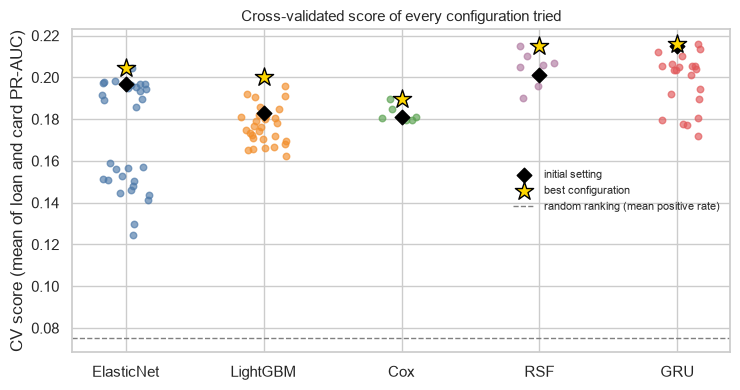

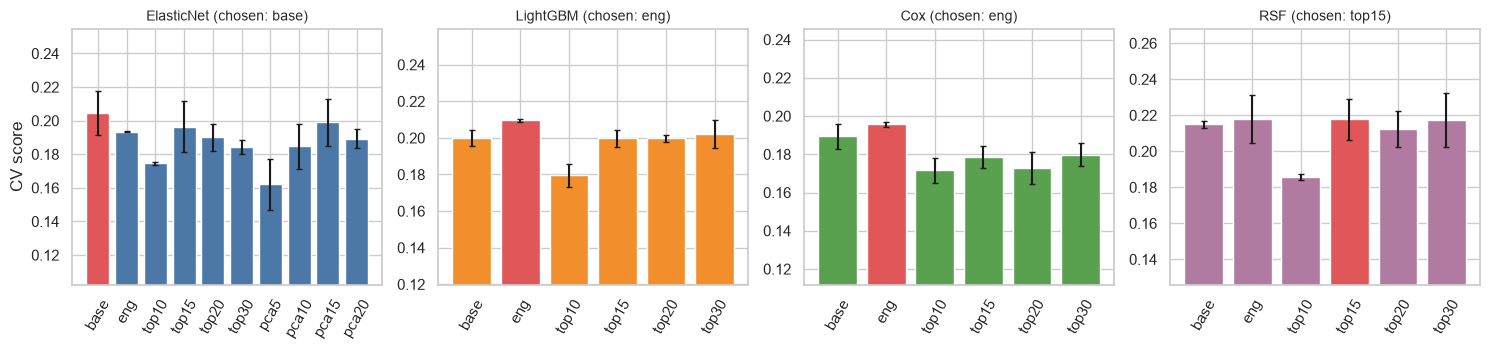

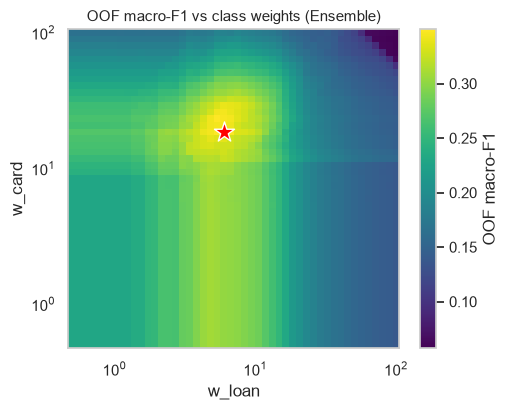

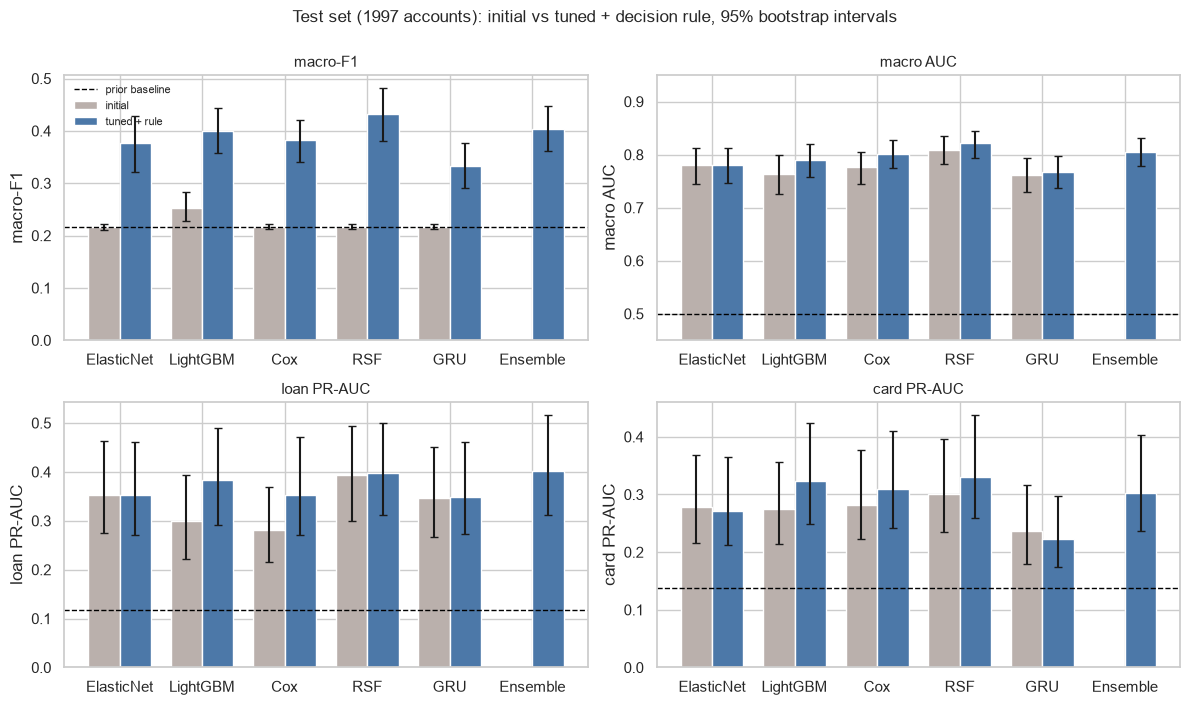

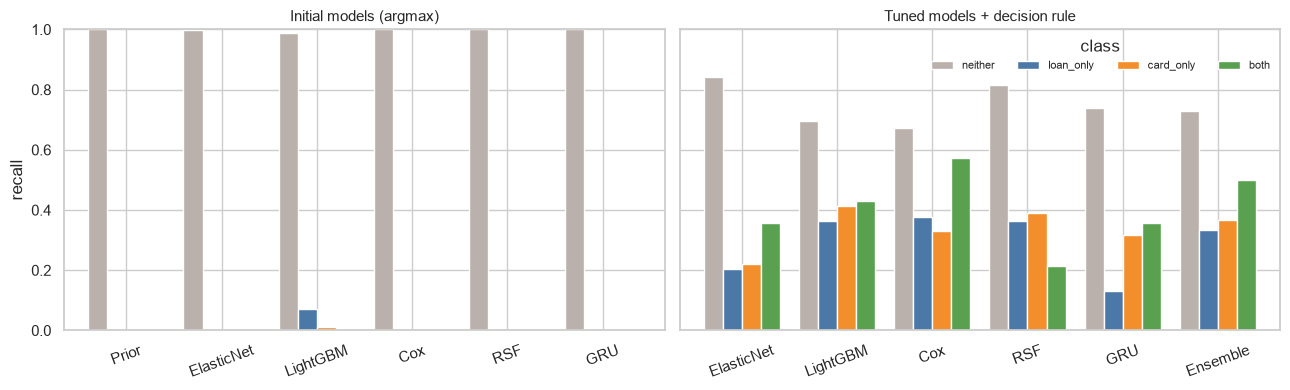

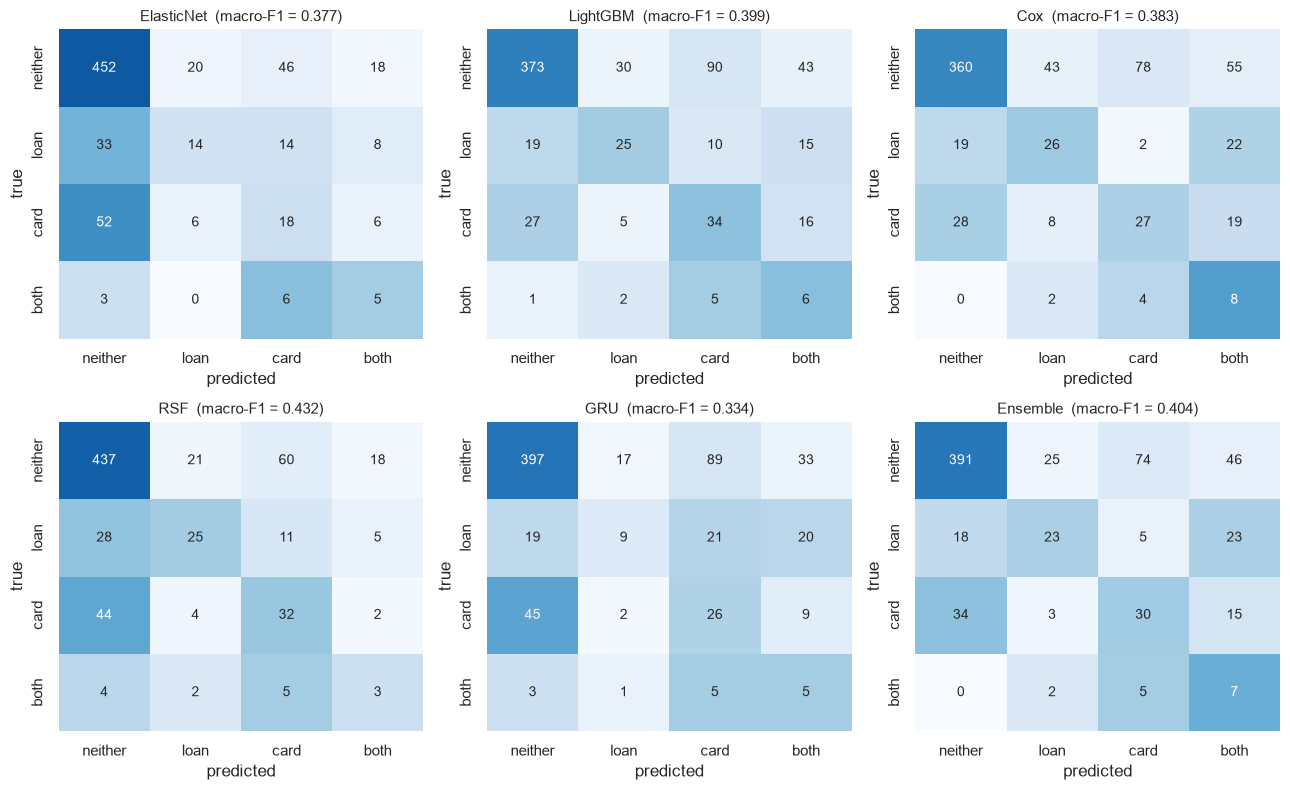

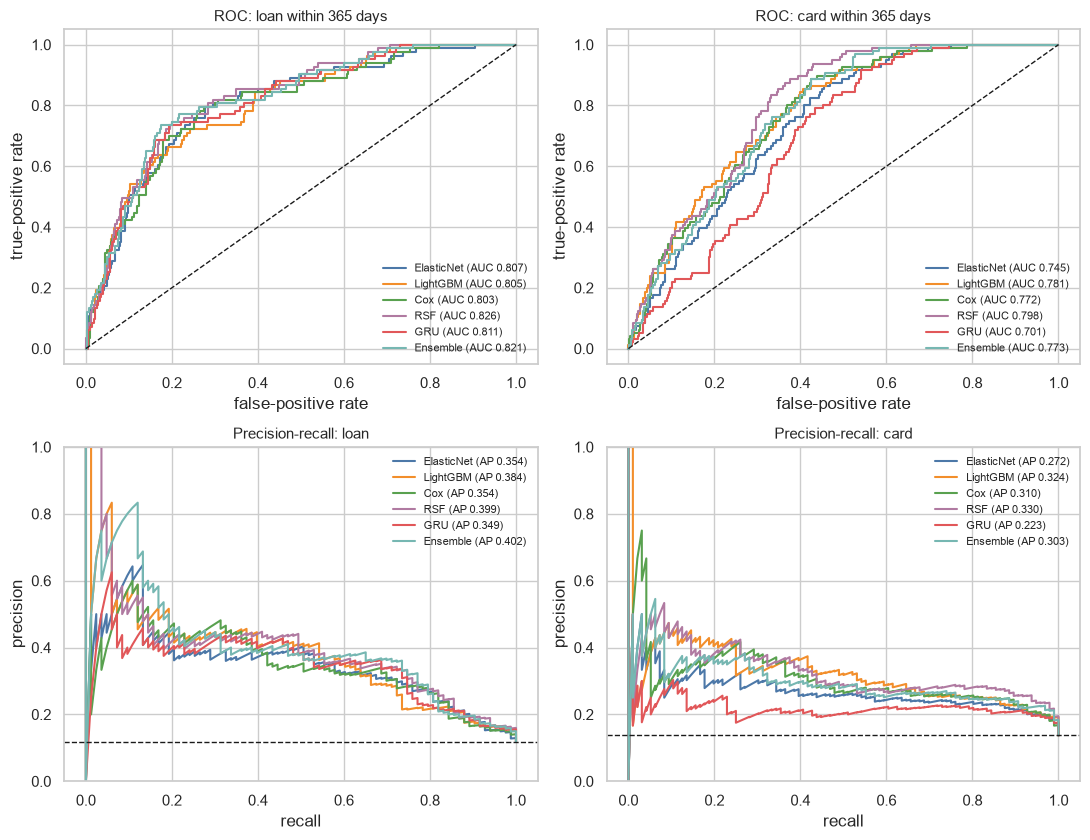

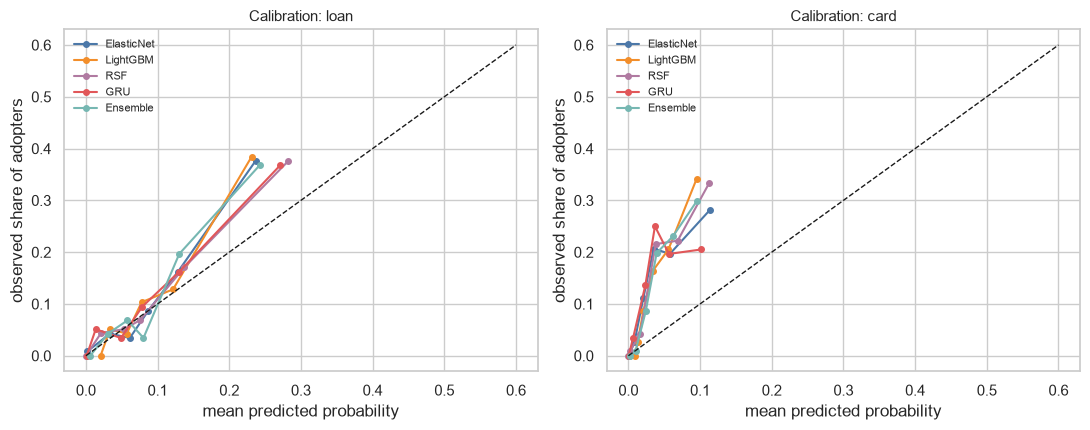

In [49]:
# ---- 6.3 Figures for the report: optimization (CV) and final evaluation
PAL = {"ElasticNet LR": "#4C78A8", "LightGBM": "#F28E2B", "Cox": "#59A14F", "RSF": "#B07AA1", "RMTPP-style GRU": "#E15759", "Ensemble": "#76B7B2", "Prior baseline": "#BAB0AC"}
SHORT_NAMES = {"ElasticNet LR": "ElasticNet", "LightGBM": "LightGBM", "Cox": "Cox", "RSF": "RSF", "RMTPP-style GRU": "GRU", "Ensemble": "Ensemble", "Prior baseline": "Prior"}

# (1) hyperparameter search results per model (CV score of every configuration)
fig, ax = plt.subplots(figsize=(7.5, 4))
rate = np.mean([(np.isin(S["y"]["val"], [1, 3]).mean() + np.isin(S["y"]["val"], [2, 3]).mean()) / 2 for S in FOLDS])
for k, m in enumerate(MODELS):
    sc = SEARCH[m]["score"].values; jit = np.random.default_rng(k).uniform(-0.17, 0.17, len(sc))
    ax.scatter(np.full(len(sc), k) + jit, sc, s=22, alpha=0.65, color=PAL[m])
    ax.scatter(k, INIT_CV[m]["score"], marker="D", s=55, color="black", zorder=3, label="initial setting" if k == 0 else None)
    ax.scatter(k, sc.max(), marker="*", s=190, color="gold", edgecolor="black", zorder=4, label="best configuration" if k == 0 else None)
ax.axhline(rate, color="grey", ls="--", lw=1, label="random ranking (mean positive rate)")
ax.set_xticks(range(len(MODELS))); ax.set_xticklabels([SHORT_NAMES[m] for m in MODELS]); ax.set(ylabel="CV score (mean of loan and card PR-AUC)", title="Cross-validated score of every configuration tried")
ax.legend(frameon=False, fontsize=8); plt.tight_layout(); save_fig("fig_cv_search"); plt.show()

# (2) feature-set comparison
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, m in zip(axes, FS_MODELS):
    d = FS[FS["model"] == m].reset_index(drop=True)
    ax.bar(d["view"], d["score"], yerr=d["score_sd"], capsize=2, color=["#E15759" if v == VIEW[m] else PAL[m] for v in d["view"]])
    ax.set_ylim(max(0, d["score"].min() - 0.06), d["score"].max() + 0.05); ax.set_title(f"{SHORT_NAMES[m]} (chosen: {VIEW[m]})", fontsize=10); ax.tick_params(axis="x", rotation=60)
axes[0].set_ylabel("CV score"); plt.tight_layout(); save_fig("fig_feature_sets"); plt.show()

# (3) decision-rule surface (OOF macro-F1) for the CV-selected model
f1_grid = DEC[FINAL_NAME][2]
fig, ax = plt.subplots(figsize=(5.2, 4.2))
pc_ = ax.pcolormesh(W_GRID, W_GRID, f1_grid.T, shading="auto", cmap="viridis")
ax.set_xscale("log"); ax.set_yscale("log"); ax.scatter(W[FINAL_NAME][1], W[FINAL_NAME][2], marker="*", s=230, color="red", edgecolor="white")  # red star = selected weights (named in the paper caption; no in-plot legend)
ax.set(xlabel="w_loan", ylabel="w_card", title=f"OOF macro-F1 vs class weights ({SHORT_NAMES[FINAL_NAME]})")
plt.colorbar(pc_, label="OOF macro-F1"); plt.tight_layout(); save_fig("fig_decision_rule"); plt.show()

# (4) initial vs tuned + rule on the test set, with 95% bootstrap intervals
base_rates = [None, 0.5, np.isin(y_test, [1, 3]).mean(), np.isin(y_test, [2, 3]).mean()]
base_pt = PT["Prior baseline | initial"]
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for j, (ax, name) in enumerate(zip(axes.ravel(), METRIC_NAMES)):
    names = MODELS + ["Ensemble"]; x = np.arange(len(names)); wd = 0.38
    for off, var, col in [(-wd / 2, "initial", "#BAB0AC"), (wd / 2, "tuned + rule", "#4C78A8")]:
        vals, errs, xs = [], [[], []], []
        for i, m in enumerate(names):
            key = f"{m} | {var}"
            if key not in PT: continue
            lo, hi = np.percentile(BOOT[key][:, j], [2.5, 97.5]); vals.append(PT[key][j]); xs.append(x[i] + off); errs[0].append(max(PT[key][j] - lo, 0)); errs[1].append(max(hi - PT[key][j], 0))
        ax.bar(xs, vals, wd, yerr=errs, capsize=3, color=col, label=var)
    ref = base_pt[j] if j == 0 else base_rates[j]
    ax.axhline(ref, color="black", ls="--", lw=1, label="prior baseline" if j == 0 else "random ranking")
    ax.set_xticks(x); ax.set_xticklabels([SHORT_NAMES[m] for m in names]); ax.set(title=name, ylabel=name)
    if j == 1: ax.set_ylim(0.45, 0.95)
    if j == 0: ax.legend(frameon=False, fontsize=8)
plt.suptitle("Test set (1997 accounts): initial vs tuned + decision rule, 95% bootstrap intervals", y=1.0); plt.tight_layout(); save_fig("fig_initial_vs_tuned"); plt.show()

# (5) per-class recall before and after
rec_cols = [f"recall_{c}" for c in CLASS_NAMES]
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
left = final_tbl.loc[[("Prior baseline", "initial")] + [(m, "initial") for m in MODELS], rec_cols].astype(float); left.index = [SHORT_NAMES[a] for a, _ in left.index]
right = final_tbl.loc[[(m, "tuned + rule") for m in TUNED_ORDER], rec_cols].astype(float); right.index = [SHORT_NAMES[a] for a, _ in right.index]
for ax, d, t in [(axes[0], left, "Initial models (argmax)"), (axes[1], right, "Tuned models + decision rule")]:
    d.rename(columns=lambda c: c.replace("recall_", "")).plot(kind="bar", ax=ax, width=0.8, color=["#BAB0AC", "#4C78A8", "#F28E2B", "#59A14F"]); ax.set(title=t, ylim=(0, 1)); ax.tick_params(axis="x", rotation=20)
axes[0].set_ylabel("recall"); axes[0].legend_.remove(); axes[1].legend(title="class", ncol=4, frameon=False, fontsize=8)
plt.tight_layout(); save_fig("fig_recall_before_after"); plt.show()

# (6) confusion matrices of the tuned models with the decision rule
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, m in zip(axes.ravel(), TUNED_ORDER):
    pred = (TEST_P[m] * W[m]).argmax(1); cm = confusion_matrix(y_test, pred, labels=[0, 1, 2, 3])
    sns.heatmap(cm / cm.sum(1, keepdims=True), annot=cm, fmt="d", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax, xticklabels=SHORT, yticklabels=SHORT)
    ax.set(title=f"{SHORT_NAMES[m]}  (macro-F1 = {f1_score(y_test, pred, average='macro', labels=[0, 1, 2, 3], zero_division=0):.3f})", xlabel="predicted", ylabel="true")
plt.tight_layout(); save_fig("fig_confusion_tuned"); plt.show()

# (7) ROC and precision-recall curves for the two products
fig, axes = plt.subplots(2, 2, figsize=(11, 8.5))
for col, (prod, pos) in enumerate([("loan", [1, 3]), ("card", [2, 3])]):
    yb = np.isin(y_test, pos).astype(int)
    for m in TUNED_ORDER:
        s = TEST_P[m][:, pos[0]] + TEST_P[m][:, 3]
        fpr, tpr, _ = roc_curve(yb, s); pr_, rc_, _ = precision_recall_curve(yb, s)
        axes[0, col].plot(fpr, tpr, color=PAL[m], label=f"{SHORT_NAMES[m]} (AUC {roc_auc_score(yb, s):.3f})"); axes[1, col].plot(rc_, pr_, color=PAL[m], label=f"{SHORT_NAMES[m]} (AP {average_precision_score(yb, s):.3f})")
    axes[0, col].plot([0, 1], [0, 1], "k--", lw=1); axes[0, col].set(title=f"ROC: {prod} within {HORIZON_DAYS} days", xlabel="false-positive rate", ylabel="true-positive rate")
    axes[1, col].axhline(yb.mean(), color="k", ls="--", lw=1); axes[1, col].set(title=f"Precision-recall: {prod}", xlabel="recall", ylabel="precision", ylim=(0, 1))
    axes[0, col].legend(frameon=False, fontsize=8, loc="lower right"); axes[1, col].legend(frameon=False, fontsize=8, loc="upper right")
plt.tight_layout(); save_fig("fig_roc_pr"); plt.show()

# (8) calibration: predicted vs observed adoption probability (shows the prior shift between 1993-96 and 1997)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, (prod, pos) in zip(axes, [("loan", [1, 3]), ("card", [2, 3])]):
    yb = np.isin(y_test, pos).astype(int)
    for m in ["ElasticNet LR", "LightGBM", "RSF", "RMTPP-style GRU", "Ensemble"]:
        s = TEST_P[m][:, pos[0]] + TEST_P[m][:, 3]; fr, mp = calibration_curve(yb, s, n_bins=6, strategy="quantile")
        ax.plot(mp, fr, "o-", color=PAL[m], label=SHORT_NAMES[m], ms=4)
    ax.plot([0, 0.6], [0, 0.6], "k--", lw=1); ax.set(title=f"Calibration: {prod}", xlabel="mean predicted probability", ylabel="observed share of adopters"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); save_fig("fig_calibration"); plt.show()

,LightGBM gain (%),permutation importance (drop in test macro AUC)
bal_range,17.343,0.070
amt_max,16.663,0.061
cash_intensity,5.939,0.025
share_cash_dep,4.847,0.018
age_at_open,4.529,0.007
income_vs_district,3.877,0.009
gap_cv,3.527,0.002
avg_credit,3.161,0.004
large_txn_ratio,3.111,0.001
amt_median,2.500,0.002


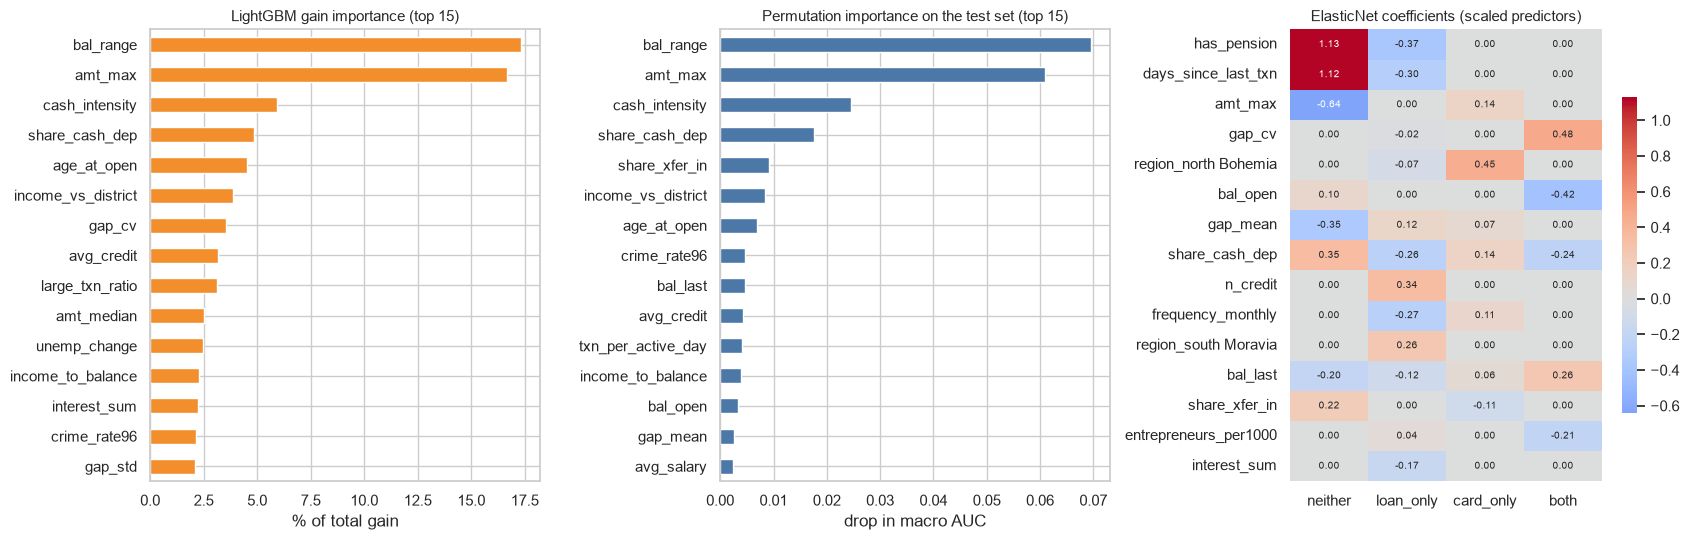

In [45]:
# ---- 6.4 What drives the predictions? (final LightGBM and ElasticNet, trained on all training accounts)
lg_model, lg_view = TEST_MODEL["LightGBM"], BEST["LightGBM"]["view"]
X_lg_te = get_X(S_FINAL, "tree", lg_view, "test")
gain = pd.Series(lg_model.set_params(importance_type="gain").feature_importances_, index=X_lg_te.columns); gain = 100 * gain / gain.sum()
perm = permutation_importance(lg_model, X_lg_te, y_test, scoring="roc_auc_ovr", n_repeats=3 if FAST_MODE else 10, random_state=RANDOM_STATE, n_jobs=1)
perm_s = pd.Series(perm.importances_mean, index=X_lg_te.columns)
imp_tbl = pd.DataFrame({"LightGBM gain (%)": gain, "permutation importance (drop in test macro AUC)": perm_s}).sort_values("LightGBM gain (%)", ascending=False)
display(imp_tbl.head(15).round(4)); save_table(imp_tbl, "tab_importance_lightgbm")

en_model, en_view = TEST_MODEL["ElasticNet LR"], BEST["ElasticNet LR"]["view"]
fig, axes = plt.subplots(1, 3 if not en_view.startswith("pca") else 2, figsize=(17 if not en_view.startswith("pca") else 12, 5.5))
k = min(15, len(gain))
gain.sort_values().tail(k).plot.barh(ax=axes[0], color="#F28E2B"); axes[0].set(title=f"LightGBM gain importance (top {k})", xlabel="% of total gain")
perm_s.sort_values().tail(k).plot.barh(ax=axes[1], color="#4C78A8"); axes[1].set(title=f"Permutation importance on the test set (top {k})", xlabel="drop in macro AUC")
if not en_view.startswith("pca"):
    coef = pd.DataFrame(en_model.coef_.T, index=get_X(S_FINAL, "scaled", en_view, "train").columns, columns=CLASS_NAMES)
    top_c = coef.abs().max(axis=1).sort_values(ascending=False).head(15).index
    sns.heatmap(coef.loc[top_c], cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, cbar_kws={"shrink": 0.7}, ax=axes[2]); axes[2].set(title="ElasticNet coefficients (scaled predictors)")
    save_table(coef, "tab_elasticnet_coefficients")
plt.tight_layout(); save_fig("fig_importance"); plt.show()

In [46]:
# ---- 6.5 Stability across random seeds (LightGBM, Random Survival Forest and the GRU; the decision weights stay those learned in Section 5.3)
def seed_runs():
    out = {}
    for s in SEEDS:
        pl, _ = fp_lgbm(S_FINAL, BEST["LightGBM"]["params"], BEST["LightGBM"]["view"], "test", seed=s)
        pr, _ = fp_rsf(S_FINAL, BEST["RSF"]["params"], BEST["RSF"]["view"], "test", seed=s)
        out[s] = {"LightGBM": pl, "RSF": pr, "RMTPP-style GRU": GRU_TEST[s][0] if HEAD == "class" else GRU_TEST[s][1]}
    return out
SEED_P = cached("seed_runs", seed_runs)
rows = {}
for m in ["LightGBM", "RSF", "RMTPP-style GRU"]:
    arr = np.array([quick_metrics(y_test, SEED_P[s][m], W[m]) for s in SEEDS])
    rows[m] = {**{f"{n} mean": arr[:, j].mean() for j, n in enumerate(METRIC_NAMES)}, **{f"{n} sd": arr[:, j].std(ddof=1) for j, n in enumerate(METRIC_NAMES)}}
seed_tbl = pd.DataFrame(rows).T
print(f"Tuned model + decision rule over {len(SEEDS)} seeds {SEEDS}:"); display(seed_tbl.round(3)); save_table(seed_tbl, "tab_seed_stability")

[cache] 'seed_runs' loaded from opt_cache.pkl
Tuned model + decision rule over 5 seeds [42, 1, 2, 3, 4]:


,macro-F1 mean,macro AUC mean,loan PR-AUC mean,card PR-AUC mean,macro-F1 sd,macro AUC sd,loan PR-AUC sd,card PR-AUC sd
LightGBM,0.399,0.790,0.384,0.324,0.000,0.000,0.000,0.000
RSF,0.422,0.822,0.403,0.335,0.009,0.003,0.004,0.009
RMTPP-style GRU,0.370,0.772,0.396,0.251,0.028,0.008,0.035,0.029


## 7. Conclusions, limitations and future work

The cell below prints the headline numbers of the run. The interpretation in the report is written from these outputs.

**Limitations that apply to all results.**

* **Small positive classes.** The test set holds 83 loan adopters, 96 card adopters and only 14 `both` accounts, so macro-F1 and the `both` recall are noisy; the bootstrap intervals above quantify this.
* **Prior shift.** The 1997 cohort adopts products faster (23.5% within 365 days) than the 1993-96 training cohorts (12.5%). Rank metrics (AUC, PR-AUC) are robust to this, but absolute probabilities are under-estimated (calibration figure) and the class-weight rule learned on 1995-96 validation folds may under-correct for 1997.
* **Look-ahead in training labels.** Training and validation labels and survival times are observed up to December 1998, i.e. after some of the test cohort's landmark dates. Test labels are never used in training.
* **Independence approximation.** The survival models combine loan and card probabilities as independent events, which probably understates `both`.
* **Single bank, single period.** The Berka data cover one Czech bank in the 1990s; adoption is also shaped by the bank's own approval decisions and roll-out of cards.
* **Tuning noise.** With two validation folds and few positives, the best configuration is partly selected by noise; the seed and bootstrap analyses show how much of each difference is reliable.

**Future work.** More cohorts or banks for validation, calibrated probabilities (for example, isotonic calibration on a later validation year), cost-sensitive decision rules using campaign costs, and a sequence model that predicts the *time* of adoption in addition to the product.

In [47]:
# ---- Headline numbers of this run (used for the report)
tb = final_tbl[["macro_f1", "ovr_auc_macro", "loan_prauc", "card_prauc"]].astype(float)
print(f"Test set: {len(y_test)} accounts | loan positives {int(np.isin(y_test, [1, 3]).sum())} | card positives {int(np.isin(y_test, [2, 3]).sum())} | both {int((y_test == 3).sum())}")
print(f"Prior baseline: macro-F1 {tb.loc[('Prior baseline', 'initial')]['macro_f1']:.3f}\n")
for m in TUNED_ORDER:
    ini = tb.loc[(m, "initial")] if (m, "initial") in tb.index else None; tun = tb.loc[(m, "tuned + rule")]
    s = f"{m:16s} macro-F1 {tun['macro_f1']:.3f}" + (f" (initial {ini['macro_f1']:.3f})" if ini is not None else "") + f" | macro AUC {tun['ovr_auc_macro']:.3f}" + (f" (initial {ini['ovr_auc_macro']:.3f})" if ini is not None else "")
    print(s + f" | loan PR-AUC {tun['loan_prauc']:.3f} | card PR-AUC {tun['card_prauc']:.3f} | weights w_loan {W[m][1]:.1f}, w_card {W[m][2]:.1f}")
print(f"\nModel selected by cross-validation: {FINAL_NAME}")
fm = final_tbl.loc[(FINAL_NAME, "tuned + rule")]
print(f"Its test recall per class: " + ", ".join(f"{c} {fm['recall_' + c]:.2f}" for c in CLASS_NAMES))

Test set: 701 accounts | loan positives 83 | card positives 96 | both 14
Prior baseline: macro-F1 0.217

ElasticNet LR    macro-F1 0.377 (initial 0.216) | macro AUC 0.780 (initial 0.780) | loan PR-AUC 0.354 | card PR-AUC 0.272 | weights w_loan 4.3, w_card 13.1
LightGBM         macro-F1 0.399 (initial 0.254) | macro AUC 0.790 (initial 0.763) | loan PR-AUC 0.384 | card PR-AUC 0.324 | weights w_loan 6.7, w_card 23.1
Cox              macro-F1 0.383 (initial 0.217) | macro AUC 0.802 (initial 0.777) | loan PR-AUC 0.354 | card PR-AUC 0.310 | weights w_loan 7.5, w_card 18.4
RSF              macro-F1 0.432 (initial 0.217) | macro AUC 0.821 (initial 0.809) | loan PR-AUC 0.399 | card PR-AUC 0.330 | weights w_loan 3.0, w_card 11.7
RMTPP-style GRU  macro-F1 0.334 (initial 0.217) | macro AUC 0.767 (initial 0.762) | loan PR-AUC 0.349 | card PR-AUC 0.223 | weights w_loan 5.3, w_card 20.6
Ensemble         macro-F1 0.404 | macro AUC 0.805 | loan PR-AUC 0.402 | card PR-AUC 0.303 | weights w_loan 6.0, w_c

In [48]:
# ---- Package figures and tables for the report (upload report_bundle.zip together with this executed notebook)
import zipfile, platform, subprocess, sys
import sklearn, lightgbm, lifelines, sksurv
try:
    torch_v = subprocess.run([sys.executable, "-c", "import torch; print(torch.__version__)"], capture_output=True, text=True, timeout=120).stdout.strip()
except Exception:
    torch_v = "unknown"
info = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__, "lightgbm": lightgbm.__version__,
        "lifelines": lifelines.__version__, "scikit-survival": sksurv.__version__, "torch": torch_v, "FAST_MODE": FAST_MODE, "N_BOOT": N_BOOT, "SEEDS": SEEDS,
        "RANDOM_STATE": RANDOM_STATE, "HORIZON_DAYS": HORIZON_DAYS, "LANDMARK_DAYS": LANDMARK_DAYS, "n_train": int(len(train_ids)), "n_test": int(len(test_ids))}
json.dump(info, open(RES_DIR / "run_info.json", "w"), indent=2)
with zipfile.ZipFile("report_bundle.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for folder in [FIG_DIR, RES_DIR]:
        for f in sorted(folder.rglob("*")):
            if f.is_file(): z.write(f)
    z.write(OUT_DIR / "preprocessing_info.json")
print(f"report_bundle.zip written: {len(list(FIG_DIR.glob('*.pdf')))} figures (PDF + PNG) and {len(list(RES_DIR.glob('*.csv')))} tables (CSV)")

report_bundle.zip written: 23 figures (PDF + PNG) and 26 tables (CSV)


## References

* Berka, P. (1999). PKDD'99 Discovery Challenge: financial data set (anonymized transactions of a Czech bank).
* Bergstra, J., & Bengio, Y. (2012). Random search for hyper-parameter optimization. *Journal of Machine Learning Research*, 13, 281-305.
* Cho, K., et al. (2014). Learning phrase representations using RNN encoder-decoder for statistical machine translation. *EMNLP*.
* Cox, D. R. (1972). Regression models and life-tables. *Journal of the Royal Statistical Society B*, 34(2), 187-220.
* Davidson-Pilon, C. (2019). lifelines: survival analysis in Python. *Journal of Open Source Software*, 4(40), 1317.
* Du, N., et al. (2016). Recurrent marked temporal point processes: embedding event history to vector. *KDD*.
* Efron, B., & Tibshirani, R. (1993). *An Introduction to the Bootstrap*. Chapman & Hall.
* Ishwaran, H., et al. (2008). Random survival forests. *The Annals of Applied Statistics*, 2(3), 841-860.
* Ke, G., et al. (2017). LightGBM: a highly efficient gradient boosting decision tree. *NeurIPS*, 30.
* Paszke, A., et al. (2019). PyTorch: an imperative style, high-performance deep learning library. *NeurIPS*, 32.
* Pedregosa, F., et al. (2011). Scikit-learn: machine learning in Python. *Journal of Machine Learning Research*, 12, 2825-2830.
* Polsterl, S. (2020). scikit-survival: a library for time-to-event analysis built on top of scikit-learn. *Journal of Machine Learning Research*, 21(212), 1-6.
* Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLoS ONE*, 10(3), e0118432.
* Zou, H., & Hastie, T. (2005). Regularization and variable selection via the elastic net. *Journal of the Royal Statistical Society B*, 67(2), 301-320.